# **Momentum Factor Optimization**

This project evaluates a monthly rebalanced, market-capitalisation-weighted momentum strategy across five prescribed lookback periods: 21, 63, 126, 189 and 252 trading days. The objective is to identify which lookback produces the highest annualised Sharpe ratio under the portfolio rules in the challenge.

At the first trading day of each month, stocks are ranked using closing prices and market capitalisations available on the immediately preceding trading day. The strategy selects exactly 10 holdings. New positions are drawn from the highest-ranked eligible stocks, while existing holdings are retained if they remain within the top 12. This retention buffer reduces unnecessary turnover without changing the required portfolio size.

Portfolio weights are based on market capitalisation and are subject to an iterative 20% maximum target allocation per stock. The backtest begins on the first trading day of 2006, uses pre-2006 observations only to initialise momentum signals, and continues through the final available trading day.

- Rebalancing frequency: Monthly
- Portfolio size: Exactly 10 stocks
- Selection rule: Highest momentum ranks, with a rank-12 retention buffer for existing holdings
- Weighting method: Market-capitalisation weighted, subject to a 20% maximum target weight
- Risk-free rate: 0%
- Optimisation objective: Highest annualised Sharpe ratio across the five prescribed lookbacks

All momentum scores and target weights use information available on the calculation date immediately preceding each rebalance. Trades are assumed to be executed at the rebalance-date close, so the new target weights affect returns from the following trading day.

## **Phase 1: Data Audit and Quality Assessment**

Before constructing the momentum strategy, it is important to establish whether the input data is complete, consistent, and suitable for quantitative analysis.

The audit covers:

1. File structure and data types
2. Date parsing, ordering, and duplicate observations
3. Stock-universe consistency across both datasets
4. Missing, non-numeric, zero, and negative values
5. Alignment of price and market-cap observations
6. Historical coverage and availability of initial lookback data
7. Extreme daily price and market-cap changes
8. Potential corporate-action and data-quality anomalies

No observations will be removed or modified automatically. Any anomalies will be investigated before a correction is considered.

In [61]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display
from google.colab import drive

# Step 1: Mount Google Drive
drive.mount("/content/drive")

# Step 2: Specify the folder containing your CSV files.
# Change this path if your files are stored in a different folder.
DATA_DIR = Path("/content/drive/MyDrive/Momentum Factor Optimization")

PRICE_FILE = DATA_DIR / "Test_price_data.csv"
MCAP_FILE = DATA_DIR / "Test_mcap_data.csv"

# Step 3: Confirm that both files exist.
for file_path in [PRICE_FILE, MCAP_FILE]:
    if not file_path.exists():
        raise FileNotFoundError(
            f"File not found: {file_path}\n"
            "Check the folder path and filename in Google Drive."
        )

print("Both input files located successfully.")

# Step 4: Load the raw datasets without modifying the original files.
prices_raw = pd.read_csv(PRICE_FILE)
market_caps_raw = pd.read_csv(MCAP_FILE)

# Step 5: Inspect the raw price data.
print("=" * 70)
print("RAW DATA INSPECTION")
print("=" * 70)

print("\nPRICE DATA")
print("Shape:", prices_raw.shape)
print("Columns:", prices_raw.columns.tolist())
print("\nData types:")
print(prices_raw.dtypes)
display(prices_raw.head())

# Step 6: Inspect the raw market-cap data.
print("\nMARKET CAPITALIZATION DATA")
print("Shape:", market_caps_raw.shape)
print("Columns:", market_caps_raw.columns.tolist())
print("\nData types:")
print(market_caps_raw.dtypes)
display(market_caps_raw.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Both input files located successfully.
RAW DATA INSPECTION

PRICE DATA
Shape: (5337, 31)
Columns: ['date', 'AEGS.NS', 'ARTI.NS', 'ASHT.NS', 'BOB.NS', 'BRIT.NS', 'CEMI.NS', 'CHPC.NS', 'GENS.NS', 'GICH.NS', 'HEGL.NS', 'HLVL.NS', 'IMCL.NS', 'JAAO.NS', 'JKIN.NS', 'KAMT.NS', 'MDRD.BO', 'NALU.NS', 'OSGL.NS', 'SEAM.NS', 'TAJG.NS', 'TANE.BO', 'THOM.NS', 'TVEL.NS', 'VENK.NS', 'VSTI.NS', 'WHEL.NS', 'WIPR.NS', 'WRRN.BO', 'WSTC.NS', 'XPRO.NS']

Data types:
date        object
AEGS.NS    float64
ARTI.NS    float64
ASHT.NS    float64
BOB.NS     float64
BRIT.NS    float64
CEMI.NS    float64
CHPC.NS    float64
GENS.NS    float64
GICH.NS    float64
HEGL.NS    float64
HLVL.NS    float64
IMCL.NS    float64
JAAO.NS    float64
JKIN.NS    float64
KAMT.NS    float64
MDRD.BO    float64
NALU.NS    float64
OSGL.NS    float64
SEAM.NS    float64
TAJG.NS    float64
TANE.BO    float64
THOM

,date,AEGS.NS,ARTI.NS,ASHT.NS,BOB.NS,BRIT.NS,CEMI.NS,CHPC.NS,GENS.NS,GICH.NS,...,TANE.BO,THOM.NS,TVEL.NS,VENK.NS,VSTI.NS,WHEL.NS,WIPR.NS,WRRN.BO,WSTC.NS,XPRO.NS
0,03-01-2005,2.45,6.85,295.56,31.21,69.82,17.93,128.17,9.51,15.26,...,18.98,9.78,64.60,49.51,9.52,63.65,28.66,58.26,29.65,18.12
1,04-01-2005,2.69,6.69,305.43,31.35,69.79,17.27,131.51,9.46,15.35,...,18.38,9.94,68.48,49.07,9.63,63.40,28.47,62.72,28.40,18.16
2,05-01-2005,2.58,6.41,299.59,29.00,67.87,16.48,128.62,9.04,14.54,...,16.56,9.81,63.07,47.56,9.68,61.60,120.82,26.99,26.87,3.72
3,06-01-2005,2.47,6.10,298.91,27.88,67.57,15.81,127.04,9.02,13.96,...,15.48,9.75,61.59,47.15,9.60,60.47,26.20,61.37,26.43,17.06
4,07-01-2005,2.45,6.14,294.33,28.10,67.58,16.10,127.07,9.04,14.25,...,17.02,9.77,62.90,46.82,9.74,58.75,26.59,61.07,27.96,16.82



MARKET CAPITALIZATION DATA
Shape: (5337, 31)
Columns: ['date', 'AEGS.NS', 'ARTI.NS', 'ASHT.NS', 'BOB.NS', 'BRIT.NS', 'CEMI.NS', 'CHPC.NS', 'GENS.NS', 'GICH.NS', 'HEGL.NS', 'HLVL.NS', 'IMCL.NS', 'JAAO.NS', 'JKIN.NS', 'KAMT.NS', 'MDRD.BO', 'NALU.NS', 'OSGL.NS', 'SEAM.NS', 'TAJG.NS', 'TANE.BO', 'THOM.NS', 'TVEL.NS', 'VENK.NS', 'VSTI.NS', 'WHEL.NS', 'WIPR.NS', 'WRRN.BO', 'WSTC.NS', 'XPRO.NS']

Data types:
date        object
AEGS.NS    float64
ARTI.NS    float64
ASHT.NS    float64
BOB.NS     float64
BRIT.NS    float64
CEMI.NS    float64
CHPC.NS    float64
GENS.NS    float64
GICH.NS    float64
HEGL.NS    float64
HLVL.NS    float64
IMCL.NS    float64
JAAO.NS    float64
JKIN.NS    float64
KAMT.NS    float64
MDRD.BO    float64
NALU.NS    float64
OSGL.NS    float64
SEAM.NS    float64
TAJG.NS    float64
TANE.BO    float64
THOM.NS    float64
TVEL.NS    float64
VENK.NS    float64
VSTI.NS    float64
WHEL.NS    float64
WIPR.NS    float64
WRRN.BO    float64
WSTC.NS    float64
XPRO.NS    float64
dtype

,date,AEGS.NS,ARTI.NS,ASHT.NS,BOB.NS,BRIT.NS,CEMI.NS,CHPC.NS,GENS.NS,GICH.NS,...,TANE.BO,THOM.NS,TVEL.NS,VENK.NS,VSTI.NS,WHEL.NS,WIPR.NS,WRRN.BO,WSTC.NS,XPRO.NS
0,2005-01-03,9.330473e+08,4.429240e+09,7.501232e+09,7.203974e+10,2.226683e+10,1.221660e+09,3.470377e+10,2.869370e+08,2.578057e+08,...,381409875.0,6.612083e+09,1.306021e+09,8.504055e+08,3.738489e+09,2.961327e+09,5.289428e+11,1.152403e+09,2.033558e+09,415593750.0
1,2005-01-04,1.026189e+09,4.340655e+09,7.687081e+09,7.249429e+10,2.234566e+10,1.197015e+09,3.555274e+10,2.869370e+08,9.343160e+08,...,369227250.0,6.713437e+09,1.382898e+09,8.311528e+08,3.885187e+09,2.949977e+09,5.257130e+11,1.240679e+09,1.931187e+09,416601250.0
2,2005-01-05,9.902394e+08,4.153171e+09,7.545699e+09,6.690766e+10,2.185353e+10,1.111103e+09,3.457716e+10,9.411597e+08,8.925814e+08,...,332679375.0,6.615729e+09,1.277745e+09,8.095522e+08,3.692935e+09,2.866087e+09,4.958378e+11,1.181293e+09,1.806464e+09,393932500.0
3,2005-01-06,9.379495e+08,3.953552e+09,7.525176e+09,6.438561e+10,2.167554e+10,1.105114e+09,3.432396e+10,2.753936e+08,8.495006e+08,...,311125500.0,6.545000e+09,1.252119e+09,8.025085e+08,3.690619e+09,2.813285e+09,4.840422e+11,1.213929e+09,1.796630e+09,390406250.0
4,2005-01-07,9.322303e+08,3.998451e+09,7.411158e+09,6.489881e+10,2.147367e+10,1.146803e+09,3.426438e+10,2.731948e+08,8.737335e+08,...,342050625.0,6.534792e+09,1.269792e+09,7.996911e+08,3.860480e+09,2.733343e+09,4.910985e+11,1.208044e+09,1.903918e+09,380331250.0


In [62]:
# Preserve the original DataFrames. Work on copies.
prices_clean = prices_raw.copy()
mcap_clean = market_caps_raw.copy()

# Explicitly parse the different date formats supplied.
prices_clean["date"] = pd.to_datetime(
    prices_clean["date"],
    format="%d-%m-%Y",
    errors="coerce"
)

mcap_clean["date"] = pd.to_datetime(
    mcap_clean["date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Report failed date conversions.
print("Invalid price dates:", prices_clean["date"].isna().sum())
print("Invalid market-cap dates:", mcap_clean["date"].isna().sum())

assert prices_clean["date"].notna().all(), (
    "Invalid dates detected in the price dataset."
)
assert mcap_clean["date"].notna().all(), (
    "Invalid dates detected in the market-cap dataset."
)

price_stocks = set(prices_clean.columns) - {"date"}
mcap_stocks = set(mcap_clean.columns) - {"date"}

print("\nPrice stock count:", len(price_stocks))
print("Market-cap stock count:", len(mcap_stocks))
print("Stocks only in prices:", sorted(price_stocks - mcap_stocks))
print("Stocks only in market caps:", sorted(mcap_stocks - price_stocks))

assert price_stocks == mcap_stocks, (
    "The stock universes do not match."
)

print("\nStock universe validation passed.")

Invalid price dates: 0
Invalid market-cap dates: 0

Price stock count: 30
Market-cap stock count: 30
Stocks only in prices: []
Stocks only in market caps: []

Stock universe validation passed.


In [63]:
# Audit dates and duplicate observations

def date_audit(df, dataset_name):
    dates = df["date"]

    result = {
        "Dataset": dataset_name,
        "Observations": len(df),
        "Unique dates": dates.nunique(),
        "Duplicate date rows": int(dates.duplicated().sum()),
        "First date": dates.min(),
        "Last date": dates.max(),
        "Chronologically sorted": dates.is_monotonic_increasing,
    }

    return result

date_audit_results = pd.DataFrame([
    date_audit(prices_clean, "Prices"),
    date_audit(mcap_clean, "Market capitalization"),
])

display(date_audit_results)

assert not prices_clean["date"].duplicated().any(), (
    "Duplicate price dates detected."
)

assert not mcap_clean["date"].duplicated().any(), (
    "Duplicate market-cap dates detected."
)

# Sort chronologically after checking the original ordering.
prices_clean = prices_clean.sort_values("date").reset_index(drop=True)
mcap_clean = mcap_clean.sort_values("date").reset_index(drop=True)

print("Date uniqueness validated. Data sorted chronologically.")

,Dataset,Observations,Unique dates,Duplicate date rows,First date,Last date,Chronologically sorted
0,Prices,5337,5337,0,2005-01-03,2026-06-24,True
1,Market capitalization,5337,5337,0,2005-01-03,2026-06-24,True


Date uniqueness validated. Data sorted chronologically.


In [64]:
# Missing values, non-numeric values, and invalid observations

def value_quality_audit(df, dataset_name):
    stock_data = df.drop(columns="date")

    # Inspect original data types and conversion failures.
    numeric_data = stock_data.apply(
        pd.to_numeric, errors="coerce"
    )

    missing_original = stock_data.isna().sum().sum()
    non_numeric = (
        stock_data.notna() & numeric_data.isna()
    ).sum().sum()

    values = numeric_data.to_numpy(dtype=float)

    return{
        "Dataset": dataset_name,
        "Missing values": int(missing_original),
        "Non-numeric values": int(non_numeric),
        "Infinite values":  int(np.isinf(values).sum()),
        "Zero values": int((numeric_data == 0).sum().sum()),
        "Negative values": int((numeric_data < 0).sum().sum()),
    }

value_quality_results = pd.DataFrame([
    value_quality_audit(prices_clean, "Prices"),
    value_quality_audit(mcap_clean, "Market capitalization"),
])

display(value_quality_results)

# Convert numeric columns only after reporting conversion issues.
price_values = prices_clean.drop(columns="date").apply(
    pd.to_numeric, errors="coerce"
)

mcap_values = mcap_clean.drop(columns="date").apply(
    pd.to_numeric, errors="coerce"
)

assert not price_values.isna().any().any(), (
    "Missing or non-numeric price values require investigation."
)
assert not mcap_values.isna().any().any(), (
    "Missing or non-numeric market-cap values require investigation."
)
assert np.isfinite(price_values.to_numpy(dtype=float)).all()
assert np.isfinite(mcap_values.to_numpy(dtype=float)).all()
assert (price_values > 0).all().all()
assert (mcap_values > 0). all().all()

print("Numeric and positive-value checks passed.")

,Dataset,Missing values,Non-numeric values,Infinite values,Zero values,Negative values
0,Prices,0,0,0,0,0
1,Market capitalization,0,0,0,0,0


Numeric and positive-value checks passed.


In [65]:
# Align both datasets by date

prices = (
    prices_clean.set_index("date")
    .drop(columns=[])
    .sort_index()
    .astype(float)
)

market_caps = (
    mcap_clean.set_index("date")
    .sort_index()
    .astype(float)
)

# Check both the date index and stock columns.
price_dates = prices.index
mcap_dates = market_caps.index

print("Price observations:", len(price_dates))
print("Market-cap observations:", len(mcap_dates))
print("Dates only in prices:", len(price_dates.difference(mcap_dates)))
print("Dates only in market caps:", len(mcap_dates.difference(price_dates)))

assert prices.index.equals(market_caps.index), (
    "Dates differ between datasets."
)
assert prices.columns.equals(market_caps.columns), (
    "Stocks column order differs between datasets."
)

print("\nAligned datasets:", prices.shape)
print("First observation:", prices.index.min().date())
print("Last observation:", prices.index.max().date())

Price observations: 5337
Market-cap observations: 5337
Dates only in prices: 0
Dates only in market caps: 0

Aligned datasets: (5337, 30)
First observation: 2005-01-03
Last observation: 2026-06-24


In [66]:
# Validate backtest history and lookback availability

BACKTEST_START = pd.Timestamp("2006-01-01")
LOOKBACKS = [21, 63, 126, 189, 252]

backtest_dates = prices.index[prices.index >= BACKTEST_START]

if len(backtest_dates) == 0:
    raise ValueError("No observations are available from 2006 onward.")

first_backtest_date = backtest_dates[0]
last_backtest_date = backtest_dates[-1]

first_position = prices.index.get_loc(first_backtest_date)

history_audit = {
    "First available observation": prices.index.min().date(),
    "First backtest trading day": first_backtest_date.date(),
    "Last available trading day": last_backtest_date.date(),
    "Observations before backtest": first_position,
    "Observations in backtest": len(backtest_dates),
    "Maximum lookback required": max(LOOKBACKS),
}

display(pd.Series(history_audit, name="Audit result").to_frame())

assert first_position >= max(LOOKBACKS), (
    "Insufficient pre-backtest history for the maximum lookback."
)

print("\nInitial lookback history is available.")
print("No portfolio performance will be measured before 2006.")

,Audit result
First available observation,2005-01-03
First backtest trading day,2006-01-02
Last available trading day,2026-06-24
Observations before backtest,253
Observations in backtest,5084
Maximum lookback required,252



Initial lookback history is available.
No portfolio performance will be measured before 2006.


In [67]:
# Detect extreme daily movements

price_returns = prices.pct_change(fill_method=None)
mcap_returns = market_caps.pct_change(fill_method=None)

# Use explicit diagnostic thresholds, not automatic deletion rules.
thresholds = [0.10, 0.20, 0.50, 1.00]

summary = []

for threshold in thresholds:
    summary.append({
        "Absolute move threshold": f"{threshold:.0%}",
        "Price observations": int(
            price_returns.abs().gt(threshold).sum().sum()
        ),
        "Market-cap observations":int(
            mcap_returns.abs().gt(threshold).sum().sum()
        ),
    })

display(pd.DataFrame(summary))

,Absolute move threshold,Price observations,Market-cap observations
0,10%,11654,11670
1,20%,9861,9844
2,50%,9132,9099
3,100%,4236,4236


In [68]:
# Inspect the largest individual movements and their subsequent reversals.

def extreme_moves(returns, prices, market_caps, top_n=30):
    records = []

    for ticker in returns.columns:
        series = returns[ticker].dropna()

        for date, ret in series.items():
            if not np.isfinite(ret):
                continue

            records.append({
                "Date": date,
                "Ticker": ticker,
                "Daily return": ret,
                "Previous price": prices.at[
                    prices.index[prices.index.get_loc(date) - 1], ticker
                ],
                "Current price": prices.at[date, ticker],
                "Market-cap return": mcap_returns.at[date, ticker],
            })

    result = pd.DataFrame(records)

    return(
        result.assign(
            Absolute_return=lambda x: x["Daily return"].abs()
        )
        .sort_values("Absolute_return", ascending=False)
        .head(top_n)
        .drop(columns="Absolute_return")
        .reset_index(drop=True)
    )

extreme_observations = extreme_moves(
    price_returns, prices, market_caps, top_n=30
)

display(extreme_observations)


,Date,Ticker,Daily return,Previous price,Current price,Market-cap return
0,2013-11-05,GICH.NS,24.361020,15.29,387.77,0.038744
1,2008-07-01,THOM.NS,17.243194,5.51,100.52,-0.037403
2,2020-08-17,VENK.NS,14.310073,359.56,5504.89,0.025804
3,2021-02-11,TANE.BO,14.287548,7.79,119.09,0.003021
4,2013-12-17,XPRO.NS,11.686239,5.45,69.14,-0.042910
5,2011-07-12,VENK.NS,11.658415,128.87,1631.29,-0.047031
6,2017-07-21,CHPC.NS,11.007890,68.44,821.82,0.014241
7,2023-04-20,JAAO.NS,10.890187,53.91,641.00,-0.014476
8,2013-01-04,TANE.BO,10.687050,5.56,64.98,-0.005906
9,2023-12-18,XPRO.NS,10.573218,237.85,2752.69,0.047354


### Data Audit Conclusion

The audit evaluates data integrity before any portfolio construction or performance optimization.

The conclusion must distinguish between:

- Checks that passed, such as date alignment and completeness.
- Observations requiring further investigation, such as extreme price movements or possible corporate-action effects.
- Limitations that cannot be resolved from the supplied files alone.

No outlier is automatically removed. Any adjustment must be supported by evidence and applied consistently across the backtest.

The data will be approved for strategy construction only after material anomalies have been investigated and portfolio returns are understood.

### Investigation of Extreme Price Movements

The preliminary audit identified unusually large daily price changes.

This section investigates whether these movements represent:
- Potential stock splits or reverse splits.
- Corporate-action-related price adjustments.
- Temporary price-data errors.
- Persistent market-capitalization inconsistencies.

For each flagged observation, examine the surrounding trading days, price movements, and market-capitalization movements.

No observations are removed or adjusted at this stage.

In [69]:
# Identify observations with absolute daily price returns above 50%.
anomaly_mask = price_returns.abs() > 0.50

anomaly_dates = (
    price_returns.where(anomaly_mask)
    .stack()
    .index
)

print("Total flagged observations:", len(anomaly_dates))

def investigate_anomaly(ticker, event_date, window=3):

    position = prices.index.get_loc(event_date)

    start = max(0, position - window)
    end = min(len(prices), position + window + 1)

    dates = prices.index[start:end]

    investigation = pd.DataFrame({
        "Price": prices.loc[dates, ticker],
        "Market Cap": market_caps.loc[dates, ticker],
        "Price Return": price_returns.loc[dates, ticker],
        "Market Cap Return": mcap_returns.loc[dates, ticker]
    })

    investigation.index.name = "Date"

    print(f"\nTicker: {ticker}")
    print(f"Event date: {event_date.date()}")

    display(investigation)

# Examine the first 10 largest anomalies.
for _, row in extreme_observations.head(10).iterrows():

    investigate_anomaly(
        ticker=row["Ticker"],
        event_date=row["Date"],
        window=3
    )

Total flagged observations: 9132

Ticker: GICH.NS
Event date: 2013-11-05


,Price,Market Cap,Price Return,Market Cap Return
Date,,,,
2013-10-31,73.50,5.352796e+09,-0.005009,-0.005005
2013-11-01,75.38,5.490116e+09,0.025578,0.025654
2013-11-03,15.29,5.490116e+09,-0.797161,0.000000
2013-11-05,387.77,5.702828e+09,24.361020,0.038744
2013-11-06,76.75,5.589741e+09,-0.802073,-0.019830
2013-11-07,74.72,5.441650e+09,-0.026450,-0.026493
2013-11-08,73.54,5.355489e+09,-0.015792,-0.015834



Ticker: THOM.NS
Event date: 2008-07-01


,Price,Market Cap,Price Return,Market Cap Return
Date,,,,
2008-06-26,22.38,1.214710e+10,0.020985,0.013414
2008-06-27,22.22,1.218730e+10,-0.007149,0.003309
2008-06-30,5.51,1.139143e+10,-0.752025,-0.065303
2008-07-01,100.52,1.096535e+10,17.243194,-0.037403
2008-07-02,20.44,1.119045e+10,-0.796657,0.020528
2008-07-03,20.27,1.101359e+10,-0.008317,-0.015805
2008-07-04,20.51,1.124672e+10,0.011840,0.021168



Ticker: VENK.NS
Event date: 2020-08-17


,Price,Market Cap,Price Return,Market Cap Return
Date,,,,
2020-08-12,1117.45,1.612859e+10,0.032888,0.032884
2020-08-13,1340.91,1.935389e+10,0.199973,0.199974
2020-08-14,359.56,1.905312e+10,-0.731854,-0.015540
2020-08-17,5504.89,1.954477e+10,14.310073,0.025804
2020-08-18,1372.97,1.981666e+10,-0.750591,0.013911
2020-08-19,1359.35,1.962014e+10,-0.009920,-0.009917
2020-08-20,1335.83,1.928063e+10,-0.017302,-0.017304


... (10 outputs left out)


Ticker: TANE.BO
Event date: 2013-01-04


,Price,Market Cap,Price Return,Market Cap Return
Date,,,,
2013-01-01,23.83,6.369803e+08,0.021870,0.022000
2013-01-02,23.74,6.344872e+08,-0.003777,-0.003914
2013-01-03,5.56,6.332407e+08,-0.765796,-0.001965
2013-01-04,64.98,6.295011e+08,10.687050,-0.005906
2013-01-07,22.99,6.145426e+08,-0.646199,-0.023762
2013-01-08,23.32,6.232684e+08,0.014354,0.014199
2013-01-09,22.67,6.058169e+08,-0.027873,-0.028000



Ticker: XPRO.NS
Event date: 2023-12-18


,Price,Market Cap,Price Return,Market Cap Return
Date,,,,
2023-12-13,988.42,2.050687e+10,0.038529,0.038526
2023-12-14,590.71,2.148156e+10,-0.402369,0.047530
2023-12-15,237.85,2.335550e+10,-0.597349,0.087235
2023-12-18,2752.69,2.446147e+10,10.573218,0.047354
2023-12-19,1124.82,2.333690e+10,-0.591374,-0.045973
2023-12-20,1121.88,2.327591e+10,-0.002614,-0.002613
2023-12-21,1157.80,2.402115e+10,0.032018,0.032017


In [70]:
# Identify possible price reversals

reversal_candidates = []

for ticker in prices.columns:

    returns = price_returns[ticker]

    for i in range(1, len(returns) - 1):

        previous_return = returns.iloc[i]
        next_return = returns.iloc[i + 1]

        if pd.isna(previous_return) or pd.isna(next_return):
            continue

        if(
            abs(previous_return) > 0.50
            and abs(next_return) > 0.50
            and np.sign(previous_return) !=np.sign(next_return)
        ):

            reversal_candidates.append({
                "Ticker": ticker,
                "Event Date": returns.index[i],
                "First Return": previous_return,
                "Next Day Return": next_return,
                "Price Before": prices[ticker].iloc[i - 1],
                "Price After": prices[ticker].iloc[i + 1]
            })

reversal_df = pd.DataFrame(reversal_candidates)

if not reversal_df.empty:
    display(
        reversal_df.sort_values(
            "Event Date"
        ).reset_index(drop=True)
    )
else:
    print("No consecutive extreme reversals detected.")

,Ticker,Event Date,First Return,Next Day Return,Price Before,Price After
0,WRRN.BO,2005-01-05,-0.569675,1.273805,62.72,61.37
1,XPRO.NS,2005-01-05,-0.795154,3.586022,18.16,17.06
2,WIPR.NS,2005-01-05,3.243765,-0.783148,28.47,26.20
3,HEGL.NS,2005-01-07,2.027515,-0.675376,11.63,11.43
4,GENS.NS,2005-01-11,3.680043,-0.815064,9.22,7.98
...,...,...,...,...,...,...
4308,TVEL.NS,2026-06-15,-0.785154,3.700929,456.00,460.55
4309,IMCL.NS,2026-06-16,-0.520663,1.055676,385.95,380.30
4310,TAJG.NS,2026-06-16,2.959994,-0.748418,334.45,333.20
4311,NALU.NS,2026-06-17,-0.611673,1.582877,366.65,367.75


In [71]:
# Preserve all flagged price movements for documentation.
anomaly_register = (
    price_returns.where(price_returns.abs() > 0.50)
    .stack()
    .rename("Price Return")
    .reset_index()
)

anomaly_register.columns = [
    "Date", "Ticker", "Price Return"
]

anomaly_register["Market Cap Return"] = [
    mcap_returns.at[date, ticker]
    for date, ticker in zip(
        anomaly_register["Date"],
        anomaly_register["Ticker"]
    )
]

anomaly_register = anomaly_register.sort_values(
    "Price Return",
    key=lambda x: x.abs(),
    ascending=False
)

# Save anomaly register directly to Google Drive folder.
OUTPUT_FILE = DATA_DIR / "price_anomaly_register.csv"

anomaly_register.to_csv(
    OUTPUT_FILE,
    index=False
)

print("Anomaly register saved successfully.")
print("Total flagged observations:", len(anomaly_register))
print("Saved location:", OUTPUT_FILE)


Anomaly register saved successfully.
Total flagged observations: 9132
Saved location: /content/drive/MyDrive/Momentum Factor Optimization/price_anomaly_register.csv


### Quantitative Classification of Price Anomalies

This analysis evaluates whether extreme consecutive-day price movements represent temporary discontinuities.

For each reversal candidate, calculate:

- Two-day cumulative price return.
- Two-day cumulative market-cap return.
- Whether the price approximately returns to its pre-event level.
- Whether market capitalization remains comparatively stable.

This classification is diagnostic only. It does not establish that an observation is erroneous or identify the underlying corporate action.

In [72]:
# Create a structured reversal dataset.
reversal_analysis = reversal_df.copy()

# Calculate cumulative two-day price and market-cap returns.
reversal_analysis["Two-Day Price Return"] = (
    (1 + reversal_analysis["First Return"])
    * (1 + reversal_analysis["Next Day Return"])
    - 1
)

reversal_analysis["Two-Day Market Cap Return"] = [
    (
        (1 + mcap_returns[ticker].loc[event_date])
        * (1 + mcap_returns[ticker].iloc[
            mcap_returns.index.get_loc(event_date) + 1
        ])
        - 1
    )
    for ticker, event_date in zip(
        reversal_analysis["Ticker"],
        reversal_analysis["Event Date"]
    )
]

# Flag approximate price reversals.
reversal_analysis["Near Price Reversal"] = (
    reversal_analysis["Two-Day Price Return"].abs() <= 0.05
)

# Flag relatively stable market capitalization.
reversal_analysis["Stable Market Cap"] = (
    reversal_analysis["Two-Day Market Cap Return"].abs() <= 0.05
)

display(
    reversal_analysis.sort_values(
        "Two-Day Price Return",
        key=lambda x: x.abs()
    ).head(20)
)

,Ticker,Event Date,First Return,Next Day Return,Price Before,Price After,Two-Day Price Return,Two-Day Market Cap Return,Near Price Reversal,Stable Market Cap
1595,IMCL.NS,2005-04-29,-0.657161,1.916821,15.78,15.78,0.000000e+00,6.711409e-03,True,True
802,CEMI.NS,2010-10-01,-0.571229,1.332248,21.48,21.48,0.000000e+00,-5.613126e-03,True,True
775,CEMI.NS,2007-07-13,1.840299,-0.647924,32.06,32.06,0.000000e+00,-3.228236e-03,True,True
2489,OSGL.NS,2009-08-28,-0.670490,2.034810,19.18,19.18,0.000000e+00,-1.887379e-15,True,True
4201,XPRO.NS,2009-04-21,1.144896,-0.533777,9.11,9.11,0.000000e+00,-4.708652e-03,True,True
1557,HLVL.NS,2020-02-26,-0.760000,3.166667,4.00,4.00,0.000000e+00,0.000000e+00,True,True
1569,HLVL.NS,2021-08-26,1.730818,-0.633809,7.95,7.95,0.000000e+00,0.000000e+00,True,True
3643,WHEL.NS,2013-02-14,1.622745,-0.618720,180.70,180.70,0.000000e+00,-1.332268e-15,True,True
1512,HLVL.NS,2014-03-04,2.724590,-0.731514,15.25,15.25,0.000000e+00,4.440892e-15,True,True
1881,JAAO.NS,2022-11-23,2.064883,-0.673723,156.59,156.59,0.000000e+00,0.000000e+00,True,True


In [73]:
# Overall anomaly classification
total_reversals = len(reversal_analysis)

near_reversals = reversal_analysis[
    "Near Price Reversal"
].sum()

stable_mcap = reversal_analysis[
    "Stable Market Cap"
].sum()

both_conditions = (
    reversal_analysis["Near Price Reversal"]
    & reversal_analysis["Stable Market Cap"]
).sum()

classification_summary = pd.DataFrame({
    "Diagnostic": [
        "Total reversal candidates",
        "Price returns within ±5% over two days",
        "Market cap changes within ±5% over two days",
        "Both price and market cap within ±5%"
    ],
    "Count": [
        total_reversals,
        near_reversals,
        stable_mcap,
        both_conditions
    ]
})

classification_summary["Percentage"] = (
    classification_summary["Count"] / total_reversals * 100
)

display(classification_summary)

,Diagnostic,Count,Percentage
0,Total reversal candidates,4313,100.000000
1,Price returns within ±5% over two days,3371,78.159054
2,Market cap changes within ±5% over two days,3312,76.791097
3,Both price and market cap within ±5%,3116,72.246696


In [74]:
# Identify stocks with the highest anomaly concentration
ticker_anomaly_summary = (
    anomaly_register.groupby("Ticker")
    .agg(
        Flagged_Observations=("Price Return", "count"),
        Mean_Absolute_Return=(
            "Price Return",
            lambda x: x.abs().mean()
        ),
        Maximum_Absolute_Return=(
            "Price Return",
            lambda x: x.abs().max()
        )
    )
    .sort_values(
        "Flagged_Observations",
        ascending=False
    )
)

display(ticker_anomaly_summary)

print("\nTop 10 stocks by flagged observations:")
display(ticker_anomaly_summary.head(10))

,Flagged_Observations,Mean_Absolute_Return,Maximum_Absolute_Return
Ticker,,,
THOM.NS,356,1.487519,17.243194
AEGS.NS,349,1.466415,4.244336
WRRN.BO,349,1.455645,6.872381
ASHT.NS,336,1.498761,7.983233
HLVL.NS,335,1.435165,3.881141
JAAO.NS,327,1.466374,10.890187
BOB.NS,326,1.553430,10.539489
TAJG.NS,322,1.485907,6.328409
BRIT.NS,321,1.401361,5.764891



Top 10 stocks by flagged observations:


,Flagged_Observations,Mean_Absolute_Return,Maximum_Absolute_Return
Ticker,,,
THOM.NS,356,1.487519,17.243194
AEGS.NS,349,1.466415,4.244336
WRRN.BO,349,1.455645,6.872381
ASHT.NS,336,1.498761,7.983233
HLVL.NS,335,1.435165,3.881141
JAAO.NS,327,1.466374,10.890187
BOB.NS,326,1.553430,10.539489
TAJG.NS,322,1.485907,6.328409
BRIT.NS,321,1.401361,5.764891


In [75]:
# Compare daily price and market-cap returns.
comparison = pd.DataFrame({
    "Price Return": price_returns.stack(),
    "Market Cap Return": mcap_returns.stack()
}).dropna()

comparison["Absolute Difference"] = (
    comparison["Price Return"]
    - comparison["Market Cap Return"]
).abs()

comparison = comparison.sort_values(
    "Absolute Difference",
    ascending=False
)

display(comparison.head(30))

,,Price Return,Market Cap Return,Absolute Difference
date,,,,
2013-11-05,GICH.NS,24.361020,0.038744,24.322276
2008-07-01,THOM.NS,17.243194,-0.037403,17.280597
2016-10-30,ARTI.NS,0.001305,15.950927,15.949622
2016-11-23,IMCL.NS,0.037826,15.239974,15.202148
2021-02-11,TANE.BO,14.287548,0.003021,14.284527
2020-08-17,VENK.NS,14.310073,0.025804,14.284269
2012-02-21,GICH.NS,0.000631,13.947222,13.946591
2020-11-05,GICH.NS,0.005415,12.834005,12.828590
2013-12-17,XPRO.NS,11.686239,-0.042910,11.729149


In [76]:
reversal_analysis.to_csv(
    DATA_DIR / "reversal_investigation.csv",
    index=False
)

classification_summary.to_csv(
    DATA_DIR / "anomaly_classification_summary.csv",
    index=False
)

ticker_anomaly_summary.to_csv(
    DATA_DIR / "ticker_anomaly_summary.csv"
)

comparison.head(100).to_csv(
    DATA_DIR / "price_mcap_discrepancy_report.csv"
)

print("Investigation outputs saved to:", DATA_DIR)

Investigation outputs saved to: /content/drive/MyDrive/Momentum Factor Optimization


For each reversal candidate, inspect three consecutive trading days:

- Previous trading day
- Event date, when the first extreme return occurred
- Following trading day, when the reversal occurred

Calculate the implied shares-outstanding proxy as market capitalisaion divided by price. Use it only as a diagnostic, not as an independently verified shares-outstanding figure.

In [77]:
# Build an event-level investigation table

event_details = []

for _, row in reversal_analysis.iterrows():

    ticker = row["Ticker"]
    event_date = row["Event Date"]

    position = prices.index.get_loc(event_date)

    previous_date = prices.index[position - 1]
    next_date = prices.index[position + 1]

    price_before = prices.at[previous_date, ticker]
    price_event = prices.at[event_date, ticker]
    price_after = prices.at[next_date, ticker]

    mcap_before = market_caps.at[previous_date, ticker]
    mcap_event = market_caps.at[event_date, ticker]
    mcap_after = market_caps.at[next_date, ticker]

    event_details.append({
        "Ticker": ticker,
        "Previous Date": previous_date,
        "Event Date": event_date,
        "Next Date": next_date,

        "Price Before": price_before,
        "Price On Event": price_event,
        "Price After": price_after,

        "First Day Return": price_event / price_before - 1,
        "Second Day Return": price_after / price_event - 1,

        "Market Cap Before": mcap_before,
        "Market Cap On Event": mcap_event,
        "Market Cap After": mcap_after,

        "Two-Day Price Return": (
            price_after / price_before - 1
        ),

        "Two-Day Market Cap Return": (
            mcap_after / mcap_before - 1
        ),

        "Implied Shares Before": mcap_before / price_before,
        "Implied Shares On Event": mcap_event / price_event,
        "Implied Shares After": mcap_after / price_after
    })

event_details_df = pd.DataFrame(event_details)

# Prioritise events where both price and market cap
# return close to their original levels over two days.

event_details_df["Both Conditions"] = (
    event_details_df["Two-Day Price Return"].abs().le(0.05)
    & event_details_df["Two-Day Market Cap Return"].abs().le(0.05)
)

event_details_df = event_details_df.sort_values(
    by=["Both Conditions", "First Day Return"],
    ascending=[False, False]
)

display(event_details_df.head(30))

,Ticker,Previous Date,Event Date,Next Date,Price Before,Price On Event,Price After,First Day Return,Second Day Return,Market Cap Before,Market Cap On Event,Market Cap After,Two-Day Price Return,Two-Day Market Cap Return,Implied Shares Before,Implied Shares On Event,Implied Shares After,Both Conditions
73,AEGS.NS,2014-11-12,2014-11-13,2014-11-14,32.66,171.28,33.72,4.244336,-0.803129,1.227116e+10,5.737434e+10,1.267029e+10,0.032456,0.032526,3.757244e+08,3.349739e+08,3.757500e+08,True
2145,KAMT.NS,2020-07-07,2020-07-08,2020-07-09,35.20,184.16,35.65,4.231818,-0.806418,8.301588e+08,9.079862e+08,8.407717e+08,0.012784,0.012784,2.358406e+07,4.930420e+06,2.358406e+07,True
1097,GENS.NS,2015-04-09,2015-04-10,2015-04-13,60.58,315.81,61.92,4.213107,-0.803933,1.857298e+09,1.947118e+09,1.898402e+09,0.022120,0.022131,3.065860e+07,6.165474e+06,3.065895e+07,True
1924,JKIN.NS,2007-12-05,2007-12-06,2007-12-07,19.32,100.36,19.86,4.194617,-0.802112,4.134163e+09,4.280437e+09,4.266579e+09,0.027950,0.032030,2.139836e+08,4.265083e+07,2.148328e+08,True
532,BOB.NS,2016-07-08,2016-07-11,2016-07-12,131.94,679.51,137.05,4.150144,-0.798311,3.565687e+11,3.740803e+11,3.703937e+11,0.038730,0.038772,2.702506e+09,5.505148e+08,2.702617e+09,True
1412,HEGL.NS,2023-04-12,2023-04-13,2023-04-17,193.69,994.96,196.82,4.136868,-0.802183,3.882515e+10,4.010073e+10,3.945233e+10,0.016160,0.016154,2.004499e+08,4.030386e+07,2.004488e+08,True
3149,THOM.NS,2021-11-01,2021-11-02,2021-11-03,71.63,367.59,73.11,4.131788,-0.801110,2.690480e+10,2.779667e+10,2.746222e+10,0.020662,0.020718,3.756079e+08,7.561867e+07,3.756287e+08,True
16,AEGS.NS,2007-06-14,2007-06-15,2007-06-18,5.94,30.15,5.92,4.075758,-0.803648,2.209639e+09,2.275062e+09,2.227631e+09,-0.003367,0.008142,3.719932e+08,7.545810e+07,3.762889e+08,True
2882,TANE.BO,2006-08-28,2006-08-29,2006-08-30,133.49,675.94,137.87,4.063600,-0.796032,3.231303e+09,3.392756e+09,3.337433e+09,0.032811,0.032844,2.420633e+07,5.019315e+06,2.420710e+07,True
3083,THOM.NS,2012-11-30,2012-12-03,2012-12-04,20.40,103.11,20.86,4.054412,-0.797692,1.280018e+10,1.301334e+10,1.308794e+10,0.022549,0.022481,6.274598e+08,1.262083e+08,6.274182e+08,True


Now let's isolate the most extreme daily price movements and examine whether the following day's price movement offsets them. This helps us see whether the problem is concentrated in particular dates or repeated throughout the dataset.

In [78]:
# Inspect the most extreme examples

extreme_events = event_details_df.copy()

extreme_events["Absolute First Day Return"] = (
    extreme_events["First Day Return"].abs()
)

extreme_events = extreme_events.sort_values(
    "Absolute First Day Return",
    ascending=False
)

display(
    extreme_events[
        [
            "Ticker",
            "Event Date",
            "Price Before",
            "Price On Event",
            "Price After",
            "First Day Return",
            "Second Day Return",
            "Two-Day Price Return",
            "Two-Day Market Cap Return",
            "Implied Shares Before",
            "Implied Shares On Event",
            "Implied Shares After"
        ]
    ].head(30)
)

,Ticker,Event Date,Price Before,Price On Event,Price After,First Day Return,Second Day Return,Two-Day Price Return,Two-Day Market Cap Return,Implied Shares Before,Implied Shares On Event,Implied Shares After
1224,GICH.NS,2013-11-05,15.29,387.77,76.75,24.361020,-0.802073,4.019621,0.018146,3.590658e+08,1.470673e+07,7.283050e+07
3044,THOM.NS,2008-07-01,5.51,100.52,20.44,17.243194,-0.796657,2.709619,-0.017643,2.067410e+09,1.090863e+08,5.474780e+08
3418,VENK.NS,2020-08-17,359.56,5504.89,1372.97,14.310073,-0.750591,2.818473,0.040074,5.299010e+07,3.550438e+06,1.443342e+07
2978,TANE.BO,2021-02-11,7.79,119.09,30.13,14.287548,-0.746998,2.867779,-0.024169,1.059316e+08,6.950209e+06,2.672628e+07
4226,XPRO.NS,2013-12-17,5.45,69.14,16.87,11.686239,-0.756002,2.095413,-0.048507,5.733479e+07,4.325516e+06,1.762402e+07
3353,VENK.NS,2011-07-12,128.87,1631.29,372.66,11.658415,-0.771555,1.891751,0.005398,4.454923e+07,3.353819e+06,1.548879e+07
988,CHPC.NS,2017-07-21,68.44,821.82,300.02,11.007890,-0.634932,3.383694,0.004442,8.326767e+08,7.033165e+07,1.907924e+08
1885,JAAO.NS,2023-04-20,53.91,641.00,153.77,10.890187,-0.760109,1.852347,-0.032496,9.418475e+07,7.806552e+06,3.194706e+07
2928,TANE.BO,2013-01-04,5.56,64.98,22.99,10.687050,-0.646199,3.134892,-0.029528,1.138922e+08,9.687613e+06,2.673087e+07
4296,XPRO.NS,2023-12-18,237.85,2752.69,1124.82,10.573218,-0.591374,3.729115,-0.000797,9.819425e+07,8.886386e+06,2.074723e+07


We compare the event-day price with both neighbouring prices. A scale factor close to 5 means the event-day price is approximately five times the surrounding price level.

In [79]:
# Quantify the price-scale distortion

scale_analysis = event_details_df.copy()

scale_analysis["Factor vs Previous"] = (
    scale_analysis["Price On Event"] /
    scale_analysis["Price Before"]
)

scale_analysis["Factor vs Next"] = (
    scale_analysis["Price On Event"] /
    scale_analysis["Price After"]
)

# Geometric mean of the two ratios
scale_analysis["Estimated Scale Factor"] = np.sqrt(
    scale_analysis["Factor vs Previous"] *
    scale_analysis["Factor vs Next"]
)

scale_analysis["Near 5x"] = (
    scale_analysis["Estimated Scale Factor"].between(4.75, 5.25)
)

scale_analysis["Near 2x"] = (
    scale_analysis["Estimated Scale Factor"].between(1.90, 2.10)
)

scale_analysis["Near 10x"] = (
    scale_analysis["Estimated Scale Factor"].between(9.50, 10.50)
)

scale_summary = pd.DataFrame({
    "Pattern": ["Approximately 2x", "Approximately 5x", "Approximately 10x"],
    "Count": [
        scale_analysis["Near 2x"].sum(),
        scale_analysis["Near 5x"].sum(),
        scale_analysis["Near 10x"].sum()
    ]
})

scale_summary["Percentage"] = (
    scale_summary["Count"] / len(scale_analysis) * 100
)

display(scale_summary)
print("\n")
display(
    scale_analysis.sort_values(
        "Estimated Scale Factor",
        ascending=False
    )[
        [
            "Ticker",
            "Event Date",
            "Factor vs Previous",
            "Factor vs Next",
            "Estimated Scale Factor",
            "Two-Day Price Return",
            "Two-Day Market Cap Return"
        ]
    ].head(30)
)

,Pattern,Count,Percentage
0,Approximately 2x,85,1.970786
1,Approximately 5x,178,4.127058
2,Approximately 10x,1,0.023186


,Ticker,Event Date,Factor vs Previous,Factor vs Next,Estimated Scale Factor,Two-Day Price Return,Two-Day Market Cap Return
1224,GICH.NS,2013-11-05,25.361020,5.052378,11.319605,4.019621,1.814615e-02
3239,TVEL.NS,2013-01-23,10.393701,8.741722,9.531990,0.188976,-6.285714e-02
3044,THOM.NS,2008-07-01,18.243194,4.917808,9.471881,2.709619,-1.764291e-02
3896,WRRN.BO,2009-10-22,4.885907,14.526283,8.424611,-0.663651,-1.209564e-02
1792,JAAO.NS,2011-10-05,4.234245,15.905312,8.206521,-0.733784,2.546584e-02
495,BOB.NS,2009-09-15,5.069106,12.973507,8.109506,-0.609272,4.511921e-02
3418,VENK.NS,2020-08-17,15.310073,4.009476,7.834882,2.818473,4.007394e-02
2061,KAMT.NS,2008-03-05,3.591789,17.025407,7.819953,-0.789034,-4.392765e-02
2978,TANE.BO,2021-02-11,15.287548,3.952539,7.773328,2.867779,-2.416918e-02
3353,VENK.NS,2011-07-12,12.658415,4.377422,7.443872,1.891751,5.398331e-03


We now examine the number of distinct stocks with suspicious fivefold price movements on each event date. This helps identify whether the anomalies are conentrated on common dates.

In [80]:
# Check whether multiple stocks are affected on the same date

five_x_events = scale_analysis[
    scale_analysis["Near 5x"]
].copy()

date_concentration = (
    five_x_events.groupby("Event Date")
    .agg(
        Affected_Stocks=("Ticker", "nunique"),
        Tickers=("Ticker", lambda x: ", ".join(sorted(x)))
    )
    .sort_values("Affected_Stocks", ascending=False)
)

display(date_concentration.head(30))

print(
    "Fivefold events:",
    len(five_x_events)
)

print(
    "Distinct event dates:",
    five_x_events["Event Date"].nunique()
)

print(
    "Maximum stocks affected on one date:",
    date_concentration["Affected_Stocks"].max()
)

,Affected_Stocks,Tickers
Event Date,,
2020-07-08,2,"KAMT.NS, SEAM.NS"
2016-12-06,2,"THOM.NS, TVEL.NS"
2009-06-10,2,"BOB.NS, CHPC.NS"
2005-07-18,1,MDRD.BO
2005-01-11,1,GENS.NS
2005-05-12,1,BRIT.NS
2005-07-07,1,BRIT.NS
2005-09-23,1,CHPC.NS
2005-11-28,1,KAMT.NS


Fivefold events: 178
Distinct event dates: 175
Maximum stocks affected on one date: 2


A temporary fivefold price distortion should satisfy all of the following:

1. Event-day price is approximately five times the previous day's price.
2. Event-day price is approximately five times the following day's price.
3. Two-day cumulative price return is within ±5%.
4. Two-day market-cap return is within ±5%.

We will also test the inverse pattern, where the event-day price is approximately one-fifth of both neighbouring prices.

In [81]:
# Strict price-scale anomaly classification

strict_analysis = event_details_df.copy()

strict_analysis["Ratio vs Previous"] = (
    strict_analysis["Price On Event"] /
    strict_analysis["Price Before"]
)

strict_analysis["Ratio vs Next"] = (
    strict_analysis["Price On Event"] /
    strict_analysis["Price After"]
)

# Both ratios must independently be close to the same factor.
strict_analysis["Temporary 5x"] = (
    strict_analysis["Ratio vs Previous"].between(4.75, 5.25)
    & strict_analysis["Ratio vs Next"].between(4.75, 5.25)
)

strict_analysis["Temporary 0.2x"] = (
    strict_analysis["Ratio vs Previous"].between(0.19, 0.21)
    & strict_analysis["Ratio vs Next"].between(0.19, 0.21)
)

strict_analysis["Stable Two-Day Price"] = (
    strict_analysis["Two-Day Price Return"].abs() <= 0.05
)

strict_analysis["Stable Two-Day Market Cap"] = (
    strict_analysis["Two-Day Market Cap Return"].abs() <= 0.05
)

strict_analysis["Strong Scale Anomaly"] = (
    (strict_analysis["Temporary 5x"]
     | strict_analysis["Temporary 0.2x"])
    & strict_analysis["Stable Two-Day Price"]
    & strict_analysis["Stable Two-Day Market Cap"]
)

strict_summary = pd.DataFrame({
    "Diagnostic": [
        "Temporary approximately 5x price",
        "Temporary approximately 0.2x price",
        "Stable two-day price and market cap",
        "Strong scale anomaly meeting all conditions"
    ],
    "Count": [
        strict_analysis["Temporary 5x"].sum(),
        strict_analysis["Temporary 0.2x"].sum(),
        (
            strict_analysis["Stable Two-Day Price"]
            & strict_analysis["Stable Two-Day Market Cap"]
        ).sum(),
        strict_analysis["Strong Scale Anomaly"].sum()
    ]
})

strict_summary["Percentage"] = (
    strict_summary["Count"] / len(strict_analysis) * 100
)

display(strict_summary)
print("\n")
display(
    strict_analysis[
        strict_analysis["Strong Scale Anomaly"]
    ][
        [
            "Ticker",
            "Event Date",
            "Price Before",
            "Price On Event",
            "Price After",
            "Ratio vs Previous",
            "Ratio vs Next",
            "Two-Day Price Return",
            "Two-Day Market Cap Return"
        ]
    ].head(30)
)

,Diagnostic,Count,Percentage
0,Temporary approximately 5x price,121,2.805472
1,Temporary approximately 0.2x price,55,1.275214
2,Stable two-day price and market cap,3115,72.223510
3,Strong scale anomaly meeting all conditions,150,3.477858


,Ticker,Event Date,Price Before,Price On Event,Price After,Ratio vs Previous,Ratio vs Next,Two-Day Price Return,Two-Day Market Cap Return
73,AEGS.NS,2014-11-13,32.66,171.28,33.72,5.244336,5.079478,0.032456,0.032526
2145,KAMT.NS,2020-07-08,35.20,184.16,35.65,5.231818,5.165778,0.012784,0.012784
1097,GENS.NS,2015-04-10,60.58,315.81,61.92,5.213107,5.100291,0.022120,0.022131
1924,JKIN.NS,2007-12-06,19.32,100.36,19.86,5.194617,5.053374,0.027950,0.032030
532,BOB.NS,2016-07-11,131.94,679.51,137.05,5.150144,4.958117,0.038730,0.038772
1412,HEGL.NS,2023-04-13,193.69,994.96,196.82,5.136868,5.055177,0.016160,0.016154
3149,THOM.NS,2021-11-02,71.63,367.59,73.11,5.131788,5.027903,0.020662,0.020718
16,AEGS.NS,2007-06-15,5.94,30.15,5.92,5.075758,5.092905,-0.003367,0.008142
2882,TANE.BO,2006-08-29,133.49,675.94,137.87,5.063600,4.902734,0.032811,0.032844
3083,THOM.NS,2012-12-03,20.40,103.11,20.86,5.054412,4.942953,0.022549,0.022481


In [82]:
# Check whether the anomalies are concentrated in particular stocks

strong_anomaly_by_ticker = (
    strict_analysis[
        strict_analysis["Strong Scale Anomaly"]
    ]
    .groupby("Ticker")
    .agg(
        Strong_Anomalies=("Event Date", "count"),
        First_Event=("Event Date", "min"),
        Last_Event=("Event Date", "max")
    )
    .sort_values("Strong_Anomalies", ascending=False)
)

display(strong_anomaly_by_ticker)

print(
    "Total stocks affected:",
    len(strong_anomaly_by_ticker)
)

print(
    "Total strong anomalies:",
    strict_analysis["Strong Scale Anomaly"].sum()
)

,Strong_Anomalies,First_Event,Last_Event
Ticker,,,
IMCL.NS,9,2007-08-01,2024-07-15
ARTI.NS,8,2006-06-22,2023-10-23
BRIT.NS,7,2005-07-07,2026-05-22
HEGL.NS,7,2005-05-12,2023-04-17
BOB.NS,7,2006-03-06,2016-07-11
THOM.NS,7,2012-04-03,2025-01-28
GENS.NS,6,2006-05-09,2023-12-06
JKIN.NS,6,2005-09-16,2021-01-01
SEAM.NS,6,2007-06-12,2025-06-17


Total stocks affected: 29
Total strong anomalies: 150


In [83]:
# Measure momentum-signal exposure to strong anomalies

# Identify strong anomaly observations by ticker and date
strong_anomaly_keys = set(
    zip(
        strict_analysis.loc[
            strict_analysis["Strong Scale Anomaly"], "Ticker"
        ],
        pd.to_datetime(
            strict_analysis.loc[
                strict_analysis["Strong Scale Anomaly"], "Event Date"
            ]
        )
    )
)

# First trading day of each month from the start of 2006
rebalance_dates = (
    prices.groupby(prices.index.to_period("M"))
    .head(1)
    .index
)

rebalance_dates = rebalance_dates[
    rebalance_dates >= pd.Timestamp("2006-01-01")
]

lookbacks = [21, 63, 126, 189, 252]

signal_exposure = []

for rebalance_date in rebalance_dates:

    rebalance_position = prices.index.get_loc(rebalance_date)

    # Calculation date is the immediately preceding trading day
    calc_position = rebalance_position - 1

    if calc_position < 0:
        continue

    calc_date = prices.index[calc_position]

    for lookback in lookbacks:

        lookback_position = calc_position - lookback

        if lookback_position < 0:
            continue

        lookback_start_date = prices.index[lookback_position]

        for ticker in prices.columns:

            numerator_anomaly = (
                (ticker, calc_date) in strong_anomaly_keys
            )

            denominator_anomaly = (
                (ticker, lookback_start_date) in strong_anomaly_keys
            )

            signal_exposure.append({
                "Rebalance Date": rebalance_date,
                "Calculation Date": calc_date,
                "Lookback": lookback,
                "Ticker": ticker,
                "Numerator Anomaly": numerator_anomaly,
                "Denominator Anomaly": denominator_anomaly,
                "Either Endpoint Anomaly": (
                    numerator_anomaly or denominator_anomaly
                )

            })

signal_exposure_df = pd.DataFrame(signal_exposure)

# Summarise affected stock-level momentum observations
signal_exposure_summary = (
    signal_exposure_df
    .groupby("Lookback")
    .agg(
        Total_Signal_Observations=("Ticker", "count"),
        Numerator_Anomalies=("Numerator Anomaly", "sum"),
        Denominator_Anomalies=("Denominator Anomaly", "sum"),
        Either_Endpoint_Anomalies=("Either Endpoint Anomaly", "sum")
    )
)

signal_exposure_summary["Affected Percentage"] = (
    signal_exposure_summary["Either_Endpoint_Anomalies"]
    / signal_exposure_summary["Total_Signal_Observations"]
    * 100
)

display(signal_exposure_summary.round(3))

,Total_Signal_Observations,Numerator_Anomalies,Denominator_Anomalies,Either_Endpoint_Anomalies,Affected Percentage
Lookback,,,,,
21,7380,6,6,12,0.163
63,7380,6,7,13,0.176
126,7380,6,9,15,0.203
189,7380,6,5,11,0.149
252,7380,6,3,9,0.122


In [84]:
# Build a set of anomaly dates for each stock
anomaly_dates_by_ticker = {
    ticker: set(
        strict_analysis.loc[
            (strict_analysis["Ticker"] == ticker)
            & strict_analysis["Strong Scale Anomaly"],
            "Event Date"
        ]
    )
    for ticker in prices.columns
}

window_exposure = []

for rebalance_date in rebalance_dates:

    rebalance_position = prices.index.get_loc(rebalance_date)
    calc_position = rebalance_position - 1

    if calc_position < 0:
        continue

    calc_date = prices.index[calc_position]

    for lookback in lookbacks:

        start_position = calc_position - lookback

        if start_position < 0:
            continue

        window_dates = set(
            prices.index[start_position:calc_position + 1]
        )

        for ticker in prices.columns:

            anomalies_in_window = (
                window_dates & anomaly_dates_by_ticker[ticker]
            )

            window_exposure.append({
                "Rebalance Date": rebalance_date,
                "Calculation Date": calc_date,
                "Lookback": lookback,
                "Ticker": ticker,
                "Anomaly Count in Window": len(anomalies_in_window),
                "Has Anomaly in Window": len(anomalies_in_window) > 0
            })

window_exposure_df = pd.DataFrame(window_exposure)

window_exposure_summary = (
    window_exposure_df
    .groupby("Lookback")
    .agg(
        Total_Signal_Observations=("Ticker", "count"),
        Affected_Signals=("Has Anomaly in Window", "sum"),
        Total_Anomaly_Events=("Anomaly Count in Window", "sum")
    )
)

window_exposure_summary["Affected Percentage"] = (
    window_exposure_summary["Affected_Signals"]
    / window_exposure_summary["Total_Signal_Observations"]
    * 100
)

display(window_exposure_summary.round(3))

,Total_Signal_Observations,Affected_Signals,Total_Anomaly_Events,Affected Percentage
Lookback,,,,
21,7380,148,152,2.005
63,7380,422,445,5.718
126,7380,813,885,11.016
189,7380,1187,1332,16.084
252,7380,1551,1780,21.016


In [85]:
# Include both the initial price jump and the following-day reversal
anomaly_dates_by_ticker = {}

for ticker in prices.columns:

    ticker_events = strict_analysis[
        (strict_analysis["Ticker"] == ticker)
        & strict_analysis["Strong Scale Anomaly"]
    ]

    affected_dates = set(ticker_events["Event Date"])
    affected_dates.update(ticker_events["Next Date"])

    anomaly_dates_by_ticker[ticker] = affected_dates


# Recalculate lookback-window exposure
expanded_window_exposure = []

for rebalance_date in rebalance_dates:

    rebalance_position = prices.index.get_loc(rebalance_date)
    calc_position = rebalance_position - 1

    if calc_position < 0:
        continue

    for lookback in lookbacks:

        start_position = calc_position - lookback

        if start_position < 0:
            continue

        window_dates = set(
            prices.index[start_position:calc_position + 1]
        )

        for ticker in prices.columns:

            anomalies_in_window = (
                window_dates & anomaly_dates_by_ticker[ticker]
            )

            expanded_window_exposure.append({
                "Rebalance Date": rebalance_date,
                "Lookback": lookback,
                "Ticker": ticker,
                "Affected Dates in Window": len(anomalies_in_window),
                "Has Anomaly in Window": len(anomalies_in_window) > 0
            })


expanded_window_exposure_df = pd.DataFrame(
    expanded_window_exposure
)

expanded_exposure_summary = (
    expanded_window_exposure_df
    .groupby("Lookback")
    .agg(
        Total_Signal_Observations=("Ticker", "count"),
        Affected_Signals=("Has Anomaly in Window", "sum"),
        Total_Affected_Dates=("Affected Dates in Window", "sum")
    )
)

expanded_exposure_summary["Affected Percentage"] = (
    expanded_exposure_summary["Affected_Signals"]
    / expanded_exposure_summary["Total_Signal_Observations"]
    * 100
)

display(expanded_exposure_summary.round(3))

,Total_Signal_Observations,Affected_Signals,Total_Affected_Dates,Affected Percentage
Lookback,,,,
21,7380,154,303,2.087
63,7380,429,888,5.813
126,7380,819,1764,11.098
189,7380,1191,2653,16.138
252,7380,1553,3545,21.043


In [86]:
# Include the jump date and the following reversal date
affected_dates_by_ticker = {}

for ticker in prices.columns:
    ticker_events = strict_analysis[
        (strict_analysis["Ticker"] == ticker)
        & strict_analysis["Strong Scale Anomaly"]
    ]

    affected_dates = set(ticker_events["Event Date"])
    affected_dates.update(ticker_events["Next Date"])

    affected_dates_by_ticker[ticker] = affected_dates


endpoint_exposure = []

for rebalance_date in rebalance_dates:

    rebalance_position = prices.index.get_loc(rebalance_date)
    calc_position = rebalance_position - 1

    if calc_position < 0:
        continue

    calc_date = prices.index[calc_position]

    for lookback in lookbacks:

        start_position = calc_position - lookback

        if start_position < 0:
            continue

        start_date = prices.index[start_position]

        for ticker in prices.columns:

            affected_dates = affected_dates_by_ticker[ticker]

            numerator_affected = calc_date in affected_dates
            denominator_affected = start_date in affected_dates

            endpoint_exposure.append({
                "Lookback": lookback,
                "Ticker": ticker,
                "Numerator Affected": numerator_affected,
                "Denominator Affected": denominator_affected,
                "Either Endpoint Affected": (
                    numerator_affected or denominator_affected
                )
            })


endpoint_exposure_df = pd.DataFrame(endpoint_exposure)

endpoint_exposure_summary = (
    endpoint_exposure_df
    .groupby("Lookback")
    .agg(
        Total_Signals=("Ticker", "count"),
        Numerator_Affected=("Numerator Affected", "sum"),
        Denominator_Affected=("Denominator Affected", "sum"),
        Either_Endpoint_Anomalies=("Either Endpoint Affected", "sum")
    )
)

endpoint_exposure_summary["Affected Percentage"] = (
    endpoint_exposure_summary["Either_Endpoint_Anomalies"]
    / endpoint_exposure_summary["Total_Signals"]
    * 100
)

display(endpoint_exposure_summary.round(3))


,Total_Signals,Numerator_Affected,Denominator_Affected,Either_Endpoint_Anomalies,Affected Percentage
Lookback,,,,,
21,7380,12,12,24,0.325
63,7380,12,14,26,0.352
126,7380,12,15,27,0.366
189,7380,12,9,21,0.285
252,7380,12,6,18,0.244


### Phase 1 Conclusion: Data Quality Assessment

The initial data audit confirmed that the price and market-cap datasets cover the same 30-stock universe, with aligned daily observations and no missing or invalid values identified in the initial checks. However, further investigation revealed recurring extreme price movements, including temporary price-scale anomalies where prices increased or decreased sharply before returning close to their previous levels. A total of 150 strong anomaly candidates were identified across 29 stocks. Although only a small proportion of momentum signals had an affected starting or ending price observation (0.24%-0.37%), exposure increased across longer lookback windows, reaching approximately 21% for the 252-day lookback. These findings indicate potential data-quality limitations that could influence momentum signals and portfolio returns. The original data will be retained without arbitrary adjustments, and this limitation will be considered when interpreting the backtest results.

## **Phase 2: Momentum Strategy and Portfolio Construction**

### Market-Capitalisation Weighting with a Maximum Allocation Constraint

The strategy uses market-capitalisation weighting across the ten selected stocks. To prevent excessive concentration, each holding is subject to a maximum allocation of 20%.

The weighting process follows an iterative redistribution procedure:

1. Calculate initial weights in proportion to market capitalisation.

2. Cap any stock whose provisional weight exceeds 20%.

3. Redistribute the excess allocation among the remaining uncapped stocks in proportion to their relative market capitalisations.

4. Repeat until no remaining stock exceeds the maximum allocation.

This process ensures that portfolio weights sum to 100%, while respecting the maximum allocation constraint.

The implementation is tested using both synthetic market capitalisations and actual historical market-cap data from the first calculation date.

In [87]:
# Iterative market-cap weight capping

def calculate_capped_weights(market_cap_series, weight_cap=0.20):
    """
    Calculate market-cap weights with an iterative maximum weight cap.

    Excess weight from capped stocks is redistributed proportionally
    among the remaining uncapped stocks.
    """

    market_caps = market_cap_series.astype(float).copy()

    # Validate inputs
    if market_caps.empty:
        raise ValueError("Market-cap series cannot be empty.")

    if market_caps.index.has_duplicates:
        raise ValueError("Duplicate stock identifiers found.")

    if not np.isfinite(market_caps).all():
        raise ValueError("Market caps must be finite")

    if (market_caps <= 0).any():
        raise ValueError("All market caps must be positive.")

    n_stocks = len(market_caps)

    if not 0 < weight_cap <= 1:
        raise ValueError("Weight cap must be between 0 and 1.")

    if n_stocks * weight_cap < 1 - 1e-12:
        raise ValueError(
            "Weight cap is infeasible for the number of stocks."
        )

    # Initialise weights
    weights = pd.Series(0.0, index=market_caps.index)

    uncapped_stocks = list(market_caps.index)
    remaining_weight = 1.0

    # Iteratively cap excessive weights and redistribute excess
    while uncapped_stocks:

        remaining_market_caps = market_caps.loc[uncapped_stocks]

        provisional_weights = (
            remaining_weight
            * remaining_market_caps
            / remaining_market_caps.sum()
        )

        stocks_to_cap = provisional_weights[
            provisional_weights > weight_cap + 1e-12
        ].index.tolist()

        if not stocks_to_cap:
            weights.loc[uncapped_stocks] = provisional_weights
            break

        # Fix excessive weights at the maximum allowed level
        weights.loc[stocks_to_cap] = weight_cap

        remaining_weight -= weight_cap * len(stocks_to_cap)

        # Remove capped stocks from redistribution
        uncapped_stocks = [
            ticker for ticker in uncapped_stocks
            if ticker not in stocks_to_cap
        ]

    # Final validation
    if not np.isclose(weights.sum(), 1.0, atol=1e-10):
        raise AssertionError("Portfolio weights do not sum to 100%.")

    if weights.max() > weight_cap + 1e-10:
        raise AssertionError("Maximum weight constraint violated")

    return weights


In [88]:
# Test the iterative weighting mechanism

# Synthetic market capitalisations for 10 stocks
test_market_caps = pd.Series(
    {
        "STOCK_A": 1000,
        "STOCK_B": 900,
        "STOCK_C": 800,
        "STOCK_D": 700,
        "STOCK_E": 600,
        "STOCK_F": 500,
        "STOCK_G": 4,
        "STOCK_H": 3,
        "STOCK_I": 2,
        "STOCK_J": 1
    }
)

test_weights = calculate_capped_weights(
    test_market_caps,
    weight_cap=0.20
)

weight_test_results = pd.DataFrame({
    "Market Cap": test_market_caps,
    "Portfolio Weight": test_weights,
    "Weight Percentage": test_weights * 100
})

display(weight_test_results.round(4))

print("Number of holdings:", (test_weights > 0).sum())
print("Total portfolio weight:", round(test_weights.sum(), 10))
print("Maximum portfolio weight:", round(test_weights.max() * 100, 4), "%")
print(
    "All constraints satisfied:",
    (test_weights <= 0.20 + 1e-10).all()
    and np.isclose(test_weights.sum(), 1.0)
    and (test_weights > 0).sum() == 10
)

,Market Cap,Portfolio Weight,Weight Percentage
STOCK_A,1000,0.2000,20.0000
STOCK_B,900,0.2000,20.0000
STOCK_C,800,0.1839,18.3908
STOCK_D,700,0.1609,16.0920
STOCK_E,600,0.1379,13.7931
STOCK_F,500,0.1149,11.4943
STOCK_G,4,0.0009,0.0920
STOCK_H,3,0.0007,0.0690
STOCK_I,2,0.0005,0.0460
STOCK_J,1,0.0002,0.0230


Number of holdings: 10
Total portfolio weight: 1.0
Maximum portfolio weight: 20.0 %
All constraints satisfied: True


In [89]:
# First rebalance date in the backtest
first_rebalance_date = rebalance_dates[0]

# Calculation date: immediately preceding trading day
first_rebalance_position = prices.index.get_loc(
    first_rebalance_date
)

first_calc_date = prices.index[first_rebalance_position - 1]

# Select 10 stocks with the largest market capitalisations
test_holdings_mcap = (
    market_caps.loc[first_calc_date]
    .dropna()
    .loc[lambda x: x > 0]
    .nlargest(10)
)

# Apply the iterative 20% weight cap
historical_test_weights = calculate_capped_weights(
    test_holdings_mcap,
    weight_cap=0.20
)

historical_weight_validation = pd.DataFrame({
    "Market Cap": test_holdings_mcap,
    "Portfolio Weight": historical_test_weights,
    "Weight (%)": historical_test_weights * 100
})

display(historical_weight_validation.round(4))

print("Calculation date:", first_calc_date.date())
print("Number of holdings:", len(historical_test_weights))
print("Total weight:", round(historical_test_weights.sum(), 10))
print("Maximum weight:", round(historical_test_weights.max() * 100, 4), "%")
print(
    "All constraints satisfied:",
    len(historical_test_weights) == 10
    and np.isclose(historical_test_weights.sum(), 1.0)
    and (historical_test_weights <= 0.20 + 1e-10).all()
)

,Market Cap,Portfolio Weight,Weight (%)
WIPR.NS,2.789989e+12,0.2000,20.0000
NALU.NS,1.416193e+11,0.2000,20.0000
BOB.NS,7.063297e+10,0.2000,20.0000
CHPC.NS,3.433885e+10,0.1072,10.7163
BRIT.NS,3.231742e+10,0.1009,10.0855
HLVL.NS,2.087992e+10,0.0652,6.5161
TAJG.NS,1.122357e+10,0.0350,3.5026
ASHT.NS,1.105973e+10,0.0345,3.4515
OSGL.NS,9.476258e+09,0.0296,2.9573
SEAM.NS,8.878416e+09,0.0277,2.7707


Calculation date: 2005-12-30
Number of holdings: 10
Total weight: 1.0
Maximum weight: 20.0 %
All constraints satisfied: True


### Momentum Signal Calculation

Momentum is measured using the ratio of the latest available closing price to the closing price at the beginning of the specified lookback period, less one.

The five lookback periods tested are 21, 63, 126, 189 and 252 trading-day intervals.

All momentum calculations use closing prices available on the calculation date $T_{calc}$, which is the trading day immediately preceding the scheduled rebalance date $T_{reb}$. This prevents the strategy from using information that was not available when portfolio decisions were made.

In [90]:
# Calculate momentum scores
# A reusable function that calculates momentum for a specified calculation date and lookback period.

def calculate_momentum_scores(prices, calculation_date, lookback):
    """
    Calculate cross-sectional momentum scores using closing prices.

    Lookback is measured in trading-day intervals.
    """

    if calculation_date not in prices.index:
        raise ValueError("Calculation date is not in the price index.")

    if lookback not in [21, 63, 126, 189, 252]:
        raise ValueError("Invalid lookback period.")

    calc_position = prices.index.get_loc(calculation_date)

    start_position = calc_position - lookback

    if start_position < 0:
        raise ValueError("Insufficient historical data for this lookback.")

    current_prices = prices.iloc[calc_position]
    past_prices = prices.iloc[start_position]

    momentum = current_prices / past_prices - 1

    # Exclude unavailable or invalid observations
    momentum = momentum.replace([np.inf, -np.inf], np.nan).dropna()

    momentum = momentum[
        (current_prices.loc[momentum.index] > 0)
        & (past_prices.loc[momentum.index] > 0)
    ]

    return momentum.sort_values(ascending=False, kind="stable")

### Momentum Ranking and Portfolio Selection

Stocks are ranked in descending order of their momentum scores, with Rank 1 representing the strongest momentum.

The portfolio holds exactly ten stocks at each rebalance.

To reduce unnecessary turnover, existing holdings are retained as long as their momentum rank remains within the top 12. Any vacancies are filled by the highest-ranked stocks that are not already held.

This retention buffer allows a stock to remain in the portfolio even if its rank falls slightly below the initial selection threshold, provided it remains within Rank 12.

In [91]:
# Implementing the top-10 selection and rank 12 retention rule
# This function handles both the initial portfolio and subsequent monthly rebalances.

def select_momentum_holdings(
    momentum_scores,
    current_holdings=None,
    n_holdings=10,
    retention_rank=12
):
    """
    Select portfolio holdings using momentum ranks and a retention buffer.

    Existing holdings are retained if their rank is <= retention_rank.
    Vacancies are filled with the highest-ranked stocks not already held.
    """

    if current_holdings is None:
        current_holdings = []

    if len(current_holdings) != len(set(current_holdings)):
        raise ValueError("Duplicate stocks found in current holdings.")

    if momentum_scores.index.has_duplicates:
        raise ValueError("Duplicate stock identifiers in momentum scores.")

    # Remove invalid momentum observations
    scores = momentum_scores.replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(scores) < n_holdings:
        raise ValueError(
            f"Only {len(scores)} eligible stocks available. "
            f"At least {n_holdings} are required."
        )

    # Rank all eligible stocks, highest momentum receives Rank 1
    ranked = scores.sort_values(
        ascending=False,
        kind="stable"
    ).to_frame(name="Momentum")

    ranked["Rank"] = np.arange(1, len(ranked) + 1)

    # Retain existing holdings whose ranks remain within the buffer
    retained = [
        ticker
        for ticker in current_holdings
        if ticker in ranked.index
        and ranked.at[ticker, "Rank"] <= retention_rank
    ]

    # Fill vacancies with the highest-ranked stocks not already retained
    selected = retained.copy()

    for ticker in ranked.index:

        if len(selected) == n_holdings:
            break

        if ticker not in selected:
            selected.append(ticker)

    if len(selected) != n_holdings:
        raise AssertionError("Portfolio does not contain exactly 10 stocks.")

    # Return holdings ordered by their current momentum rank
    selected = sorted(
        selected,
        key=lambda ticker: ranked.at[ticker, "Rank"]
    )

    ranked["Selected"] = ranked.index.isin(selected)
    ranked["Retained"] = ranked.index.isin(retained)

    return selected, ranked

In [92]:
# Test the selection rules

# Create 30 stocks known momentum rankings
test_tickers = [f"STOCK_{i:02d}" for i in range(1, 31)]

test_momentum = pd.Series(
    np.linspace(0.30, -0.10, 30),
    index=test_tickers
)

# Existing holdings include stocks ranked inside and outside the buffer
test_current_holdings = [
    "STOCK_02",
    "STOCK_08",
    "STOCK_11",
    "STOCK_12",
    "STOCK_13",
    "STOCK_15",
    "STOCK_18",
    "STOCK_20",
    "STOCK_25",
    "STOCK_30"
]

test_selected, test_rankings = select_momentum_holdings(
    momentum_scores=test_momentum,
    current_holdings=test_current_holdings,
    n_holdings=10,
    retention_rank=12
)

display(
    test_rankings[test_rankings["Selected"]]
    .sort_values("Rank")
)

print("Previous holdings:", len(test_current_holdings))
print("New holdings:", len(test_selected))
print("Retained holdings:", sum(
    ticker in test_selected for ticker in test_current_holdings
))
print("New additions:", sum(
    ticker not in test_current_holdings for ticker in test_selected
))
print("Final holdings:", test_selected)
print("Exactly 10 holdings:", len(test_selected) == 10)

,Momentum,Rank,Selected,Retained
STOCK_01,0.300000,1,True,False
STOCK_02,0.286207,2,True,True
STOCK_03,0.272414,3,True,False
STOCK_04,0.258621,4,True,False
STOCK_05,0.244828,5,True,False
STOCK_06,0.231034,6,True,False
STOCK_07,0.217241,7,True,False
STOCK_08,0.203448,8,True,True
STOCK_11,0.162069,11,True,True
STOCK_12,0.148276,12,True,True


Previous holdings: 10
New holdings: 10
Retained holdings: 4
New additions: 6
Final holdings: ['STOCK_01', 'STOCK_02', 'STOCK_03', 'STOCK_04', 'STOCK_05', 'STOCK_06', 'STOCK_07', 'STOCK_08', 'STOCK_11', 'STOCK_12']
Exactly 10 holdings: True


**Build the monthly portfolio construction function**

This function combines the three pieces we have tested:

1. Calculate momentum using the closing prices on the calculation date.
2. Apply the rank-12 retention rule to select exactly 10 stocks.
3. Calculate market-cap weights using market caps from that same calculation date, subject to the 20% cap.

It also records the holdings, weights, rankings and calculation dates at every rebalance.

In [93]:
def build_monthly_portfolios(
    prices,
    market_caps,
    rebalance_dates,
    lookback,
    n_holdings=10,
    retention_rank=12,
    weight_cap=0.20
):
    """
    Construct monthly momentum portfolios using information available
    at the close of the trading day immediately before each rebalance.

    Holdings and weights are calculated using T_calc data.
    Trades are assumed to execute at the close on T_reb.
    """

    if not prices.index.equals(market_caps.index):
        raise ValueError("Price and market-cap dates must be aligned.")

    if not prices.columns.equals(market_caps.columns):
        raise ValueError("Price and market-cap universes must be aligned.")

    if not prices.index.is_monotonic_increasing:
        raise ValueError("Price dates must be sorted in ascending order.")

    if len(rebalance_dates) == 0:
        raise ValueError("At least one rebalance date is required.")

    if len(rebalance_dates) != len(set(rebalance_dates)):
        raise ValueError("Duplicate rebalance dates found.")

    if not 0 < weight_cap <= 1:
        raise ValueError("Invalid maximum weight.")

    if n_holdings * weight_cap < 1 - 1e-12:
        raise ValueError("Weight cap is infeasible for the number of holdings.")

    if retention_rank < n_holdings:
        raise ValueError("Retention rank must be at least the number of holdings.")

    weights_by_rebalance = pd.DataFrame(
        0.0,
        index=pd.DatetimeIndex(rebalance_dates),
        columns=prices.columns
    )

    holdings_by_rebalance = {}
    rankings_by_rebalance = {}
    rebalance_log = []

    current_holdings = []

    for rebalance_date in rebalance_dates:

        rebalance_position = prices.index.get_loc(rebalance_date)

        if not isinstance(rebalance_position, (int, np.integer)):
            raise ValueError("Rebalance dates must be unique.")

        if rebalance_position == 0:
            raise ValueError(
                f"No preceding calculation date for {rebalance_date}."
            )

        calculation_date = prices.index[rebalance_position - 1]

        # Calculate momentum using T_calc closing prices.
        momentum_scores = calculate_momentum_scores(
            prices=prices,
            calculation_date=calculation_date,
            lookback=lookback
        )

        # Only retain stocks with valid market caps on T_calc.
        calculation_market_caps = market_caps.loc[calculation_date]

        valid_market_caps = (
            calculation_market_caps.notna()
            & np.isfinite(calculation_market_caps)
            & (calculation_market_caps > 0)
        )

        eligible_tickers = momentum_scores.index.intersection(
            valid_market_caps[valid_market_caps].index
        )

        eligible_scores = momentum_scores.loc[eligible_tickers]

        if len(eligible_scores) < n_holdings:
            raise ValueError(
                f"Insufficient eligible stocks on {calculation_date}."
            )

        # Apply the retention buffer and fill portfolio vacancies.
        selected_holdings, rankings = select_momentum_holdings(
            momentum_scores=eligible_scores,
            current_holdings=current_holdings,
            n_holdings=n_holdings,
            retention_rank=retention_rank
        )

        # Calculate weights using market caps on T_calc.
        selected_market_caps = calculation_market_caps.loc[
            selected_holdings
        ]

        portfolio_weights = calculate_capped_weights(
            market_cap_series=selected_market_caps,
            weight_cap=weight_cap
        )

        # Store the target weights for this rebalance.
        weights_by_rebalance.loc[rebalance_date, portfolio_weights.index] = (
            portfolio_weights
        )

        holdings_by_rebalance[rebalance_date] = selected_holdings
        rankings_by_rebalance[rebalance_date] = rankings

        retained_count = sum(
            ticker in current_holdings
            for ticker in selected_holdings
        )

        new_additions = n_holdings - retained_count

        rebalance_log.append({
            "Rebalance Date": rebalance_date,
            "Calculation Date": calculation_date,
            "Lookback": lookback,
            "Holdings": selected_holdings.copy(),
            "Retained Holdings": retained_count,
            "New Additions": new_additions,
            "Maximum Weight": portfolio_weights.max(),
            "Total Weight": portfolio_weights.sum()
        })

        # Carry the selected holdings into the next rebalance.
        current_holdings = selected_holdings.copy()

    rebalance_log = pd.DataFrame(rebalance_log)

    # Final construction checks.
    if not np.allclose(
        weights_by_rebalance.sum(axis=1).values,
        1.0,
        atol=1e-10
    ):
        raise AssertionError("At least one portfolio does not sum to 100%.")

    if (weights_by_rebalance.max(axis=1) > weight_cap + 1e-10).any():
        raise AssertionError("The maximum weight constraint was violated.")

    if not all(
        len(holdings) == n_holdings
        and len(set(holdings)) == n_holdings
        for holdings in holdings_by_rebalance.values()
    ):
        raise AssertionError("A portfolio does not contain exactly 10 unique stocks.")

    return (
        weights_by_rebalance,
        holdings_by_rebalance,
        rankings_by_rebalance,
        rebalance_log
    )

In [94]:
# Test the monthly construction process
# Starting with the 21-day lookback. Inspecting the first
# three rebalances and check the constraints across the entire period.

(
    weights_21,
    holdings_21,
    rankings_21,
    rebalance_log_21
) = build_monthly_portfolios(
    prices=prices,
    market_caps=market_caps,
    rebalance_dates=rebalance_dates,
    lookback=21,
    n_holdings=10,
    retention_rank=12,
    weight_cap=0.20
)

print("Total_rebalances:", len(rebalance_log_21))
print("\nFirst three rebalance records:")

display(
    rebalance_log_21.head(3)[
        [
            "Rebalance Date",
            "Calculation Date",
            "Lookback",
            "Retained Holdings",
            "New Additions",
            "Maximum Weight",
            "Total Weight"
        ]
    ]
)

print("\nFirst rebalance holdings and weights:")

first_rebalance = rebalance_dates[0]

first_portfolio = weights_21.loc[first_rebalance]
first_portfolio = first_portfolio[first_portfolio > 0].sort_values(
    ascending=False
)

display(first_portfolio.to_frame("portfolio Weight"))

print("\nPortfolio construction validation:")
print("Exactly 10 holdings at every rebalance:",
      all(len(x) == 10 for x in holdings_21.values()))
print("Weights sum to 100% at every rebalance:",
      np.allclose(weights_21.sum(axis=1), 1.0))
print("Maximum weight never exceeds 20%:",
      weights_21.max(axis=1).max() <= 0.20 + 1e-10)
print("No duplicate holdings:",
      all(len(x) == len(set(x)) for x in holdings_21.values()))

Total_rebalances: 246

First three rebalance records:


,Rebalance Date,Calculation Date,Lookback,Retained Holdings,New Additions,Maximum Weight,Total Weight
0,2006-01-02,2005-12-30,21,0,10,0.2,1.0
1,2006-02-01,2006-01-31,21,4,6,0.2,1.0
2,2006-03-01,2006-02-28,21,6,4,0.2,1.0



First rebalance holdings and weights:


,portfolio Weight
OSGL.NS,0.200000
TAJG.NS,0.200000
AEGS.NS,0.121772
JKIN.NS,0.106018
WHEL.NS,0.092145
CEMI.NS,0.086753
WSTC.NS,0.078123
VENK.NS,0.044110
KAMT.NS,0.039191
TVEL.NS,0.031889



Portfolio construction validation:
Exactly 10 holdings at every rebalance: True
Weights sum to 100% at every rebalance: True
Maximum weight never exceeds 20%: True
No duplicate holdings: True


### Portfolio Construction Validation

The portfolio construction process was tested across all 246 monthly rebalances. Each portfolio contains exactly ten unique stocks, with weights summing to 100% and no individual allocation exceeding the 20% maximum. The retention buffer also functions as intended, retaining eligible existing holdings and filling vacancies with the highest-ranked available stocks.

The synthetic and historical market-cap tests confirm that the iterative weighting procedure respects the allocation constraints.

## **Phase 3: Daily Backtest Implementation**

After constructing the monthly portfolios, the next step is to calculate their daily returns.

The strategy follows a monthly rebalancing schedule. Portfolio holdings and target weights are determined using information available at the calculation date (T_calc), with trades executed at the market close on the first trading day of the month (T_reb).

The new portfolio therefore becomes active from the next trading day.

Daily portfolio returns are calculated using:

$$
R_{p,t} = \sum_{i-1}^{N} w_{i,t-1} R_{i,t}
$$

Where:
- $R_{p,t}$ = Portfolio return on day $t$
- $w_{i,t-1}$ = Stock $i$'s portfolio weight at the previous close
- $R_{i,t}$ = Stock $i$'s daily return

Between monthly rebalances, portfolio weights are allowed to drift according to the price movements of the constituent stocks.

The updated portfolio weight is calculated as:

$$
w_{i,t} =
\frac{w_{i,t-1}(1+R_{i,t})}
{1+R_{p,t}}
$$

On each new rebalance date, the portfolio weights reset to the previously calculated target weights.

This approach ensures that:
1. New holdings do not earn returns before their exceution date.
2. Portfolio weights drift naturally between rebalances.
3. The strategy does not assume continuous maintenance of target weights.

In [95]:
def calculate_portfolio_returns(prices, weights_by_rebalance):
    """
    Calculate daily portfolio returns for a monthly rebalanced strategy.

    Trades execute at the close on each rebalance date. New target
    weights therefore apply from the following trading day.

    Portfolio weights drift daily between rebalances as constituent
    prices change.
    """

    if not prices.index.is_monotonic_increasing:
        raise ValueError("Price dates must be sorted.")

    if not weights_by_rebalance.index.isin(prices.index).all():
        raise ValueError("Every rebalance date must exist in the price index.")

    if not prices.columns.equals(weights_by_rebalance.columns):
        raise ValueError("Price and portfolio weight columns must align.")

    if weights_by_rebalance.index.has_duplicates:
        raise ValueError("Duplicate rebalance dates found.")

    if not weights_by_rebalance.index.is_monotonic_increasing:
        raise ValueError("Rebalance dates must be sorted.")

    if weights_by_rebalance.empty:
        raise ValueError("No rebalance portfolios supplied.")

    if not np.isfinite(prices.to_numpy()).all():
        raise ValueError("Price data contains non-finite values.")

    if (prices <= 0).any().any():
        raise ValueError("Price data contains non-positive values.")

    if not np.allclose(
        weights_by_rebalance.sum(axis=1).values,
        1.0,
        atol=1e-10
    ):
        raise ValueError("Target weights must sum to 100%.")

    # Validate target portfolio weights.

    if not np.isfinite(weights_by_rebalance.to_numpy()).all():
        raise ValueError("Target weights contain non-finite values.")

    if (weights_by_rebalance < -1e-12).any().any():
        raise ValueError("Negative target weights detected.")

    if (weights_by_rebalance > 0.20 + 1e-10).any().any():
        raise ValueError("Target weights exceed the 20% maximum.")

    if (weights_by_rebalance > 0).sum(axis=1).ne(10).any():
        raise ValueError("Every target portfolio must hold exactly 10 stocks.")

    asset_returns = prices.pct_change(fill_method=None)

    portfolio_returns = pd.Series(
        np.nan,
        index=prices.index,
        name="Portfolio Return"
    )

    daily_weights = pd.DataFrame(
        np.nan,
        index=prices.index,
        columns=prices.columns
    )

    rebalance_dates = weights_by_rebalance.index
    first_rebalance = rebalance_dates[0]

    previous_close_weights = None

    for position in range(1, len(prices.index)):

        previous_date = prices.index[position - 1]
        current_date = prices.index[position]

        if previous_date < first_rebalance:
            continue

        # Reset target weights after a rebalance-day close.
        if previous_date in weights_by_rebalance.index:
            current_weights = weights_by_rebalance.loc[
                previous_date
            ].copy()
        else:
            current_weights = previous_close_weights.copy()

        current_asset_returns = asset_returns.loc[current_date]

        held_tickers = current_weights[current_weights > 0].index

        held_returns = current_asset_returns.loc[held_tickers]

        if not np.isfinite(held_returns).all():
            raise ValueError(
                f"Missing or invalid return for a held stock on {current_date}."
            )

        # Calculate portfolio return.
        daily_return = (
            current_weights.loc[held_tickers] * held_returns
        ).sum()

        if not np.isfinite(daily_return) or daily_return <= -1:
            raise ValueError(
                f"Invalid portfolio return on {current_date}."
            )

        portfolio_returns.loc[current_date] = daily_return
        daily_weights.loc[current_date] = current_weights

        # Allow portfolio weights to drift.
        updated_weights = current_weights.copy()

        updated_weights.loc[held_tickers] = (
            current_weights.loc[held_tickers]
            * (1 + held_returns)
            / (1 + daily_return)
        )

        previous_close_weights = updated_weights

    portfolio_returns = portfolio_returns.dropna()
    daily_weights = daily_weights.loc[portfolio_returns.index]

    return portfolio_returns, daily_weights

### Daily Return Validation

The daily portfolio return series will be checked before calculating
performance metrics.

The validation covers:

- Return series begins on the trading day after the first rebalance.
- Return series extends through the final available trading day.
- All portfolio returns are finite.
- No daily return is less than or equal to -100%.
- Daily portfolio weights sum to 100%.
- No negative portfolio weights are present.

These checks help identify implementation errors before evaluating
the strategy's performance.

In [96]:
portfolio_returns_21, daily_weights_21 = calculate_portfolio_returns(
    prices=prices,
    weights_by_rebalance=weights_21
)

print("Daily return observations:", len(portfolio_returns_21))
print("First return date:", portfolio_returns_21.index.min())
print("Last return date:", portfolio_returns_21.index.max())

print("\nFirst five daily portfolio returns:")
display(portfolio_returns_21.head().to_frame())

print("\nLast five daily portfolio returns:")
display(portfolio_returns_21.tail().to_frame())

print("\nDaily return validation:")

print(
    "No missing returns:",
    portfolio_returns_21.notna().all()
)

print(
    "All returns finite:",
    np.isfinite(portfolio_returns_21).all()
)

print(
    "No return below -100%:",
    (portfolio_returns_21 > -1).all()
)

print("\nDaily weight validation:")

print(
    "Weights sum to 100%:",
    np.allclose(daily_weights_21.sum(axis=1), 1.0)
)

print(
    "No negative weights:",
    (daily_weights_21 >= -1e-12).all().all()
)

Daily return observations: 5083
First return date: 2006-01-03 00:00:00
Last return date: 2026-06-24 00:00:00

First five daily portfolio returns:


,Portfolio Return
date,
2006-01-03,0.011706
2006-01-04,-0.034492
2006-01-05,0.042502
2006-01-06,0.011877
2006-01-09,0.008506



Last five daily portfolio returns:


,Portfolio Return
date,
2026-06-18,-0.006488
2026-06-19,-0.026575
2026-06-22,0.057478
2026-06-23,-0.074967
2026-06-24,0.062129



Daily return validation:
No missing returns: True
All returns finite: True
No return below -100%: True

Daily weight validation:
Weights sum to 100%: True
No negative weights: True


### Daily Portfolio Return Calculation: Validation

The daily portfolio return engine applies target weights from the trading day following each scheduled rebalance, consistent with execution at the rebalance-day close. Portfolio weights are allowed to drift between rebalances based on constituent returns.

The backtest produced 5,083 daily portfolio return observations from 3 January 2006 to 24 June 2026. All portfolio returns were finite, with no missing observations or returns below -100%. Daily portfolio weights remained non-negative and summed to 100%.

An independent reconstruction of the portfolio returns produced matching results, with only negligible floating-point differences. These checks support the correctness of the daily return calculation and weight-drift implementation.

## **Phase 4: Performance Evaluation and Lookback Optimisation**

With the daily portfolio returns calculated and validated, the next step is to evaluate the performance of the momentum strategy across all five prescribed lookback periods.

The evaluation uses the following performance measures:

**1. Annualised Sharpe Ratio**

The Sharpe ratio measures the portfolio's excess return relative to its return volatility. The risk-free rate is assumed to be zero.

$$
S = \frac{\bar{R}_p}{\sigma_p}\sqrt{252}
$$

Where:

- $\bar{R}_p$ = Mean daily portfolio return
- $\sigma_p$ = Sample standard deviation of daily portfolio returns
- 252 = Assumed number of trading days per year

The sample standard deviation is calculated using $n-1$ degress of freedom.

**2. Cumulative Return**

Cumulative return measures the total compounded return over the complete backtest period.

$$
R_{\text{cum}} =
\left[\prod_{t=1}^{T}(1+R_{p,t})\right]-1
$$

**3. Compound Annual Growth Rate (CAGR)**

CAGR represents the annualized compounded growth rate over the backtest period.

$$
\text{CAGR} =
\left(1+R_{\text{cum}}\right)^{\frac{252}{T}}-1
$$

Where:

- $R_{\text{cum}}$ = Cumulative portfolio return
- $T$ = Number of daily return observations
- 252 = Assumed number of trading days per year

**Optimization Objective**

The optimal momentum lookback will be the one that produces the highest annualized Sharpe ratio among the five prescribed lookback periods:

$$
L^* = \underset{L \in \{21,63,126,189,252\}}
{\operatorname{argmax}}\ S(L)
$$

All five strategies will use the same portfolio construction rules, rebalancing schedule, transaction timing and performance calculation methodology.

### Performance Metric Definitions

The strategy will now be backtested using each of the five lookback periods:

- 21 trading days
- 63 trading days
- 126 trading days
- 189 trading days
- 252 trading days

For each lookback period, the process will:

1. Construct monthly portfolios using the momentum ranking rule.
2. Apply the retention buffer and market-cap weighting constraints.
3. Calculate daily portfolio returns, accounting for weight drift.
4. Calculate annualized Sharpe ratio, cumulative return and CAGR

The strategy with the highest annualized Sharpe ratio will be identified as the optimal configuration.

The comparison will use identical backtest dates to ensure that the performance measures are comparable.

In [97]:
def calculate_performance_metrics(returns):
    """
    Calculates annualized Sharpe ratio, cumulative return and CAGR.
    Assumes a zero risk-free and 252 trading days per year.
    """

    if not isinstance(returns, pd.Series):
        raise TypeError("Returns must be a pandas Series.")

    returns = returns.dropna().astype(float)

    if returns.empty:
        raise ValueError("No return observations supplied.")

    if len(returns) < 2:
        raise ValueError("At least two daily returns are required.")

    if not np.isfinite(returns).all():
        raise ValueError("Returns contain non-finite values.")

    if (returns <= -1).any():
        raise ValueError("Daily returns cannot be <= -100%.")

    mean_daily_return = returns.mean()
    daily_volatility = returns.std(ddof=1)

    if daily_volatility == 0:
        raise ValueError("Daily volatility is zero.")

    annualized_sharpe = (
        mean_daily_return / daily_volatility
    ) * np.sqrt(252)

    cumulative_return = np.prod(1 + returns) - 1

    observations = len(returns)

    cagr = (
        (1 + cumulative_return) ** (252 / observations)
    ) - 1

    annualized_volatility = daily_volatility * np.sqrt(252)

    return {
        "Observations": observations,
        "Annualized Sharpe": annualized_sharpe,
        "Annualized Volatility": annualized_volatility,
        "Cumulative Return": cumulative_return,
        "CAGR": cagr
    }


# Run the complete backtest for all prescribed lookback periods.

backtest_results = {}
performance_records = []

for lookback in lookbacks:

    print(f"Running backtest for {lookback}-day lookback...")

    (
        target_weights,
        holdings,
        rankings,
        rebalance_log
    ) = build_monthly_portfolios(
        prices=prices,
        market_caps=market_caps,
        rebalance_dates=rebalance_dates,
        lookback=lookback,
        n_holdings=10,
        retention_rank=12,
        weight_cap=0.20
    )

    daily_returns, daily_weights = calculate_portfolio_returns(
        prices=prices,
        weights_by_rebalance=target_weights
    )

    metrics = calculate_performance_metrics(daily_returns)

    backtest_results[lookback] = {
        "Target Weights": target_weights,
        "Holdings": holdings,
        "Rankings": rankings,
        "Rebalance Log": rebalance_log,
        "Daily Returns": daily_returns,
        "Daily Weights": daily_weights
    }

    performance_records.append({
        "Lookback": lookback,
        **metrics
    })

# Consolidate performance results.

performance_summary = pd.DataFrame(
    performance_records
).set_index("Lookback")

# Confirm identical return periods across all strategies.

return_indexes = [
    backtest_results[lookback]["Daily Returns"].index
    for lookback in lookbacks
]

assert all(
    index.equals(return_indexes[0])
    for index in return_indexes
), "Backtest return dates differ across lookback periods."

# Identify the optimal lookback by annualised Sharpe ratio.

optimal_lookback = performance_summary[
    "Annualized Sharpe"
].idxmax()

print("\nPERFORMANCE COMPARISON")

display(
    performance_summary.style.format({
        "Annualized Sharpe": "{:.4f}",
        "Annualized Volatility": "{:.2%}",
        "Cumulative Return": "{:.2%}",
        "CAGR": "{:.2%}"
    })
)

print("\nOPTIMAL LOOKBACK:", optimal_lookback, "trading days")

print(
    "Maximum Annualized Sharpe Ratio:",
    round(performance_summary.loc[
        optimal_lookback, "Annualized Sharpe"
    ], 4)
)

print("\nBACKTEST PERIOD VALIDATION")

print("All strategies use identical dates:",
      all(index.equals(return_indexes[0]) for index in return_indexes))

print("First return date:", return_indexes[0].min())
print("Last return date:", return_indexes[0].max())
print("Observations per strategy:", len(return_indexes[0]))

print("\nOBSERVATION COUNT VALIDATION")

print(
    "All strategies have 5,083 observations:",
    (performance_summary["Observations"] == 5083).all()
)

print(
    "All performance metrics are finite:",
    np.isfinite(
        performance_summary.select_dtypes(include=[np.number])
    ).all().all()
)

Running backtest for 21-day lookback...
Running backtest for 63-day lookback...
Running backtest for 126-day lookback...
Running backtest for 189-day lookback...
Running backtest for 252-day lookback...

PERFORMANCE COMPARISON


,Observations,Annualized Sharpe,Annualized Volatility,Cumulative Return,CAGR
Lookback,,,,,
21,5083,1.3530,260.52%,1874179.92%,62.87%
63,5083,1.3946,266.55%,4109999.03%,69.33%
126,5083,1.3972,265.33%,5424022.83%,71.68%
189,5083,1.4532,262.47%,187313822.26%,104.63%
252,5083,1.4523,262.92%,134489606.03%,101.30%



OPTIMAL LOOKBACK: 189 trading days
Maximum Annualized Sharpe Ratio: 1.4532

BACKTEST PERIOD VALIDATION
All strategies use identical dates: True
First return date: 2006-01-03 00:00:00
Last return date: 2026-06-24 00:00:00
Observations per strategy: 5083

OBSERVATION COUNT VALIDATION
All strategies have 5,083 observations: True
All performance metrics are finite: True


### Lookback Performance Comparison

The strategy was backtested using all five prescribed momentum lookback periods: 21, 63, 126, 189 and 252 trading days. Each strategy produced 5,083 daily return observations over the same backtest period, from 3 January 2006 to 24 June 2026.

The 189-day lookback achieved the highest annualised Sharpe ratio of 1.4532, followed closely by the 252-day lookback at 1.4523. Based on the specified optimisation criterion, the 189-day lookback is the numerical winner.

However, the difference between these two Sharpe ratios is marginal. Furthermore, all strategies exhibit exceptionally high annualised volatility and cumulative returns. Given the price anomalies identified during the data audit, these performance figures require further investigation before drawing conclusions about the strategy's effectiveness.

The original backtest results are retained as the baseline for subsequent portfolio-level anomaly and sensitivity analysis.

## **Phase 5: Portfolio-Level Anomaly Investigation**

The initial backtest produces unusually high annualized volatility and cumulative returns. Before accepting the optimizationn result, we need to investigate the distribution of daily portfolio returns.

This is particularly important because the initial data audit identified temporary price-scale anomalies across the stock universe.

The analysis will:

1. Examine the distribution of daily portfolio reurns.
2. Identify the largest positive and negative portfolio return days.
3. Identify the individual holdings contributing most to those returns.
4. Compare extreme portfolio return dates with the underlying stock-level price movements.
5. Examine the cumulative wealth trajectory.

For a portfolio with daily weights $W_{i,t-1}$, the contribution of stock $i$ to the portfolio return on day $t$ is:

$$
C_{i,t} = w_{i,t-1}R_{i,t}
$$

The total portfolio return is:

$$
R_{p,t} = \sum_{i=1}^{N} C_{i,t}
$$

Extreme returns will not be automatically removed or adjusted. Any correction must be supported by evidence from the underlying price data or an independently verified corporate action.

In [98]:
# Select the current best-performing strategy.
audit_lookback = 189

audit_returns = backtest_results[audit_lookback]["Daily Returns"]
audit_weights = backtest_results[audit_lookback]["Daily Weights"]

# Calculate individual stock returns.
asset_returns = prices.pct_change(fill_method=None)

# Summary statistics for the daily portfolio return distribution.
return_distribution = audit_returns.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).to_frame(name="Portfolio Return")

display(return_distribution)

# Count unusually large daily portfolio movements.
extreme_return_counts = pd.Series({
    "Returns above +10%": (audit_returns > 0.10).sum(),
    "Returns above +25%": (audit_returns > 0.25).sum(),
    "Returns above +50%": (audit_returns > 0.50).sum(),
    "Returns below -10%": (audit_returns < -0.10).sum(),
    "Returns below -25%": (audit_returns < -0.25).sum(),
    "Returns below -50%": (audit_returns < -0.50).sum()
}, name="Number of Days")

print("\nExtreme daily return counts:")
display(extreme_return_counts.to_frame())

# Identify the 15 largest positive and negative portfolio return days.
largest_positive = audit_returns.nlargest(15)
largest_negative = audit_returns.nsmallest(15)

extreme_dates = largest_positive.index.union(
    largest_negative.index
)

extreme_return_table = pd.DataFrame({
    "Portfolio Return": audit_returns.loc[extreme_dates]
}).sort_values("Portfolio Return", ascending=False)

print("\nLargest positive and negative portfolio return days:")
display(
    extreme_return_table.style.format({
        "Portfolio Return": "{:.2%}"
    })
)

# Attribute each extreme portfolio return to its constituent stocks.
contribution_records = []

for date in extreme_dates:

    stock_returns = asset_returns.loc[date]
    stock_weights = audit_weights.loc[date]

    contributions = (
        stock_weights * stock_returns
    ).dropna()

    held_contributions = contributions[stock_weights > 0]

    if held_contributions.empty:
        continue

    largest_contributor = held_contributions.idxmax()
    largest_detractor = held_contributions.idxmin()

    contribution_records.append({
        "Date": date,
        "Portfolio Return": audit_returns.loc[date],
        "Largest Contributor": largest_contributor,
        "Contributor Return": stock_returns.loc[largest_contributor],
        "Contributor Weight": stock_weights[largest_contributor],
        "Contributor Impact": held_contributions.max(),
        "Largest Detractor": largest_detractor,
        "Detractor Return": stock_returns[largest_detractor],
        "Detractor Impact": held_contributions.min(),
        "Contribution Sum": held_contributions.sum()
    })

extreme_contributions = pd.DataFrame(
    contribution_records
).set_index("Date").sort_values(
    "Portfolio Return",
    ascending=False
)

print("\n")
print("Stock-level contribution analysis:")
display(
    extreme_contributions.style.format({
        "Portfolio Return": "{:.2%}",
        "Contributor Return": "{:.2%}",
        "Contributor Weight": "{:.2%}",
        "Contributor Impact": "{:.2%}",
        "Detractor Return": "{:.2%}",
        "Detractor Impact": "{:.2%}",
        "Contribution Sum": "{:.2%}"
    })
)

,Portfolio Return
count,5083.000000
mean,0.015136
std,0.165342
min,-0.579057
1%,-0.392389
5%,-0.231659
25%,-0.018884
50%,0.001312
75%,0.021641
95%,0.343092



Extreme daily return counts:


,Number of Days
Returns above +10%,678
Returns above +25%,318
Returns above +50%,133
Returns below -10%,596
Returns below -25%,229
Returns below -50%,6



Largest positive and negative portfolio return days:


,Portfolio Return
date,
2016-07-07 00:00:00,140.29%
2020-07-08 00:00:00,129.60%
2016-07-11 00:00:00,119.05%
2019-11-27 00:00:00,104.58%
2018-07-06 00:00:00,103.09%
2012-03-19 00:00:00,98.55%
2023-03-24 00:00:00,96.40%
2012-07-18 00:00:00,93.89%
2018-03-16 00:00:00,90.97%




Stock-level contribution analysis:


,Portfolio Return,Largest Contributor,Contributor Return,Contributor Weight,Contributor Impact,Largest Detractor,Detractor Return,Detractor Impact,Contribution Sum
Date,,,,,,,,,
2016-07-07 00:00:00,140.29%,NALU.NS,362.19%,38.63%,139.90%,GICH.NS,-1.77%,-0.15%,140.29%
2020-07-08 00:00:00,129.60%,JKIN.NS,346.33%,22.44%,77.70%,AEGS.NS,-0.58%,-0.14%,129.60%
2016-07-11 00:00:00,119.05%,NALU.NS,277.47%,38.14%,105.83%,AEGS.NS,-0.80%,-0.12%,119.05%
2019-11-27 00:00:00,104.58%,WIPR.NS,366.35%,18.74%,68.67%,IMCL.NS,-1.42%,-0.01%,104.58%
2018-07-06 00:00:00,103.09%,ARTI.NS,399.10%,19.55%,78.04%,HEGL.NS,-0.73%,-0.15%,103.09%
2012-03-19 00:00:00,98.55%,VSTI.NS,190.96%,51.87%,99.05%,WHEL.NS,-2.99%,-0.22%,98.55%
2023-03-24 00:00:00,96.40%,AEGS.NS,349.66%,17.37%,60.73%,WSTC.NS,-3.26%,-0.94%,96.40%
2012-07-18 00:00:00,93.89%,VSTI.NS,365.54%,22.10%,80.77%,BRIT.NS,-0.52%,-0.12%,93.89%
2018-03-16 00:00:00,90.97%,HEGL.NS,341.50%,23.85%,81.43%,WHEL.NS,-1.41%,-0.22%,90.97%


### Visual Analysis of Strategy Performance

Visualizations provide an additional way to assess the backtest
and identify potential weaknesses that may not be obvious from
summary statistics alone.

The following charts will be generated:

1. **Sharpe Ratio Comparison:** compares all five momentum lookbacks.
2. **Daily Return Distribution:** shows the distribution of daily
   returns for the current best-performing strategy.
3. **Cumulative Wealth Curve:** illustrates the growth of an
   initial investment over the backtest period.

The return distribution chart will use the 1st and 99th percentiles
as its display limits so that the central distribution remains
readable. The underlying return observations will remain unchanged.

The cumulative wealth chart will use a logarithmic vertical axis
to accommodate the large difference between initial and final wealth.

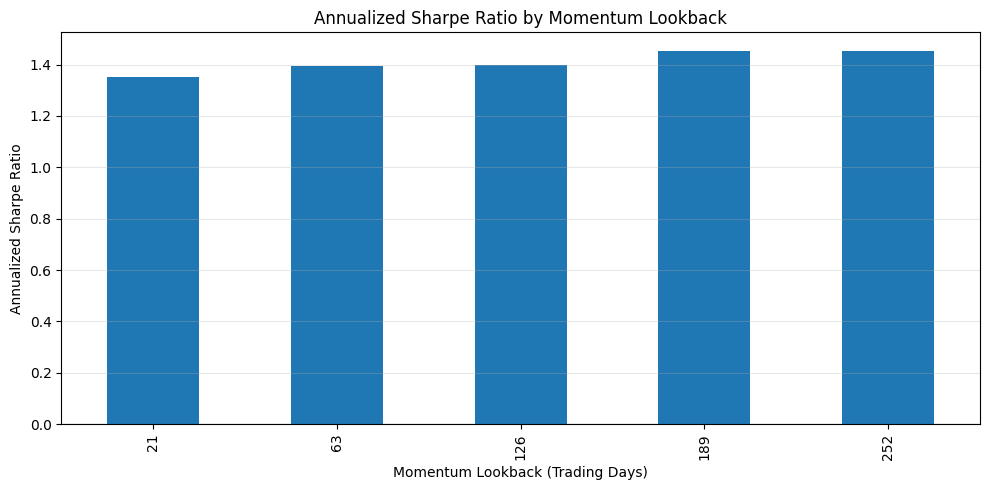

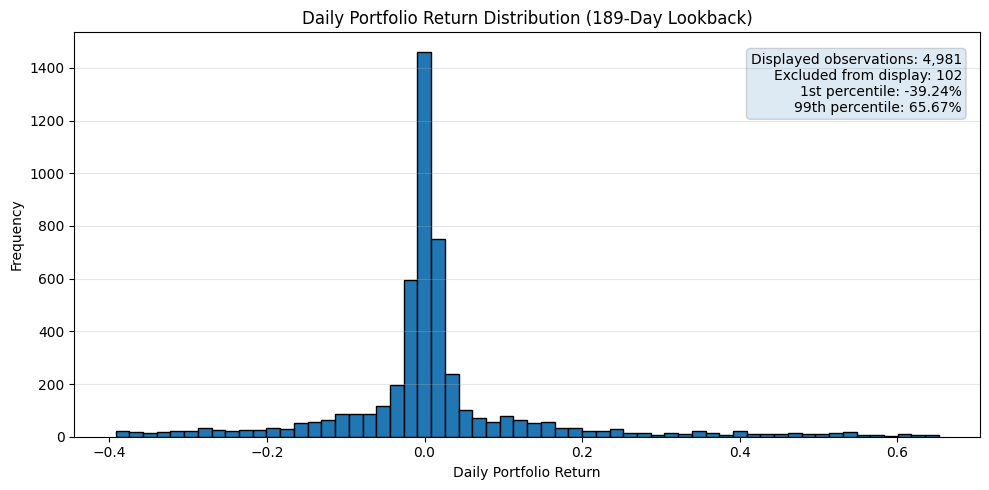

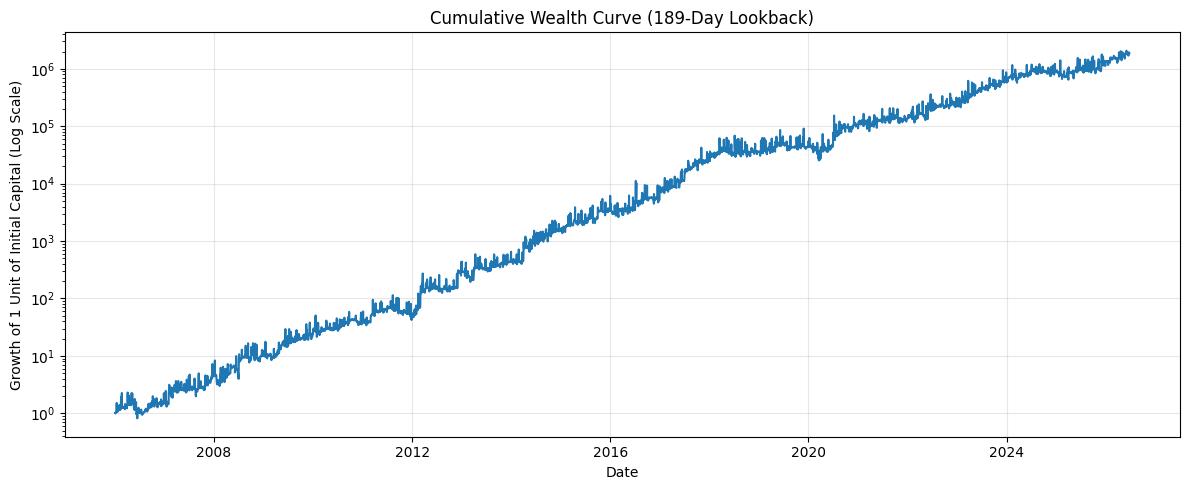

In [99]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# Chart 1: Annualized Sharpe Ratio Comparison
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

sharpe_values = performance_summary["Annualized Sharpe"]

sharpe_values.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Annualized Sharpe Ratio by Momentum Lookback")
ax.set_xlabel("Momentum Lookback (Trading Days)")
ax.set_ylabel("Annualized Sharpe Ratio")
ax.axhline(0, linewidth=0.8)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# Chart 2: Daily Return Distribution
# --------------------------------------------------

lower_limit = audit_returns.quantile(0.01)
upper_limit = audit_returns.quantile(0.99)

display_returns = audit_returns[
    audit_returns.between(lower_limit, upper_limit)
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    display_returns,
    bins=60,
    edgecolor="black"
)

ax.set_title(
    f"Daily Portfolio Return Distribution ({audit_lookback}-Day Lookback)"
)
ax.set_xlabel("Daily Portfolio Return")
ax.set_ylabel("Frequency")
ax.grid(axis="y", alpha=0.3)

ax.text(
    0.98,
    0.95,
    f"Displayed observations: {len(display_returns):,}\n"
    f"Excluded from display: {len(audit_returns) - len(display_returns):,}\n"
    f"1st percentile: {lower_limit:.2%}\n"
    f"99th percentile: {upper_limit:.2%}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    bbox=dict(boxstyle="round", alpha=0.15)
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# Chart 3: Cumulative Wealth Curve
# --------------------------------------------------

cumulative_wealth = (1 + audit_returns).cumprod()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    cumulative_wealth.index,
    cumulative_wealth.values
)

ax.set_yscale("log")
ax.set_title(
    f"Cumulative Wealth Curve ({audit_lookback}-Day Lookback)"
)
ax.set_xlabel("Date")
ax.set_ylabel("Growth of 1 Unit of Initial Capital (Log Scale)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Investigation of Extreme Stock-Level Price Movements

The previous analysis identified several unusually large portfolio
returns. We now investigate the underlying stock prices on those dates.

For each extreme portfolio return date, the analysis identifies
constituent stocks with absolute daily returns greater than 50%.

For each flagged stock, we examine:

- Previous trading day's closing price
- Event day's closing price
- Following trading day's closing price
- Market capitalization over the same dates
- Portfolio weight and return contribution
- Two-day price change from before the event to after it
- Two-day market-capitalization change over the same period

The two-day price change is calculated as:

$$
R_{i,t-1:t+1}
=
\frac{P_{i,t+1}}{P_{i,t-1}}-1
$$

The corresponding market-capitalization change is:

$$
R^{MCAP}_{i,t-1:t+1}
=
\frac{MCAP_{i,t+1}}{MCAP_{i,t-1}}-1
$$

A very large one-day price movement followed by a reversal,
combined with a relatively stable two-day price and market
capitalization change, may indicate a temporary price-scale
inconsistency.

This diagnostic is intended to identify suspicious observations.
It does not independently establish the cause of a price movement.

In [100]:
# Identify constituent-level extreme movements on extreme portfolio dates.

extreme_stock_records = []

for event_date in extreme_contributions.index:

    position = prices.index.get_loc(event_date)

    if position == 0 or position == len(prices.index) - 1:
        continue

    previous_date = prices.index[position - 1]
    next_date = prices.index[position + 1]

    stock_returns = asset_returns.loc[event_date]
    stock_weights = audit_weights.loc[event_date]

    # Only inspect stocks held in the portfolio on the event date.
    held_tickers = stock_weights[
        stock_weights > 0
    ].index

    for ticker in held_tickers:

        stock_return = stock_returns[ticker]

        if pd.isna(stock_return) or abs(stock_return) <= 0.50:
            continue

        price_before = prices.at[previous_date, ticker]
        price_event = prices.at[event_date, ticker]
        price_after = prices.at[next_date, ticker]

        mcap_before = market_caps.at[previous_date, ticker]
        mcap_event = market_caps.at[event_date, ticker]
        mcap_after = market_caps.at[next_date, ticker]

        price_two_day_return = (
            price_after / price_before - 1
        )

        mcap_two_day_return = (
            mcap_after / mcap_before - 1
        )

        scale_before = price_event / price_before
        scale_after = price_event / price_after

        weight = stock_weights[ticker]
        contribution = weight * stock_return

        # Flag possible temporary 5x or 0.2x scale movements.
        temporary_5x = (
            4.75 <= scale_before <= 5.25
            and 4.75 <= scale_after <= 5.25
        )

        temporary_02x = (
            0.19 <= scale_before <= 0.21
            and 0.19 <= scale_after <= 0.21
        )

        stable_price = abs(price_two_day_return) <= 0.05
        stable_mcap = abs(mcap_two_day_return) <= 0.05

        strong_anomaly_candidate = (
            (temporary_5x or temporary_02x)
            and stable_price
            and stable_mcap
        )

        extreme_stock_records.append({
            "Portfolio Event Date": event_date,
            "Stock": ticker,
            "Stock Daily Return": stock_return,
            "Portfolio Weight": weight,
            "Portfolio Contribution": contribution,
            "Price Before": price_before,
            "Price On Event": price_event,
            "Price After": price_after,
            "Price Two-Day Return": price_two_day_return,
            "Market Cap Two-Day Return": mcap_two_day_return,
            "Scale Before": scale_before,
            "Scale After": scale_after,
            "Strong Anomaly Candidate": strong_anomaly_candidate
        })


extreme_stock_audit = pd.DataFrame(extreme_stock_records)

if not extreme_stock_audit.empty:

    extreme_stock_audit = extreme_stock_audit.sort_values(
        "Portfolio Contribution",
        ascending=False
    )

    print("Extreme constituent movements:", len(extreme_stock_audit))

    display(
        extreme_stock_audit.style.format({
            "Stock Daily Return": "{:.2%}",
            "Portfolio Weight": "{:.2%}",
            "Portfolio Contribution": "{:.2%}",
            "Price Before": "{:.4f}",
            "Price On Event": "{:.4f}",
            "Price After": "{:.4f}",
            "Price Two-Day Return": "{:.2%}",
            "Market Cap Two-Day Return": "{:.2%}",
            "Scale Before": "{:.3f}x",
            "Scale After": "{:.3f}x"
        })
    )

    print("\nPotential strong temporary scale anomalies:")
    print(
        extreme_stock_audit[
            "Strong Anomaly Candidate"
        ].sum()
    )

else:
    print("No held stocks exceeded the 50% daily return threshold.")

Extreme constituent movements: 51


,Portfolio Event Date,Stock,Stock Daily Return,Portfolio Weight,Portfolio Contribution,Price Before,Price On Event,Price After,Price Two-Day Return,Market Cap Two-Day Return,Scale Before,Scale After,Strong Anomaly Candidate
0,2016-07-07 00:00:00,NALU.NS,362.19%,38.63%,139.90%,24.6200,113.7900,24.5900,-0.12%,-0.11%,4.622x,4.627x,False
4,2016-07-11 00:00:00,NALU.NS,277.47%,38.14%,105.83%,24.5900,92.8200,28.1600,14.52%,14.50%,3.775x,3.296x,False
23,2008-07-01 00:00:00,THOM.NS,1724.32%,5.86%,100.99%,5.5100,100.5200,20.4400,270.96%,-1.76%,18.243x,4.918x,False
9,2012-03-19 00:00:00,VSTI.NS,190.96%,51.87%,99.05%,77.2900,224.8800,82.3300,6.52%,6.53%,2.910x,2.731x,False
20,2009-06-10 00:00:00,BOB.NS,390.04%,23.57%,91.94%,61.4400,301.0800,63.4000,3.19%,3.48%,4.900x,4.749x,False
26,2022-06-20 00:00:00,CHPC.NS,313.87%,28.71%,90.12%,283.5700,1173.6200,276.4200,-2.52%,-2.52%,4.139x,4.246x,False
19,2010-01-19 00:00:00,TAJG.NS,391.68%,21.84%,85.56%,146.8000,721.7800,148.4400,1.12%,0.94%,4.917x,4.862x,True
15,2018-03-16 00:00:00,HEGL.NS,341.50%,23.85%,81.43%,513.1200,2265.4200,571.3700,11.35%,11.35%,4.415x,3.965x,False
24,2007-07-05 00:00:00,BRIT.NS,375.73%,21.54%,80.93%,125.7300,598.1300,131.9400,4.94%,5.47%,4.757x,4.533x,False
13,2012-07-18 00:00:00,VSTI.NS,365.54%,22.10%,80.77%,96.1200,447.4800,97.9900,1.95%,1.95%,4.655x,4.567x,False



Potential strong temporary scale anomalies:
4


### Full-Period Audit of Extreme Constituent Returns

The previous investigation examined only the largest positive and
negative portfolio return dates. This may miss other extreme stock
movements elsewhere in the backtest.

We now extend the analysis to every day in the 189-day strategy.

For each stock held in the portfolio, we identify daily returns
whose absolute value exceeds 50%.

For every flagged observation, we record:

- Stock and event date
- Daily stock return
- Portfolio weight and contribution
- Price before, during and after the event
- Two-day price return
- Two-day market-cap return
- Price-scale ratios
- Whether the observation satisfies our strict temporary
  scale-anomaly criteria

The strict criteria remain unchanged:

$$
4.75 \leq \frac{P_{i,t}}{P_{i,t-1}} \leq 5.25
\quad \text{and} \quad
4.75 \leq \frac{P_{i,t}}{P_{i,t+1}} \leq 5.25
$$

or

$$
0.19 \leq \frac{P_{i,t}}{P_{i,t-1}} \leq 0.21
\quad \text{and} \quad
0.19 \leq \frac{P_{i,t}}{P_{i,t+1}} \leq 0.21
$$

along with:

$$
\left|R_{i,t-1:t+1}\right| \leq 5\%
$$

and

$$
\left|R^{MCAP}_{i,t-1:t+1}\right| \leq 5\%
$$

This is a diagnostic exercise. No observations will be deleted,
corrected or winsorized at this stage.

In [101]:
# Scan every daily observation in the 189-day strategy.

full_extreme_records = []

for event_date in audit_returns.index:

    position = prices.index.get_loc(event_date)

    # Need a previous and following observation for reversal diagnostics.
    if position == 0 or position == len(prices.index) - 1:
        continue

    previous_date = prices.index[position - 1]
    next_date = prices.index[position + 1]

    stock_returns = asset_returns.loc[event_date]
    stock_weights = audit_weights.loc[event_date]

    held_tickers = stock_weights[
        stock_weights > 0
    ].index

    for ticker in held_tickers:

        stock_return = stock_returns[ticker]

        if pd.isna(stock_return) or abs(stock_return) <= 0.50:
            continue

        price_before = prices.at[previous_date, ticker]
        price_event = prices.at[event_date, ticker]
        price_after = prices.at[next_date, ticker]

        mcap_before = market_caps.at[previous_date, ticker]
        mcap_after = market_caps.at[next_date, ticker]

        values = [
            price_before, price_event, price_after,
            mcap_before, mcap_after
        ]

        if not np.isfinite(values).all() or min(values) <= 0:
            continue

        price_two_day_return = price_after / price_before - 1
        mcap_two_day_return = mcap_after / mcap_before - 1

        scale_before = price_event / price_before
        scale_after = price_event / price_after

        temporary_5x = (
            4.75 <= scale_before <= 5.25
            and 4.75 <= scale_after <= 5.25
        )

        temporary_02x = (
            0.19 <= scale_before <= 0.21
            and 0.19 <= scale_after <= 0.21
        )

        stable_price = abs(price_two_day_return) <= 0.05
        stable_mcap = abs(mcap_two_day_return) <= 0.05

        strong_candidate = (
            (temporary_5x or temporary_02x)
            and stable_price
            and stable_mcap
        )

        weight = stock_weights[ticker]

        full_extreme_records.append({
            "Date": event_date,
            "Stock": ticker,
            "Stock Return": stock_return,
            "Portfolio Weight": weight,
            "Portfolio Contribution": weight * stock_return,
            "Price Before": price_before,
            "Price On Event": price_event,
            "Price After": price_after,
            "Price Two-Day Return": price_two_day_return,
            "Market Cap Two-Day Return": mcap_two_day_return,
            "Scale Before": scale_before,
            "Scale After": scale_after,
            "Temporary 5x": temporary_5x,
            "Temporary 0.2x": temporary_02x,
            "Strong Anomaly Candidate": strong_candidate
        })


full_extreme_audit = pd.DataFrame(full_extreme_records)

if full_extreme_audit.empty:
    raise ValueError("No extreme held-stock observations were identified.")

full_extreme_audit = full_extreme_audit.sort_values(
    "Portfolio Contribution",
    ascending=False
).reset_index(drop=True)

print("Total extreme held-stock observations:",
      len(full_extreme_audit))

print("Unique event dates:",
      full_extreme_audit["Date"].nunique())

print("Unique affected stocks:",
      full_extreme_audit["Stock"].nunique())

print("Strong anomaly candidates:",
      full_extreme_audit["Strong Anomaly Candidate"].sum())

print("\nClassification summary:")

classification_summary = pd.Series({
    "Temporary 5x candidates":
        full_extreme_audit["Temporary 5x"].sum(),
    "Temporary 0.2x candidates":
        full_extreme_audit["Temporary 0.2x"].sum(),
    "Strong candidates meeting all criteria":
        full_extreme_audit["Strong Anomaly Candidate"].sum()
}, name="Observations")

display(classification_summary.to_frame())

print("\nStrong anomaly candidates:")

display(
    full_extreme_audit[
        full_extreme_audit["Strong Anomaly Candidate"]
    ].style.format({
        "Stock Return": "{:.2%}",
        "Portfolio Weight": "{:.2%}",
        "Portfolio Contribution": "{:.2%}",
        "Price Two-Day Return": "{:.2%}",
        "Market Cap Two-Day Return": "{:.2%}",
        "Scale Before": "{:.3f}x",
        "Scale After": "{:.3f}x"
    })
)

# Save the full diagnostic register.
audit_file = DATA_DIR / "full_period_extreme_return_audit_189d.csv"

full_extreme_audit.to_csv(audit_file, index=False)

print("\nFull audit register saved to:", audit_file)

Total extreme held-stock observations: 2940
Unique event dates: 2311
Unique affected stocks: 30
Strong anomaly candidates: 48

Classification summary:


,Observations
Temporary 5x candidates,40
Temporary 0.2x candidates,21
Strong candidates meeting all criteria,48



Strong anomaly candidates:


,Date,Stock,Stock Return,Portfolio Weight,Portfolio Contribution,Price Before,Price On Event,Price After,Price Two-Day Return,Market Cap Two-Day Return,Scale Before,Scale After,Temporary 5x,Temporary 0.2x,Strong Anomaly Candidate
6,2010-01-19 00:00:00,TAJG.NS,391.68%,21.84%,85.56%,146.800000,721.780000,148.440000,1.12%,0.94%,4.917x,4.862x,True,False,True
8,2006-02-20 00:00:00,TAJG.NS,400.18%,21.15%,84.66%,180.810000,904.370000,183.950000,1.74%,0.30%,5.002x,4.916x,True,False,True
9,2007-09-10 00:00:00,CHPC.NS,403.43%,20.31%,81.93%,175.410000,883.060000,181.010000,3.19%,3.38%,5.034x,4.879x,True,False,True
12,2015-12-31 00:00:00,ARTI.NS,391.92%,20.62%,80.82%,104.890000,515.970000,104.860000,-0.03%,-0.03%,4.919x,4.921x,True,False,True
15,2009-01-14 00:00:00,BRIT.NS,384.69%,20.93%,80.50%,101.430000,491.620000,102.760000,1.31%,0.91%,4.847x,4.784x,True,False,True
18,2018-07-06 00:00:00,ARTI.NS,399.10%,19.55%,78.04%,241.050000,1203.080000,250.940000,4.10%,4.11%,4.991x,4.794x,True,False,True
20,2008-09-08 00:00:00,BRIT.NS,385.57%,20.06%,77.33%,111.210000,540.000000,110.380000,-0.75%,-1.38%,4.856x,4.892x,True,False,True
30,2011-03-17 00:00:00,OSGL.NS,380.35%,19.32%,73.49%,61.270000,294.310000,60.040000,-2.01%,-2.01%,4.803x,4.902x,True,False,True
33,2012-12-03 00:00:00,THOM.NS,405.44%,17.88%,72.49%,20.400000,103.110000,20.860000,2.25%,2.25%,5.054x,4.943x,True,False,True
40,2016-12-30 00:00:00,AEGS.NS,392.77%,17.55%,68.95%,116.840000,575.750000,119.860000,2.58%,2.58%,4.928x,4.804x,True,False,True



Full audit register saved to: /content/drive/MyDrive/Momentum Factor Optimization/full_period_extreme_return_audit_189d.csv


### Construction and Classification of the Full-Period Anomaly Register

The 189-day strategy was examined across the entire backtest period to identify extreme daily movements in stocks held by the portfolio. An observation was classified as extreme when the absolute daily stock return exceeded 50%.

The audit identified 2,940 extreme held-stock observations across 2,311 unique dates, covering all 30 stocks in the universe.

A further classification identified 48 strong temporary price-scale anomaly candidates. These observations exhibited approximately fivefold or one-fifth price movements, followed by a reversal towards the previous price level. Both the two-day price return and market-capitalisation return remained within the specified 5% tolerance.

Several candidates made substantial contributions to portfolio returns. This indicates that the extreme performance figures are materially exposed to unusual constituent-level price movements.

These observations are treated as potential data-quality anomalies rather than confirmed errors. No arbitrary price adjustments have been applied. The original observations are retained for subsequent sensitivity analysis.

### When Do the Extreme Movements Occur?

The full-period audit identified 48 strong temporary scale-anomaly
candidates. We now examine their distribution over time and their
relationship with portfolio returns.

This analysis has three objectives:

1. Identify years with the highest concentration of strong candidates.
2. Compare temporary 5x and temporary 0.2x events.
3. Examine portfolio returns on dates when strong candidates occurred.

The portfolio-return comparison is descriptive, not causal. A strong
candidate occurring on a date does not establish that it explains
the entire portfolio return on that date.

We retain all original observations and do not modify the backtest.

,Extreme_Observations,Temporary_5x,Temporary_0_2x,Strong_Candidates
Year,,,,
2006,139,4,1,2
2007,147,3,0,3
2008,168,3,1,4
2009,156,2,3,3
2010,119,1,0,1
2011,123,1,0,1
2012,151,2,1,3
2013,124,2,1,3
2014,153,4,2,5


Distinct dates with strong anomaly candidates: 48

Portfolio returns on those dates:


,Portfolio Return
count,48.000000
mean,0.263513
std,0.425817
min,-0.277325
1%,-0.270116
5%,-0.181296
50%,0.083417
95%,0.897346
99%,1.171383
max,1.295976


,Value
Number of candidate observations,48.000000
Mean absolute stock contribution,0.303487
Largest positive contribution,0.855582
Largest negative contribution,-0.165294
Total absolute contribution,14.567387


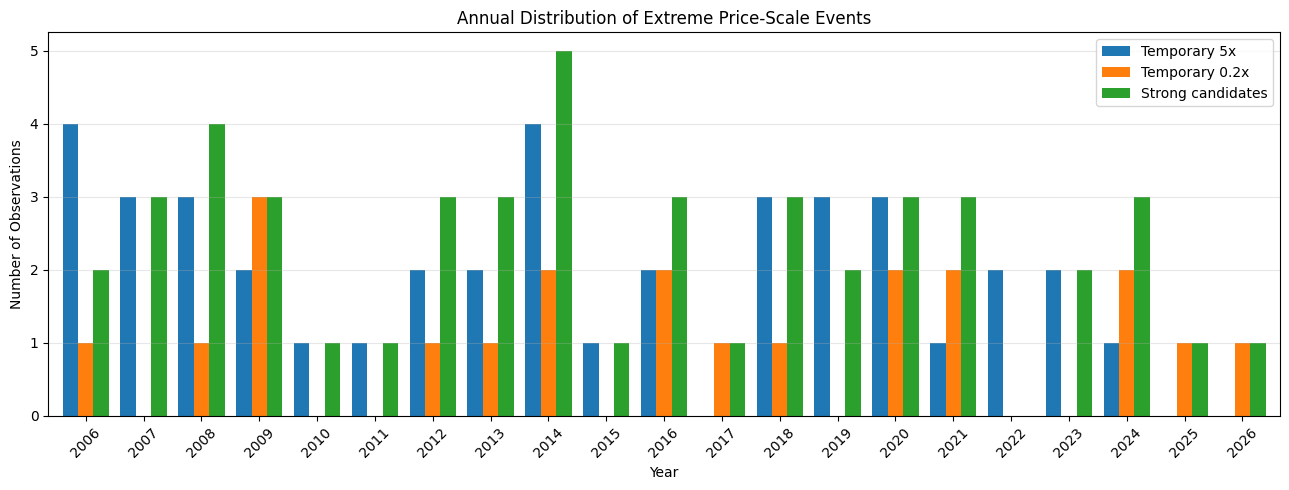

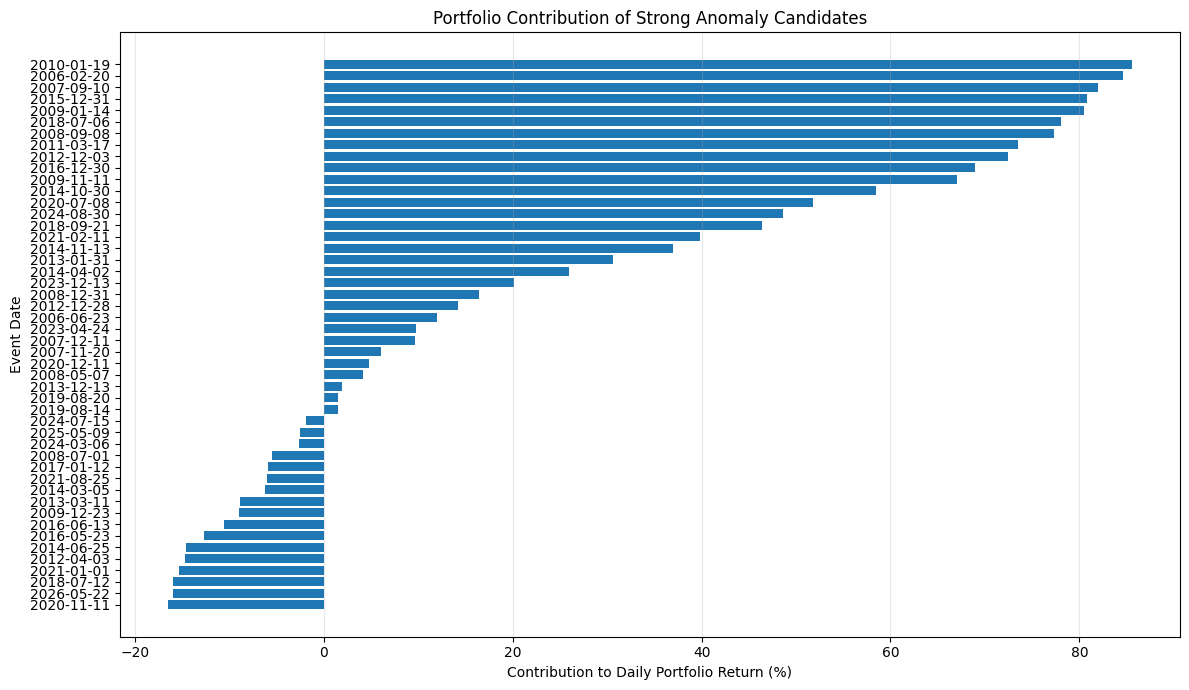

Annual summary saved: /content/drive/MyDrive/Momentum Factor Optimization/annual_anomaly_summary_189d.csv
Strong event register saved: /content/drive/MyDrive/Momentum Factor Optimization/strong_anomaly_events_189d.csv


In [102]:
# Prepare the anomaly event register.

anomaly_events = full_extreme_audit.copy()

anomaly_events["Date"] = pd.to_datetime(anomaly_events["Date"])
anomaly_events["Year"] = anomaly_events["Date"].dt.year

strong_events = anomaly_events[
    anomaly_events["Strong Anomaly Candidate"]
].copy()

if strong_events.empty:
    raise ValueError("No strong anomaly candidates are available.")

# 1. Annual distribution of anomaly candidates.

annual_anomaly_summary = (
    anomaly_events.groupby("Year")
    .agg(
        Extreme_Observations=("Stock", "size"),
        Temporary_5x=("Temporary 5x", "sum"),
        Temporary_0_2x=("Temporary 0.2x", "sum"),
        Strong_Candidates=("Strong Anomaly Candidate", "sum")
    )
)

display(annual_anomaly_summary)

# 2. Portfolio return on dates containing at least one strong candidate.

strong_event_dates = pd.DatetimeIndex(
    strong_events["Date"].drop_duplicates().sort_values()
)

portfolio_returns_on_event_dates = audit_returns.reindex(
    strong_event_dates
).dropna()

event_date_return_summary = portfolio_returns_on_event_dates.describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
)

print("Distinct dates with strong anomaly candidates:",
      len(strong_event_dates))

print("\nPortfolio returns on those dates:")
display(event_date_return_summary.to_frame("Portfolio Return"))

# 3. Contribution analysis for strong candidate observations.

strong_contribution_summary = pd.Series({
    "Number of candidate observations": len(strong_events),
    "Mean absolute stock contribution":
        strong_events["Portfolio Contribution"].abs().mean(),
    "Largest positive contribution":
        strong_events["Portfolio Contribution"].max(),
    "Largest negative contribution":
        strong_events["Portfolio Contribution"].min(),
    "Total absolute contribution":
        strong_events["Portfolio Contribution"].abs().sum()
}, name="Value")

display(strong_contribution_summary.to_frame())

# 4. Visualisation: annual strong candidate counts.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 5))

annual_anomaly_summary[
    ["Temporary_5x", "Temporary_0_2x", "Strong_Candidates"]
].plot(
    kind="bar",
    ax=ax,
    width=0.8
)

ax.set_title("Annual Distribution of Extreme Price-Scale Events")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Observations")
ax.legend([
    "Temporary 5x",
    "Temporary 0.2x",
    "Strong candidates"
])
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Visualisation: portfolio contribution of strong candidates.

strong_events_plot = strong_events.sort_values(
    "Portfolio Contribution"
).copy()

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    strong_events_plot["Date"].dt.strftime("%Y-%m-%d"),
    strong_events_plot["Portfolio Contribution"] * 100
)

ax.set_title("Portfolio Contribution of Strong Anomaly Candidates")
ax.set_xlabel("Contribution to Daily Portfolio Return (%)")
ax.set_ylabel("Event Date")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Save annual summary and strong event register.

annual_file = DATA_DIR / "annual_anomaly_summary_189d.csv"
strong_file = DATA_DIR / "strong_anomaly_events_189d.csv"

annual_anomaly_summary.to_csv(annual_file)
strong_events.to_csv(strong_file, index=False)

print("Annual summary saved:", annual_file)
print("Strong event register saved:", strong_file)

### Decomposing Portfolio Returns on Strong-Anomaly Dates

The next step is to separate the contribution of identified anomaly
candidates from the contribution of the remaining portfolio holdings.

For each date containing at least one strong anomaly candidate, we
calculate:

$$
C_{\text{flagged},t}
=
\sum_{i \in A_t} w_{i,t-1}R_{i,t}
$$

where $A_t$ is the set of stocks identified as strong anomaly
candidates on date $t$.

The contribution from all other holdings is:

$$
C_{\text{other},t}
=
R_{p,t}-C_{\text{flagged},t}
$$

Therefore:

$$
R_{p,t}
=
C_{\text{flagged},t}+C_{\text{other},t}
$$

This is a return attribution exercise, not a corrected backtest.
It does not assume that the flagged stock returns should be zero,
nor does it estimate what their true returns should have been.

The purpose is to establish how much of each event-day portfolio
return came directly from the identified candidate observations.

Event-date attribution observations: 48

Largest flagged-stock contributions:


,Candidate_Stocks,Candidate_Count,Flagged_Contribution,Gross_Absolute_Flagged_Contribution,Portfolio Return,Other_Holdings_Contribution,Absolute_Net_Flagged_Contribution,Attribution_Check
2010-01-19 00:00:00,TAJG.NS,1,85.56%,0.855582,90.03%,4.47%,0.855582,True
2006-02-20 00:00:00,TAJG.NS,1,84.66%,0.846551,84.18%,-0.47%,0.846551,True
2007-09-10 00:00:00,CHPC.NS,1,81.93%,0.819268,82.61%,0.68%,0.819268,True
2015-12-31 00:00:00,ARTI.NS,1,80.82%,0.808213,79.97%,-0.85%,0.808213,True
2009-01-14 00:00:00,BRIT.NS,1,80.50%,0.804992,82.18%,1.68%,0.804992,True
2018-07-06 00:00:00,ARTI.NS,1,78.04%,0.780368,103.09%,25.05%,0.780368,True
2008-09-08 00:00:00,BRIT.NS,1,77.33%,0.773267,80.77%,3.44%,0.773267,True
2011-03-17 00:00:00,OSGL.NS,1,73.49%,0.734894,73.55%,0.06%,0.734894,True
2012-12-03 00:00:00,THOM.NS,1,72.49%,0.724882,85.46%,12.97%,0.724882,True
2016-12-30 00:00:00,AEGS.NS,1,68.95%,0.689458,70.29%,1.35%,0.689458,True



Attribution summary:


,Value
Event dates,48.000000
Mean portfolio return,0.263513
Mean net flagged contribution,0.234627
Mean gross absolute flagged contribution,0.303487
Mean absolute net flagged contribution,0.303487
Mean other-holdings contribution,0.028887
Largest positive flagged contribution,0.855582
Largest negative flagged contribution,-0.165294


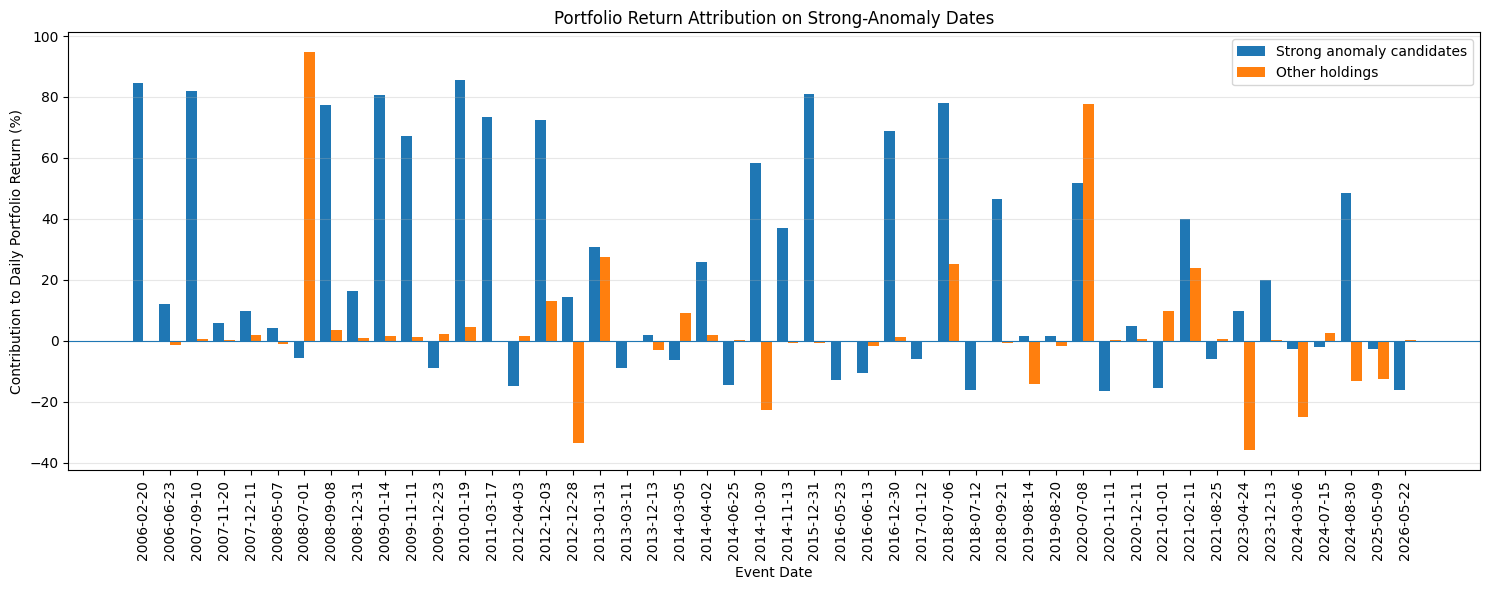

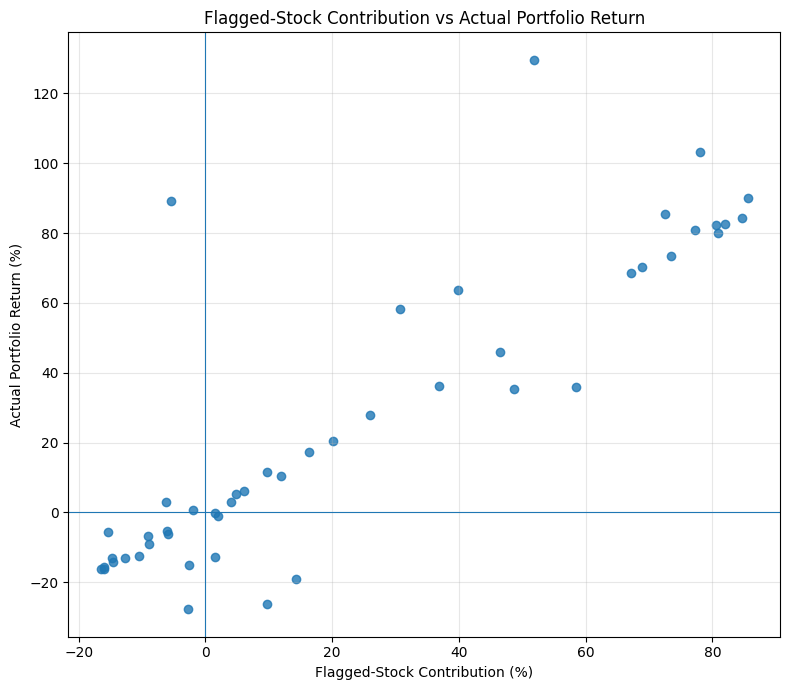


Attribution file saved: /content/drive/MyDrive/Momentum Factor Optimization/anomaly_event_return_attribution_189d.csv


In [103]:
# Aggregate flagged-stock contributions by event date.

flagged_contributions = (
    strong_events.groupby("Date")
    .agg(
        Candidate_Stocks=("Stock", lambda x: ", ".join(x)),
        Candidate_Count=("Stock", "nunique"),
        Flagged_Contribution=(
            "Portfolio Contribution", "sum"
        ),
        Gross_Absolute_Flagged_Contribution=(
            "Portfolio Contribution",
            lambda x: x.abs().sum()
        )
    )
)

# Match the portfolio return on each event date.

event_decomposition = flagged_contributions.join(
    audit_returns.rename("Portfolio Return"),
    how="inner"
)

# Calculate the contribution from all non-flagged holdings.

event_decomposition["Other_Holdings_Contribution"] = (
    event_decomposition["Portfolio Return"]
    - event_decomposition["Flagged_Contribution"]
)

# Calculate the absolute net flagged contribution.

event_decomposition["Absolute_Net_Flagged_Contribution"] = (
    event_decomposition["Flagged_Contribution"].abs()
)

# Verify the attribution identity.

event_decomposition["Attribution_Check"] = np.isclose(
    event_decomposition["Portfolio Return"],
    event_decomposition["Flagged_Contribution"]
    + event_decomposition["Other_Holdings_Contribution"],
    atol=1e-10
)

if not event_decomposition["Attribution_Check"].all():
    raise AssertionError("Return attribution does not reconcile.")

# Rank dates by gross absolute flagged-stock contribution.

event_decomposition = event_decomposition.sort_values(
    "Gross_Absolute_Flagged_Contribution",
    ascending=False
)

print("Event-date attribution observations:",
      len(event_decomposition))

print("\nLargest flagged-stock contributions:")

display(
    event_decomposition.head(20).style.format({
        "Portfolio Return": "{:.2%}",
        "Flagged_Contribution": "{:.2%}",
        "Other_Holdings_Contribution": "{:.2%}",
        "Absolute_Flagged_Contribution": "{:.2%}"
    })
)

# Summary statistics.

attribution_summary = pd.Series({
    "Event dates": len(event_decomposition),

    "Mean portfolio return":
        event_decomposition["Portfolio Return"].mean(),

    "Mean net flagged contribution":
        event_decomposition["Flagged_Contribution"].mean(),

    "Mean gross absolute flagged contribution":
        event_decomposition[
            "Gross_Absolute_Flagged_Contribution"
        ].mean(),

    "Mean absolute net flagged contribution":
        event_decomposition[
            "Absolute_Net_Flagged_Contribution"
        ].mean(),

    "Mean other-holdings contribution":
        event_decomposition[
            "Other_Holdings_Contribution"
        ].mean(),

    "Largest positive flagged contribution":
        event_decomposition["Flagged_Contribution"].max(),

    "Largest negative flagged contribution":
        event_decomposition["Flagged_Contribution"].min()
}, name="Value")

print("\nAttribution summary:")
display(attribution_summary.to_frame())

print("\n")
# Visualisation 1: Actual portfolio return decomposition.

plot_data = event_decomposition.sort_index()

fig, ax = plt.subplots(figsize=(15, 6))

x = np.arange(len(plot_data))
width = 0.4

ax.bar(
    x - width / 2,
    plot_data["Flagged_Contribution"] * 100,
    width,
    label="Strong anomaly candidates"
)

ax.bar(
    x + width / 2,
    plot_data["Other_Holdings_Contribution"] * 100,
    width,
    label="Other holdings"
)

ax.set_title(
    "Portfolio Return Attribution on Strong-Anomaly Dates"
)
ax.set_xlabel("Event Date")
ax.set_ylabel("Contribution to Daily Portfolio Return (%)")

ax.set_xticks(x)
ax.set_xticklabels(
    plot_data.index.strftime("%Y-%m-%d"),
    rotation=90
)

ax.axhline(0, linewidth=0.8)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\n")
# Visualisation 2: Flagged contribution versus actual portfolio return.

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    event_decomposition["Flagged_Contribution"] * 100,
    event_decomposition["Portfolio Return"] * 100,
    alpha=0.8
)

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)

ax.set_title(
    "Flagged-Stock Contribution vs Actual Portfolio Return"
)
ax.set_xlabel("Flagged-Stock Contribution (%)")
ax.set_ylabel("Actual Portfolio Return (%)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save the attribution register.

attribution_file = (
    DATA_DIR / "anomaly_event_return_attribution_189d.csv"
)

event_decomposition.to_csv(attribution_file)

print("\nAttribution file saved:", attribution_file)

### Event-Level Portfolio Contribution Analysis

The contribution analysis examines how strongly identified price-scale anomaly candidates influenced the daily returns of the 189-day momentum portfolio.

Across 48 event dates, the mean portfolio return was 26.35%, while the mean contribution from flagged stocks was 23.46 percentage points. The mean contribution from the remaining holdings was 2.89 percentage points.

Individual flagged-stock contributions were substantial. On 19 January 2010, for example, TAJG.NS contributed 85.56 percentage points to a portfolio return of 90.03%. Similar patterns were observed on several other dates.

The attribution calculations reconciled across all 48 event dates. This confirms that the portfolio return can be decomposed into contributions from flagged stocks and the remaining holdings.

The results indicate that a relatively small number of unusual constituent-level price movements had a material influence on reported portfolio performance. These observations are therefore important when interpreting the original Sharpe ratio and cumulative return.

In [104]:
# Independent Reconciliation of Portfolio Returns

# Independently reconstruct daily portfolio returns
# from stock-level contributions.

common_dates = (
    audit_returns.index
    .intersection(asset_returns.index)
    .intersection(audit_weights.index)
)

common_tickers = (
    asset_returns.columns
    .intersection(audit_weights.columns)
)

aligned_returns = asset_returns.loc[
    common_dates, common_tickers
]

aligned_weights = audit_weights.loc[
    common_dates, common_tickers
]

# Check for missing values in the aligned inputs.

print("Missing asset returns:",
      aligned_returns.isna().sum().sum())

print("Missing portfolio weights:",
      aligned_weights.isna().sum().sum())

# Reconstruct individual stock contributions.

daily_stock_contributions = (
    aligned_weights * aligned_returns
)

# Reconstruct total portfolio returns.

reconstructed_returns = (
    daily_stock_contributions.sum(axis=1)
)

# Compare against the original portfolio return series.

comparison = pd.concat(
    [
        audit_returns.reindex(common_dates).rename("Original"),
        reconstructed_returns.rename("Reconstructed")
    ],
    axis=1
)

comparison["Difference"] = (
    comparison["Original"]
    - comparison["Reconstructed"]
)

comparison["Match"] = np.isclose(
    comparison["Original"],
    comparison["Reconstructed"],
    atol=1e-10,
    rtol=1e-8
)

display(comparison.head())

print("\nReconciliation results")
print("----------------------")
print("Observations:", len(comparison))
print("Matching observations:", comparison["Match"].sum())
print("Non-matching observations:", (~comparison["Match"]).sum())
print("Maximum absolute difference:",
      comparison["Difference"].abs().max())

# Check whether portfolio weights sum to 100%.

weight_sums = aligned_weights.sum(axis=1)

print("\nPortfolio weight checks")
print("-----------------------")
print("Minimum weight sum:", weight_sums.min())
print("Maximum weight sum:", weight_sums.max())

print("All weight sums equal 1:",
      np.allclose(weight_sums, 1.0, atol=1e-10))

Missing asset returns: 0
Missing portfolio weights: 0


,Original,Reconstructed,Difference,Match
date,,,,
2006-01-03,0.005776,0.005776,0.000000e+00,True
2006-01-04,-0.014165,-0.014165,0.000000e+00,True
2006-01-05,0.043321,0.043321,0.000000e+00,True
2006-01-06,0.018862,0.018862,3.469447e-18,True
2006-01-09,0.005239,0.005239,-8.673617e-19,True



Reconciliation results
----------------------
Observations: 5083
Matching observations: 5083
Non-matching observations: 0
Maximum absolute difference: 2.220446049250313e-16

Portfolio weight checks
-----------------------
Minimum weight sum: 0.9999999999999989
Maximum weight sum: 1.0000000000000009
All weight sums equal 1: True


In [105]:
# Validate portfolio return and daily weight alignment.

print("First rebalance date:",
      weights_21.index.min())

print("First portfolio return date:",
      portfolio_returns_21.index.min())

print("Last portfolio return date:",
      portfolio_returns_21.index.max())

print(
    "First return occurs after first rebalance:",
    portfolio_returns_21.index.min() > weights_21.index.min()
)

print(
    "Daily weights sum to 100%:",
    np.allclose(daily_weights_21.sum(axis=1), 1.0)
)

print(
    "Exactly 10 holdings at every return date:",
    (daily_weights_21 > 0).sum(axis=1).eq(10).all()
)

print(
    "All daily weights are non-negative:",
    (daily_weights_21 >= -1e-12).all().all()
)

print(
    "All portfolio returns are finite:",
    np.isfinite(portfolio_returns_21).all()
)

First rebalance date: 2006-01-02 00:00:00
First portfolio return date: 2006-01-03 00:00:00
Last portfolio return date: 2026-06-24 00:00:00
First return occurs after first rebalance: True
Daily weights sum to 100%: True
Exactly 10 holdings at every return date: True
All daily weights are non-negative: True
All portfolio returns are finite: True


In [106]:
# Compare strong anomaly dates with portfolio return dates.

candidate_dates = pd.DatetimeIndex(
    strong_events["Date"].drop_duplicates().sort_values()
)

portfolio_dates = pd.DatetimeIndex(audit_returns.index)

missing_event_dates = candidate_dates.difference(
    portfolio_dates
)

print("Unique strong candidate dates:", len(candidate_dates))
print("Portfolio return dates:", len(portfolio_dates))
print("Missing event dates:", len(missing_event_dates))

if len(missing_event_dates) > 0:
    print("\nDates without portfolio returns:")
    display(
        strong_events[
            strong_events["Date"].isin(missing_event_dates)
        ]
    )

Unique strong candidate dates: 48
Portfolio return dates: 5083
Missing event dates: 0


In [107]:
# Validate the full-period anomaly register and annual summary.

if len(strong_events) != int(
    annual_anomaly_summary["Strong_Candidates"].sum()
):
    raise AssertionError(
        "Strong candidate counts do not reconcile with the annual summary."
    )

if strong_events["Date"].nunique() != len(strong_events):
    raise AssertionError(
        "Expected one strong candidate observation per event date."
    )

if len(candidate_dates.difference(portfolio_dates)) != 0:
    raise AssertionError(
        "One or more strong candidate dates are missing from portfolio returns."
    )

print("Full-period anomaly register validation passed.")
print("Strong candidate observations:", len(strong_events))
print("Unique strong candidate dates:", strong_events["Date"].nunique())
print(
    "Annual strong candidate total:",
    int(annual_anomaly_summary["Strong_Candidates"].sum())
)
print("All strong candidate dates have matching portfolio returns.")

Full-period anomaly register validation passed.
Strong candidate observations: 48
Unique strong candidate dates: 48
Annual strong candidate total: 48
All strong candidate dates have matching portfolio returns.


### Annual Distribution of Extreme Price-Scale Events

The annual analysis shows that extreme constituent-level price movements occurred throughout the 2006–2026 backtest period.

A total of 48 strong temporary price-scale anomaly candidates were identified across 48 distinct event dates. The highest annual count occurred in 2014, with five candidates. Other notable periods included 2008, 2009, 2020 and 2021.

The broader extreme-return observations were considerably more frequent than the strong anomaly candidates. For example, 2022 recorded 145 extreme held-stock observations but no candidates meeting the stricter anomaly classification criteria.

This distinction is important because an unusually large daily return does not, by itself, establish a temporary price-scale anomaly. The classification also considers the subsequent price reversal and the stability of the two-day price and market-capitalisation returns.

The distribution indicates that potential price-scale anomalies recur across the historical dataset rather than being concentrated in a single market episode.

In [108]:
annual_anomaly_summary.to_csv(
    DATA_DIR / "annual_anomaly_summary_189d.csv"
)

strong_events.to_csv(
    DATA_DIR / "strong_anomaly_events_189d.csv",
    index=False
)

print("Corrected annual summary and event register saved.")

Corrected annual summary and event register saved.


### Daily Portfolio Return Engine: Validation

The daily portfolio return engine was independently validated by reconstructing portfolio returns from individual stock returns and beginning-of-period portfolio weights.

All 5,083 daily observations reconciled, with a maximum absolute difference of approximately $2.22 \times 10^{-16}$, attributable to floating-point precision. No missing asset returns or portfolio weights were identified.

The validation also confirmed that portfolio weights sum to 100% on every return date, exactly 10 stocks are held on every return date, and all portfolio weights remain non-negative.

The execution convention was verified. Initial portfolio weights become active after the first rebalance-date close, and subsequent target weights take effect from the trading day following each rebalance. Between rebalances, constituent weights drift naturally with daily price movements.

These checks establish the internal consistency of the portfolio return calculations and their associated weight records. They do not independently establish the accuracy of the underlying market-price data or eliminate the previously identified data-quality concerns.

In [109]:
# Build a separate held-stock anomaly register for each lookback period.

from IPython.display import display

lookbacks = [21, 63, 126, 189, 252]

# Calculate individual stock returns once.
asset_returns = prices.pct_change(fill_method=None)

# Validate input date and stock-universe alignment.
if not prices.index.equals(market_caps.index):
    raise ValueError("Price and market-cap dates do not match.")

if not prices.columns.equals(market_caps.columns):
    raise ValueError("Price and market-cap universes do not match.")

if not asset_returns.index.equals(prices.index):
    raise ValueError("Asset-return and price dates do not match.")

# Store the detailed registers and summary statistics.
anomaly_registers = {}
anomaly_summaries = []

for lookback in lookbacks:

    daily_weights = backtest_results[lookback]["Daily Weights"]
    daily_portfolio_returns = backtest_results[lookback]["Daily Returns"]

    # Confirm that weights and portfolio returns cover the same dates.
    if not daily_weights.index.equals(daily_portfolio_returns.index):
        raise ValueError(
            f"Date mismatch between weights and returns "
            f"for {lookback}-day lookback."
        )

    # Validate the stock universe.
    if not daily_weights.columns.equals(prices.columns):
        raise ValueError(
            f"Stock universe mismatch for {lookback}-day lookback."
        )

    # Validate portfolio weights.
    if not np.isfinite(daily_weights.to_numpy()).all():
        raise ValueError(
            f"Non-finite portfolio weights for {lookback}-day lookback."
        )

    if (daily_weights < 0).any().any():
        raise ValueError(
            f"Negative portfolio weights for {lookback}-day lookback."
        )

    if not np.allclose(
        daily_weights.sum(axis=1),
        1.0,
        atol=1e-8
    ):
        raise ValueError(
            f"Portfolio weights do not sum to one "
            f"for {lookback}-day lookback."
        )

    records = []

    for event_date in daily_portfolio_returns.index:

        # Find the event date's position in the original price history.
        position = prices.index.get_indexer([event_date])[0]

        if position == -1:
            raise ValueError(
                f"Event date {event_date} is missing from price history."
            )

        # Adjacent observations are required for the reversal test.
        if position <= 0 or position >= len(prices.index) - 1:
            continue

        previous_date = prices.index[position - 1]
        next_date = prices.index[position + 1]

        # Beginning-of-period weights and event-day stock returns.
        weights_today = daily_weights.loc[event_date]
        returns_today = asset_returns.loc[event_date]

        # Only investigate stocks that were held and had an extreme return.
        held_extreme_stocks = weights_today.index[
            (weights_today > 0) &
            (returns_today.abs() > 0.50)
        ]

        for stock in held_extreme_stocks:

            price_before = prices.loc[previous_date, stock]
            price_event = prices.loc[event_date, stock]
            price_after = prices.loc[next_date, stock]

            mcap_before = market_caps.loc[previous_date, stock]
            mcap_after = market_caps.loc[next_date, stock]

            values = np.array([
                price_before,
                price_event,
                price_after,
                mcap_before,
                mcap_after
            ], dtype=float)

            # Exclude observations where the required data is invalid.
            if not np.isfinite(values).all() or np.any(values <= 0):
                continue

            # Price-scale ratios relative to adjacent observations.
            scale_before = price_event / price_before
            scale_after = price_event / price_after

            # Two-day returns from the trading day before to the day after.
            two_day_price_return = price_after / price_before - 1
            two_day_mcap_return = mcap_after / mcap_before - 1

            # Temporary scale anomaly criteria.
            temporary_5x = (
                4.75 <= scale_before <= 5.25 and
                4.75 <= scale_after <= 5.25
            )

            temporary_02x = (
                0.19 <= scale_before <= 0.21 and
                0.19 <= scale_after <= 0.21
            )

            stable_price = abs(two_day_price_return) <= 0.05
            stable_mcap = abs(two_day_mcap_return) <= 0.05

            strong_anomaly = (
                (temporary_5x or temporary_02x) and
                stable_price and
                stable_mcap
            )

            stock_return = returns_today[stock]
            portfolio_weight = weights_today[stock]

            records.append({
                "Lookback": lookback,
                "Date": event_date,
                "Stock": stock,
                "Stock Return": stock_return,
                "Portfolio Weight": portfolio_weight,
                "Portfolio Contribution": (
                    portfolio_weight * stock_return
                ),
                "Price Before": price_before,
                "Price On Event": price_event,
                "Price After": price_after,
                "Scale Before": scale_before,
                "Scale After": scale_after,
                "Two-Day Price Return": two_day_price_return,
                "Two-Day Market Cap Return": two_day_mcap_return,
                "Temporary 5x": temporary_5x,
                "Temporary 0.2x": temporary_02x,
                "Strong Anomaly Candidate": strong_anomaly
            })

    # Create the detailed anomaly register.
    anomaly_df = pd.DataFrame(records)

    # Validate contribution calculations.
    if not anomaly_df.empty:

        reconstructed_contributions = (
            anomaly_df["Portfolio Weight"]
            * anomaly_df["Stock Return"]
        )

        if not np.allclose(
            anomaly_df["Portfolio Contribution"],
            reconstructed_contributions,
            atol=1e-12
        ):
            raise AssertionError(
                f"Contribution calculation failed "
                f"for {lookback}-day lookback."
            )

    anomaly_registers[lookback] = anomaly_df

    # Separate strong candidates from all extreme observations.
    strong_events = anomaly_df[
        anomaly_df["Strong Anomaly Candidate"]
    ].copy()

    # Store cross-lookback summary statistics.
    anomaly_summaries.append({
        "Lookback": lookback,
        "Extreme Held-Stock Observations": len(anomaly_df),
        "Unique Extreme Event Dates": anomaly_df["Date"].nunique(),
        "Unique Extreme Stocks": anomaly_df["Stock"].nunique(),
        "Strong Candidate Observations": len(strong_events),
        "Unique Strong Candidate Dates": strong_events["Date"].nunique(),
        "Unique Strong Candidate Stocks": strong_events["Stock"].nunique(),
        "Temporary 5x Candidates": int(anomaly_df["Temporary 5x"].sum()),
        "Temporary 0.2x Candidates": int(anomaly_df["Temporary 0.2x"].sum()),
        "Total Absolute Strong Contributions": (
            strong_events["Portfolio Contribution"].abs().sum()
        )
    })

# Create the cross-lookback comparison.
anomaly_summary_df = pd.DataFrame(anomaly_summaries)

# Display the results.
display(
    anomaly_summary_df.style.format({
        "Total Absolute Strong Contributions": "{:.4f}"
    })
)

# Final validation across all lookback periods.
for lookback in lookbacks:

    register = anomaly_registers[lookback]

    strong_register = register[
        register["Strong Anomaly Candidate"]
    ]

    if len(register) != anomaly_summary_df.loc[
        anomaly_summary_df["Lookback"] == lookback,
        "Extreme Held-Stock Observations"
    ].iloc[0]:
        raise AssertionError(
            f"Extreme observation count mismatch for {lookback}-day lookback."
        )

    if len(strong_register) != anomaly_summary_df.loc[
        anomaly_summary_df["Lookback"] == lookback,
        "Strong Candidate Observations"
    ].iloc[0]:
        raise AssertionError(
            f"Strong candidate count mismatch for {lookback}-day lookback."
        )

print("\nAll five lookback registers passed validation.")


,Lookback,Extreme Held-Stock Observations,Unique Extreme Event Dates,Unique Extreme Stocks,Strong Candidate Observations,Unique Strong Candidate Dates,Unique Strong Candidate Stocks,Temporary 5x Candidates,Temporary 0.2x Candidates,Total Absolute Strong Contributions
0,21,2865,2228,30,44,44,24,32,23,10.5969
1,63,2901,2283,30,54,53,27,44,21,14.5066
2,126,2884,2286,30,42,42,23,35,17,13.4844
3,189,2940,2311,30,48,48,22,40,21,14.5674
4,252,2926,2293,30,47,47,23,35,19,14.5315



All five lookback registers passed validation.


## **Phase 6: Anomaly Sensitivity and Robustness Analysis**

The following analysis evaluates the influence of strong temporary price-scale anomaly candidates on the five momentum strategies. On flagged stock/date observations, the corresponding portfolio contribution is set to zero while all other contributions remain unchanged.

The original backtest remains untouched. The resulting performance represents an illustrative sensitivity scenario, not a corrected historical backtest or an estimate of actual investable performance.

In [110]:
# Anomaly-excluded performance sensitivity analysis

sensitivity_results = {}
sensitivity_summary = []

TRADING_DAYS = 252

def calculate_performance_metrics(returns):

    returns = returns.dropna().astype(float)

    if len(returns) < 2:
        raise ValueError("At least two daily returns are required.")

    if (returns <= -1).any():
        raise ValueError("A daily return of -100% or lower prevents valid compounding.")

    annualized_sharpe = (
        returns.mean() / returns.std(ddof=1)
    ) * np.sqrt(TRADING_DAYS)

    annualized_volatility = (
        returns.std(ddof=1) * np.sqrt(TRADING_DAYS)
    )

    cumulative_return = np.prod(1 + returns) - 1

    cagr = (
        (1 + cumulative_return) **
        (TRADING_DAYS / len(returns))
    ) - 1

    return {
        "Observations": len(returns),
        "Annualized Sharpe": annualized_sharpe,
        "Annualized Volatility": annualized_volatility,
        "Cumulative Return": cumulative_return,
        "CAGR": cagr
    }


for lookback in lookbacks:

    original_returns = (
        backtest_results[lookback]["Daily Returns"]
        .copy()
        .astype(float)
    )

    # Retrieve strong anomaly candidates for this lookback.
    strong_events = anomaly_registers[lookback].loc[
        anomaly_registers[lookback]["Strong Anomaly Candidate"]
    ].copy()

    # Aggregate flagged contributions when multiple stocks
    # are identified on the same trading date.
    flagged_contributions = (
        strong_events.groupby("Date")["Portfolio Contribution"]
        .sum()
    )

    # Align flagged contributions with the original return series.
    flagged_contributions = (
        flagged_contributions.reindex(
            original_returns.index,
            fill_value=0.0
        )
    )

    # Diagnostic scenario:
    # Set flagged stock contributions to zero.
    sensitivity_returns = (
        original_returns - flagged_contributions
    )

    # Calculate original and sensitivity performance.
    original_metrics = calculate_performance_metrics(
        original_returns
    )

    sensitivity_metrics = calculate_performance_metrics(
        sensitivity_returns
    )

    # Store detailed results.
    sensitivity_results[lookback] = {
        "Original Returns": original_returns,
        "Sensitivity Returns": sensitivity_returns,
        "Flagged Contributions": flagged_contributions,
        "Strong Events": strong_events,
        "Original Metrics": original_metrics,
        "Sensitivity Metrics": sensitivity_metrics
    }

    sensitivity_summary.append({
        "Lookback": lookback,
        "Strong Candidate Observations": len(strong_events),
        "Affected Dates": strong_events["Date"].nunique(),
        "Net Flagged Contribution": (
            strong_events["Portfolio Contribution"].sum()
        ),
        "Absolute Flagged Contribution": (
            strong_events["Portfolio Contribution"].abs().sum()
        ),
        "Original Sharpe": original_metrics["Annualized Sharpe"],
        "Sensitivity Sharpe": sensitivity_metrics["Annualized Sharpe"],
        "Sharpe Change": (
            sensitivity_metrics["Annualized Sharpe"] -
            original_metrics["Annualized Sharpe"]
        ),
        "Original CAGR": original_metrics["CAGR"],
        "Sensitivity CAGR": sensitivity_metrics["CAGR"],
        "Original Cumulative Return": original_metrics["Cumulative Return"],
        "Sensitivity Cumulative Return": sensitivity_metrics["Cumulative Return"]
    })


sensitivity_summary_df = pd.DataFrame(sensitivity_summary)

display(
    sensitivity_summary_df.style.format({
        "Net Flagged Contribution": "{:.4f}",
        "Absolute Flagged Contribution": "{:.4f}",
        "Original Sharpe": "{:.4f}",
        "Sensitivity Sharpe": "{:.4f}",
        "Sharpe Change": "{:+.4f}",
        "Original CAGR": "{:.2%}",
        "Sensitivity CAGR": "{:.2%}",
        "Original Cumulative Return": "{:.2%}",
        "Sensitivity Cumulative Return": "{:.2%}"
    })
)

,Lookback,Strong Candidate Observations,Affected Dates,Net Flagged Contribution,Absolute Flagged Contribution,Original Sharpe,Sensitivity Sharpe,Sharpe Change,Original CAGR,Sensitivity CAGR,Original Cumulative Return,Sensitivity Cumulative Return
0,21,44,44,7.9535,10.5969,1.3530,1.2351,-0.1179,62.87%,22.78%,1874179.92%,6174.80%
1,63,54,53,11.2690,14.5066,1.3946,1.2286,-0.1661,69.33%,13.67%,4109999.03%,1225.82%
2,126,42,42,10.4623,13.4844,1.3972,1.2334,-0.1638,71.68%,15.92%,5424022.83%,1869.91%
3,189,48,48,11.2621,14.5674,1.4532,1.2847,-0.1685,104.63%,36.71%,187313822.26%,54785.75%
4,252,47,47,11.4217,14.5315,1.4523,1.2795,-0.1729,101.30%,33.59%,134489606.03%,34345.82%


### Residual Extreme-Return Analysis

The strict anomaly sensitivity test removes the contributions of identified temporary price-scale anomaly candidates. However, other extreme held-stock returns remain in the dataset.

This analysis examines those remaining observations to determine whether the residual performance is still exposed to unusually large stock-level returns. These observations are not automatically classified as data errors. The purpose is to assess the extent of the remaining exposure.


In [111]:
# Analyse extreme held-stock observations that were not
# classified as strong temporary price-scale anomaly candidates.

residual_extreme_summaries = []
residual_extreme_registers = {}

for lookback in lookbacks:

    anomaly_df = anomaly_registers[lookback].copy()

    # Retain extreme observations that did not meet the strict
    # strong-anomaly criteria.
    residual_events = anomaly_df.loc[
        ~anomaly_df["Strong Anomaly Candidate"]
    ].copy()

    residual_extreme_registers[lookback] = residual_events

    sensitivity_returns = (
        sensitivity_results[lookback]["Sensitivity Returns"]
    )

    residual_extreme_summaries.append({

        "Lookback": lookback,

        "Total Extreme Observations": len(anomaly_df),

        "Strong Anomaly Candidates": int(
            anomaly_df["Strong Anomaly Candidate"].sum()
        ),

        "Remaining Extreme Observations": len(residual_events),

        "Remaining Extreme Event Dates": (
            residual_events["Date"].nunique()
        ),

        "Remaining Extreme Stocks": (
            residual_events["Stock"].nunique()
        ),

        "Absolute Remaining Contributions": (
            residual_events["Portfolio Contribution"].abs().sum()
        ),

        "Largest Positive Stock Return": (
            residual_events["Stock Return"].max()
            if not residual_events.empty else np.nan
        ),

        "Largest Negative Stock Return": (
            residual_events["Stock Return"].min()
            if not residual_events.empty else np.nan
        ),

        "Largest Absolute Portfolio Contribution": (
            residual_events["Portfolio Contribution"].abs().max()
            if not residual_events.empty else np.nan
        ),

        "Maximum Sensitivity Daily Return": (
            sensitivity_returns.max()
        ),

        "Minimum Sensitivity Daily Return": (
            sensitivity_returns.min()
        )
    })


residual_extreme_summary_df = pd.DataFrame(
    residual_extreme_summaries
)

display(
    residual_extreme_summary_df.style.format({
        "Absolute Remaining Contributions": "{:.4f}",
        "Largest Positive Stock Return": "{:.2%}",
        "Largest Negative Stock Return": "{:.2%}",
        "Largest Absolute Portfolio Contribution": "{:.2%}",
        "Maximum Sensitivity Daily Return": "{:.2%}",
        "Minimum Sensitivity Daily Return": "{:.2%}"
    })
)

,Lookback,Total Extreme Observations,Strong Anomaly Candidates,Remaining Extreme Observations,Remaining Extreme Event Dates,Remaining Extreme Stocks,Absolute Remaining Contributions,Largest Positive Stock Return,Largest Negative Stock Return,Largest Absolute Portfolio Contribution,Maximum Sensitivity Daily Return,Minimum Sensitivity Daily Return
0,21,2865,44,2821,2206,30,400.1928,2436.10%,-92.28%,139.37%,138.53%,-63.13%
1,63,2901,54,2847,2255,30,417.8205,1724.32%,-93.71%,139.56%,139.71%,-63.27%
2,126,2884,42,2842,2259,30,413.7522,1724.32%,-94.13%,139.71%,139.78%,-58.02%
3,189,2940,48,2892,2281,30,410.6205,2436.10%,-93.13%,139.90%,140.29%,-57.91%
4,252,2926,47,2879,2261,30,415.9757,2436.10%,-93.13%,139.02%,139.51%,-58.08%


### Broader Price-Scale Anomaly Investigation

The initial anomaly analysis focused on temporary 5x and 0.2x price-scale changes. Since substantial extreme returns remain after that adjustment, this additional test examines temporary scale changes across a wider range of magnitudes.

The analysis retains the adjacent-price stability and market-cap stability requirements. Its purpose is to identify additional observations for investigation without assuming that every extreme price movement is a data error.

In [112]:
# Broader temporary price-scale anomaly investigation

broad_anomaly_registers = {}
broad_anomaly_summaries = []

for lookback in lookbacks:

    residual_events = residual_extreme_registers[lookback].copy()

    # Check whether both adjacent scale ratios are consistent.
    residual_events["Scale Ratio Difference"] = (
        np.log(
            residual_events["Scale Before"] /
            residual_events["Scale After"]
        ).abs()
    )

    residual_events["Average Scale Factor"] = np.sqrt(
        residual_events["Scale Before"] *
        residual_events["Scale After"]
    )

    # Consistent upward or downward temporary scale changes.
    consistent_scale = (
        residual_events["Scale Ratio Difference"] <= np.log(1.05)
    )

    upward_scale = (
        (residual_events["Scale Before"] >= 1.50) &
        (residual_events["Scale After"] >= 1.50)
    )

    downward_scale = (
        (residual_events["Scale Before"] <= 1 / 1.50) &
        (residual_events["Scale After"] <= 1 / 1.50)
    )

    stable_price = (
        residual_events["Two-Day Price Return"].abs() <= 0.05
    )

    stable_mcap = (
        residual_events["Two-Day Market Cap Return"].abs() <= 0.05
    )

    residual_events["Broad Scale Candidate"] = (
        consistent_scale &
        (upward_scale | downward_scale) &
        stable_price &
        stable_mcap
    )

    broad_candidates = residual_events.loc[
        residual_events["Broad Scale Candidate"]
    ].copy()

    broad_anomaly_registers[lookback] = residual_events

    broad_anomaly_summaries.append({
        "Lookback": lookback,
        "Remaining Extreme Observations": len(residual_events),
        "Broad Scale Candidates": len(broad_candidates),
        "Unique Candidate Dates": broad_candidates["Date"].nunique(),
        "Unique Candidate Stocks": broad_candidates["Stock"].nunique(),
        "Median Scale Factor": (
            broad_candidates["Average Scale Factor"].median()
            if not broad_candidates.empty else np.nan
        ),
        "Minimum Scale Factor": (
            broad_candidates["Average Scale Factor"].min()
            if not broad_candidates.empty else np.nan
        ),
        "Maximum Scale Factor": (
            broad_candidates["Average Scale Factor"].max()
            if not broad_candidates.empty else np.nan
        ),
        "Absolute Portfolio Contributions": (
            broad_candidates["Portfolio Contribution"].abs().sum()
        )
    })


broad_anomaly_summary_df = pd.DataFrame(
    broad_anomaly_summaries
)

display(
    broad_anomaly_summary_df.style.format({
        "Median Scale Factor": "{:.3f}x",
        "Minimum Scale Factor": "{:.3f}x",
        "Maximum Scale Factor": "{:.3f}x",
        "Absolute Portfolio Contributions": "{:.4f}"
    })
)

,Lookback,Remaining Extreme Observations,Broad Scale Candidates,Unique Candidate Dates,Unique Candidate Stocks,Median Scale Factor,Minimum Scale Factor,Maximum Scale Factor,Absolute Portfolio Contributions
0,21,2821,901,832,30,2.221x,0.207x,4.817x,153.2263
1,63,2847,936,875,30,2.209x,0.207x,4.824x,160.7406
2,126,2842,927,867,30,2.213x,0.207x,4.800x,163.8849
3,189,2892,925,858,30,2.130x,0.207x,4.824x,156.5549
4,252,2879,937,871,30,2.191x,0.207x,5.143x,159.1286


In [113]:
# Inspect the largest additional scale-anomaly candidates.

broad_189 = broad_anomaly_registers[189]

broad_189_candidates = broad_189.loc[
    broad_189["Broad Scale Candidate"]
].copy()

broad_189_candidates["Absolute Contribution"] = (
    broad_189_candidates["Portfolio Contribution"].abs()
)

top_broad_candidates = (
    broad_189_candidates
    .sort_values("Absolute Contribution", ascending=False)
    .head(20)
)

display(
    top_broad_candidates[
        [
            "Date",
            "Stock",
            "Stock Return",
            "Portfolio Weight",
            "Portfolio Contribution",
            "Scale Before",
            "Scale After",
            "Average Scale Factor",
            "Two-Day Price Return",
            "Two-Day Market Cap Return"
        ]
    ].style.format({
        "Stock Return": "{:.2%}",
        "Portfolio Weight": "{:.2%}",
        "Portfolio Contribution": "{:.2%}",
        "Scale Before": "{:.3f}x",
        "Scale After": "{:.3f}x",
        "Average Scale Factor": "{:.3f}x",
        "Two-Day Price Return": "{:.2%}",
        "Two-Day Market Cap Return": "{:.2%}"
    })
)

,Date,Stock,Stock Return,Portfolio Weight,Portfolio Contribution,Scale Before,Scale After,Average Scale Factor,Two-Day Price Return,Two-Day Market Cap Return
1509,2016-07-07 00:00:00,NALU.NS,362.19%,38.63%,139.90%,4.622x,4.627x,4.625x,-0.12%,-0.11%
510,2009-06-10 00:00:00,BOB.NS,390.04%,23.57%,91.94%,4.900x,4.749x,4.824x,3.19%,3.48%
2414,2022-06-20 00:00:00,CHPC.NS,313.87%,28.71%,90.12%,4.139x,4.246x,4.192x,-2.52%,-2.52%
941,2012-07-18 00:00:00,VSTI.NS,365.54%,22.10%,80.77%,4.655x,4.567x,4.611x,1.95%,1.95%
426,2008-10-31 00:00:00,BRIT.NS,292.54%,26.96%,78.87%,3.925x,3.767x,3.845x,4.20%,3.30%
2747,2025-01-31 00:00:00,NALU.NS,360.88%,21.28%,76.80%,4.609x,4.401x,4.504x,4.72%,4.72%
1895,2019-01-25 00:00:00,BRIT.NS,366.30%,20.85%,76.37%,4.663x,4.683x,4.673x,-0.42%,-0.42%
2302,2021-08-23 00:00:00,THOM.NS,349.07%,21.59%,75.37%,4.491x,4.410x,4.450x,1.83%,1.83%
1778,2018-05-08 00:00:00,BRIT.NS,360.51%,20.53%,74.02%,4.605x,4.666x,4.635x,-1.30%,-1.30%
871,2012-02-14 00:00:00,BRIT.NS,334.39%,22.13%,73.99%,4.344x,4.269x,4.306x,1.77%,1.77%


### Price and Market-Capitalisation Consistency Check

This final diagnostic compares the event-day scale changes in price and market capitalisation for the broader anomaly candidates. It examines whether both series exhibit similar temporary movements.

Market capitalisation is treated as corroborating evidence only if its construction is sufficiently independent of the price series. If it is calculated from price multiplied by shares outstanding, matching movements are not independent confirmation.

In [114]:
# Compare event-day price and market-cap scale movements
# for the additional 189-day anomaly candidates.

broad_189_candidates = broad_189.loc[
    broad_189["Broad Scale Candidate"]
].copy()

consistency_records = []

for _, event in broad_189_candidates.iterrows():

    event_date = event["Date"]
    stock = event["Stock"]

    position = prices.index.get_indexer([event_date])[0]

    if position <= 0 or position >= len(prices.index) - 1:
        continue

    previous_date = prices.index[position - 1]
    next_date = prices.index[position + 1]

    # Price scale ratios.
    price_scale_before = (
        prices.loc[event_date, stock] /
        prices.loc[previous_date, stock]
    )

    price_scale_after = (
        prices.loc[event_date, stock] /
        prices.loc[next_date, stock]
    )

    # Market-cap scale ratios.
    mcap_scale_before = (
        market_caps.loc[event_date, stock] /
        market_caps.loc[previous_date, stock]
    )

    mcap_scale_after = (
        market_caps.loc[event_date, stock] /
        market_caps.loc[next_date, stock]
    )

    if not np.isfinite([
        price_scale_before,
        price_scale_after,
        mcap_scale_before,
        mcap_scale_after
    ]).all():
        continue

    consistency_records.append({
        "Date": event_date,
        "Stock": stock,
        "Price Scale Before": price_scale_before,
        "Price Scale After": price_scale_after,
        "Market Cap Scale Before": mcap_scale_before,
        "Market Cap Scale After": mcap_scale_after,
        "Before Ratio Difference": (
            mcap_scale_before / price_scale_before
        ),
        "After Ratio Difference": (
            mcap_scale_after / price_scale_after
        )
    })


price_mcap_consistency = pd.DataFrame(consistency_records)

price_mcap_consistency["Both Series Within 5%"] = (
    price_mcap_consistency["Before Ratio Difference"].between(0.95, 1.05) &
    price_mcap_consistency["After Ratio Difference"].between(0.95, 1.05)
)

display(
    price_mcap_consistency[
        [
            "Date",
            "Stock",
            "Price Scale Before",
            "Market Cap Scale Before",
            "Price Scale After",
            "Market Cap Scale After",
            "Both Series Within 5%"
        ]
    ].head(20).style.format({
        "Price Scale Before": "{:.3f}x",
        "Market Cap Scale Before": "{:.3f}x",
        "Price Scale After": "{:.3f}x",
        "Market Cap Scale After": "{:.3f}x"
    })
)

consistency_summary = pd.Series({
    "Additional candidate observations": len(price_mcap_consistency),
    "Both series move within 5% of each other": int(
        price_mcap_consistency["Both Series Within 5%"].sum()
    ),
    "Percentage matching": (
        price_mcap_consistency["Both Series Within 5%"].mean() * 100
        if len(price_mcap_consistency) else np.nan
    )
})

display(consistency_summary)

,Date,Stock,Price Scale Before,Market Cap Scale Before,Price Scale After,Market Cap Scale After,Both Series Within 5%
0,2006-01-12 00:00:00,HLVL.NS,2.289x,1.023x,2.254x,1.011x,False
1,2006-01-12 00:00:00,VENK.NS,0.338x,0.980x,0.343x,0.998x,False
2,2006-01-13 00:00:00,OSGL.NS,3.303x,1.020x,3.276x,1.012x,False
3,2006-01-17 00:00:00,WSTC.NS,2.259x,0.975x,2.341x,1.019x,False
4,2006-02-07 00:00:00,VENK.NS,0.267x,0.994x,0.277x,1.018x,False
5,2006-02-08 00:00:00,WSTC.NS,0.484x,1.014x,0.485x,1.019x,False
6,2006-02-13 00:00:00,MDRD.BO,0.217x,1.043x,0.210x,1.008x,False
7,2006-02-14 00:00:00,HLVL.NS,3.191x,0.995x,3.262x,1.015x,False
8,2006-02-15 00:00:00,HLVL.NS,0.307x,0.985x,0.305x,1.002x,False
9,2006-02-16 00:00:00,HLVL.NS,3.281x,0.998x,3.394x,1.030x,False


,0
Additional candidate observations,925.000000
Both series move within 5% of each other,2.000000
Percentage matching,0.216216


### **Phase 6 Conclusion: Anomaly Sensitivity and Robustness Analysis**

The sensitivity analysis indicates that the identified strong anomaly candidates have a material influence on portfolio performance. Removing their stock-level contributions reduced the annualised Sharpe ratios across all five lookback periods, with declines ranging from 0.1179 to 0.1729. The 189-day lookback retained the highest sensitivity Sharpe ratio of 1.2847, although its advantage over the 252-day lookback was marginal.

The strict anomaly filter did not eliminate the broader extreme-return problem. Thousands of extreme constituent observations remained across all five strategies. A broader price-scale investigation identified between 901 and 937 additional candidate observations per lookback. For the 189-day strategy, 925 such observations were identified across 858 dates and all 30 stocks.

The comparison between price and market-cap movements also revealed substantial inconsistencies. Only 2 of the 925 broad candidates showed matching scale movements in both series within the specified 5% tolerance. This finding warrants further investigation into the construction and adjustment methodology of the underlying datasets.

The sensitivity analysis is diagnostic rather than a corrected backtest. Flagged stock contributions were removed without reallocating portfolio weights or reconstructing the holdings. Furthermore, the remaining extreme returns indicate that the identified anomalies do not account for the full extent of the observed performance distortion.

Consequently, although the 189-day lookback produces the highest numerical Sharpe ratio in both the original and sensitivity scenarios, the available data does not support a reliable conclusion that it represents the optimal investable momentum strategy. The results should be interpreted with caution until the underlying price data has been independently verified.

## **Final Performance Comparison**

This section consolidates the performance of all five momentum lookbacks. It reports the original challenge backtest alongside the strict anomaly sensitivity scenario.

The original results remain the official strategy results under the supplied data. Sensitivity results are presented separately to demonstrate how identified price-scale anomalies influence the measured performance.

Maximum drawdown is calculated from the compounded daily wealth series. It represents the largest peak-to-trough decline during the backtest.



In [115]:
# Final consolidated performance comparison

final_performance_records = []

original_equity_curves = {}
sensitivity_equity_curves = {}
original_drawdowns = {}
sensitivity_drawdowns = {}

for lookback in lookbacks:

    # Original challenge backtest.
    original_returns = (
        backtest_results[lookback]["Daily Returns"]
        .dropna()
        .astype(float)
    )

    # Strict anomaly sensitivity scenario.
    adjusted_returns = (
        sensitivity_results[lookback]["Sensitivity Returns"]
        .dropna()
        .astype(float)
    )

    # Calculate performance metrics.
    original_metrics = calculate_performance_metrics(
        original_returns
    )

    adjusted_metrics = calculate_performance_metrics(
        adjusted_returns
    )

    # Compounded wealth indices.
    original_equity = (1 + original_returns).cumprod()
    adjusted_equity = (1 + adjusted_returns).cumprod()

    # Drawdown series.
    original_drawdown = (
        original_equity / original_equity.cummax()
    ) - 1

    adjusted_drawdown = (
        adjusted_equity / adjusted_equity.cummax()
    ) - 1

    original_equity_curves[lookback] = original_equity
    sensitivity_equity_curves[lookback] = adjusted_equity

    original_drawdowns[lookback] = original_drawdown
    sensitivity_drawdowns[lookback] = adjusted_drawdown

    final_performance_records.append({

        "Lookback": lookback,

        "Original Sharpe": original_metrics["Annualized Sharpe"],
        "Original Volatility": original_metrics["Annualized Volatility"],
        "Original CAGR": original_metrics["CAGR"],
        "Original Cumulative Return": original_metrics["Cumulative Return"],
        "Original Maximum Drawdown": original_drawdown.min(),

        "Sensitivity Sharpe": adjusted_metrics["Annualized Sharpe"],
        "Sensitivity Volatility": adjusted_metrics["Annualized Volatility"],
        "Sensitivity CAGR": adjusted_metrics["CAGR"],
        "Sensitivity Cumulative Return": adjusted_metrics["Cumulative Return"],
        "Sensitivity Maximum Drawdown": adjusted_drawdown.min()
    })


final_performance_df = pd.DataFrame(
    final_performance_records
)

# Rank lookbacks by original challenge Sharpe.
final_performance_df["Original Sharpe Rank"] = (
    final_performance_df["Original Sharpe"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Rank lookbacks by sensitivity Sharpe.
final_performance_df["Sensitivity Sharpe Rank"] = (
    final_performance_df["Sensitivity Sharpe"]
    .rank(ascending=False, method="min")
    .astype(int)
)

display(
    final_performance_df.style.format({
        "Original Sharpe": "{:.4f}",
        "Original Volatility": "{:.2%}",
        "Original CAGR": "{:.2%}",
        "Original Cumulative Return": "{:.2%}",
        "Original Maximum Drawdown": "{:.2%}",
        "Sensitivity Sharpe": "{:.4f}",
        "Sensitivity Volatility": "{:.2%}",
        "Sensitivity CAGR": "{:.2%}",
        "Sensitivity Cumulative Return": "{:.2%}",
        "Sensitivity Maximum Drawdown": "{:.2%}"
    })
)

# Save the final comparison table.
final_performance_file = (
    DATA_DIR / "final_performance_comparison.csv"
)

final_performance_df.to_csv(
    final_performance_file,
    index=False
)

print("Saved:", final_performance_file)

,Lookback,Original Sharpe,Original Volatility,Original CAGR,Original Cumulative Return,Original Maximum Drawdown,Sensitivity Sharpe,Sensitivity Volatility,Sensitivity CAGR,Sensitivity Cumulative Return,Sensitivity Maximum Drawdown,Original Sharpe Rank,Sensitivity Sharpe Rank
0,21,1.3530,260.52%,62.87%,1874179.92%,-76.21%,1.2351,253.47%,22.78%,6174.80%,-97.71%,5,3
1,63,1.3946,266.55%,69.33%,4109999.03%,-73.12%,1.2286,257.11%,13.67%,1225.82%,-96.57%,4,5
2,126,1.3972,265.33%,71.68%,5424022.83%,-71.04%,1.2334,258.51%,15.92%,1869.91%,-89.20%,3,4
3,189,1.4532,262.47%,104.63%,187313822.26%,-72.07%,1.2847,253.45%,36.71%,54785.75%,-85.80%,1,1
4,252,1.4523,262.92%,101.30%,134489606.03%,-69.18%,1.2795,254.18%,33.59%,34345.82%,-85.81%,2,2


Saved: /content/drive/MyDrive/Momentum Factor Optimization/final_performance_comparison.csv


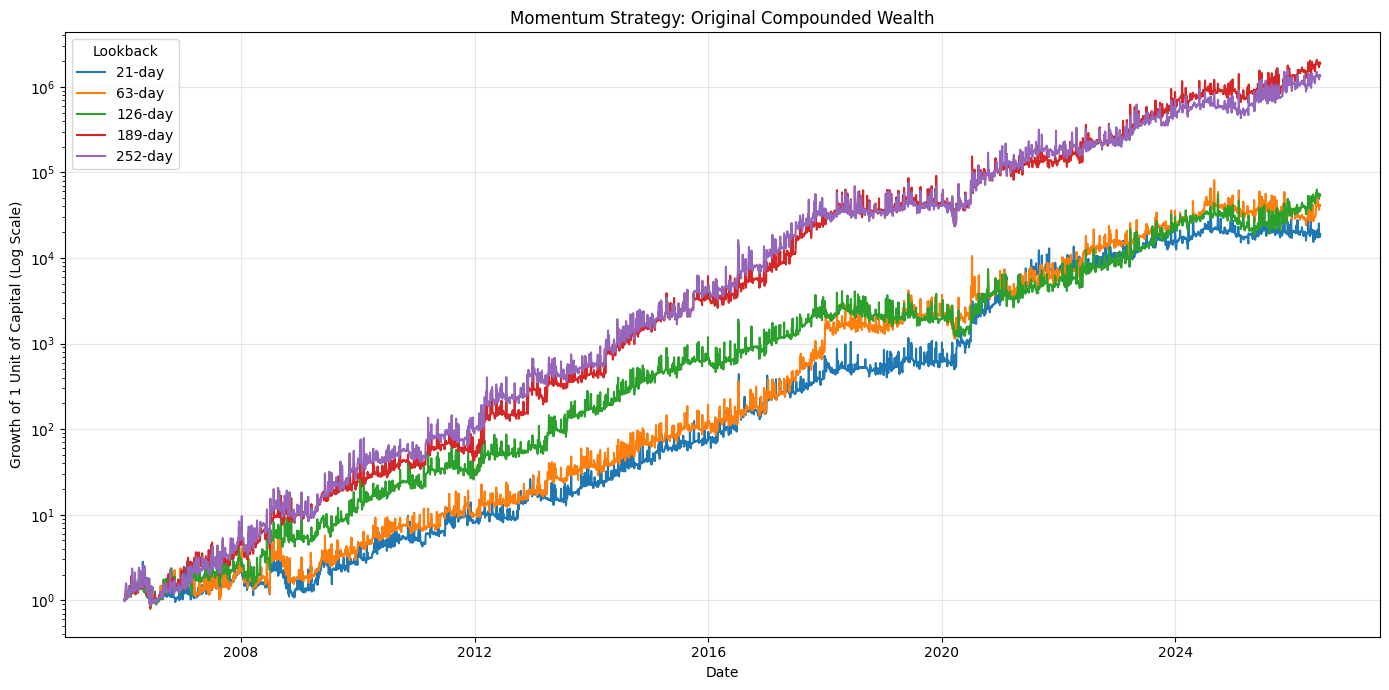

In [116]:
# Chart 1: Original challenge equity curves

plt.figure(figsize=(14, 7))

for lookback in lookbacks:
    plt.plot(
        original_equity_curves[lookback],
        label=f"{lookback}-day"
    )

plt.yscale("log")
plt.title("Momentum Strategy: Original Compounded Wealth")
plt.xlabel("Date")
plt.ylabel("Growth of 1 Unit of Capital (Log Scale)")
plt.legend(title="Lookback")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

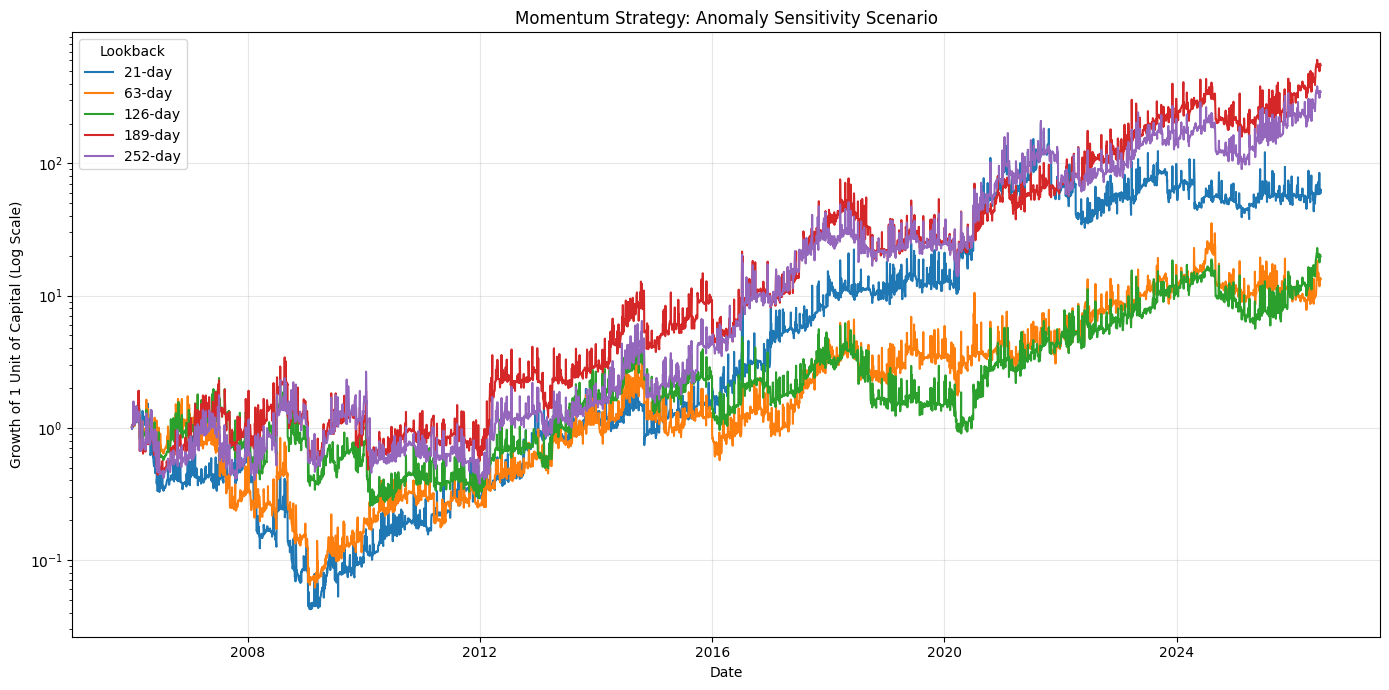

In [117]:
# Chart 2: Strict anomaly sensitivity equity curves

plt.figure(figsize=(14, 7))

for lookback in lookbacks:
    plt.plot(
        sensitivity_equity_curves[lookback],
        label=f"{lookback}-day"
    )

plt.yscale("log")
plt.title("Momentum Strategy: Anomaly Sensitivity Scenario")
plt.xlabel("Date")
plt.ylabel("Growth of 1 Unit of Capital (Log Scale)")
plt.legend(title="Lookback")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

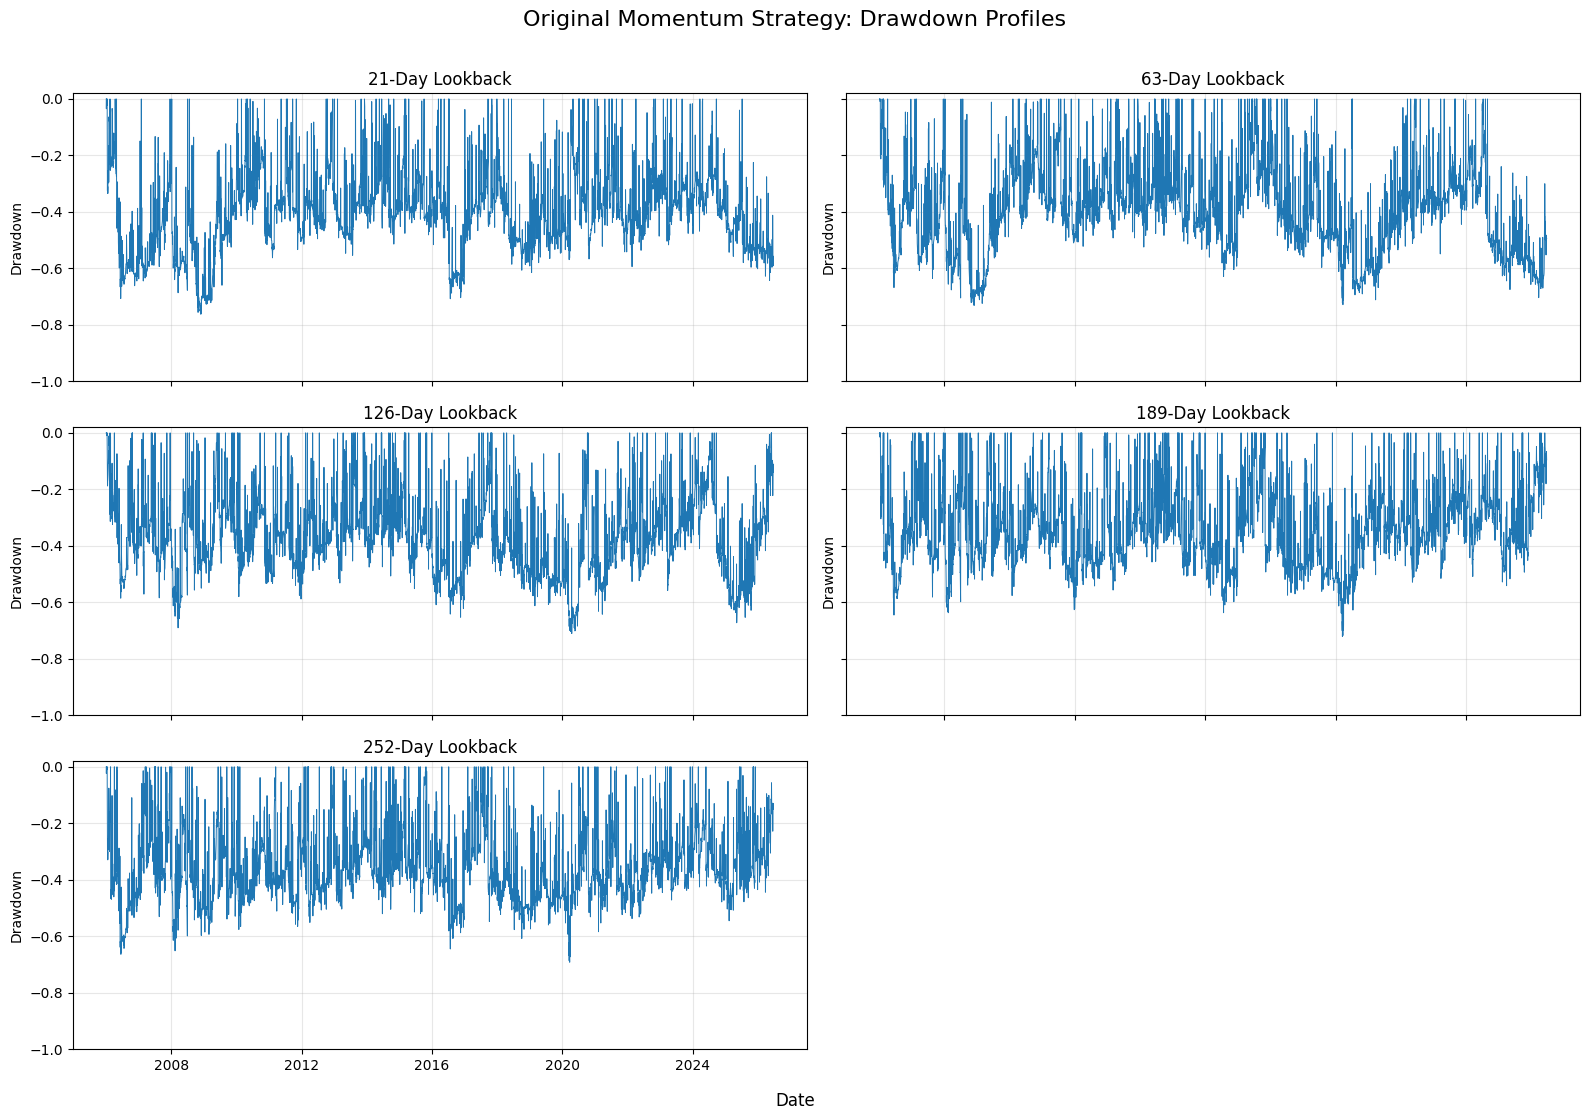

In [118]:
# Chart 3: Original strategy: individual drawdown panels

fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 11),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, lookback in enumerate(lookbacks):

    axes[i].plot(
        original_drawdowns[lookback],
        linewidth=0.7
    )

    axes[i].set_title(f"{lookback}-Day Lookback")
    axes[i].set_ylabel("Drawdown")
    axes[i].set_ylim(-1, 0.02)
    axes[i].grid(True, alpha=0.3)

# Remove unused sixth panel.
fig.delaxes(axes[5])

fig.suptitle(
    "Original Momentum Strategy: Drawdown Profiles",
    fontsize=16,
    y=1.01
)

fig.supxlabel("Date", fontsize=12)

plt.tight_layout()
plt.show()

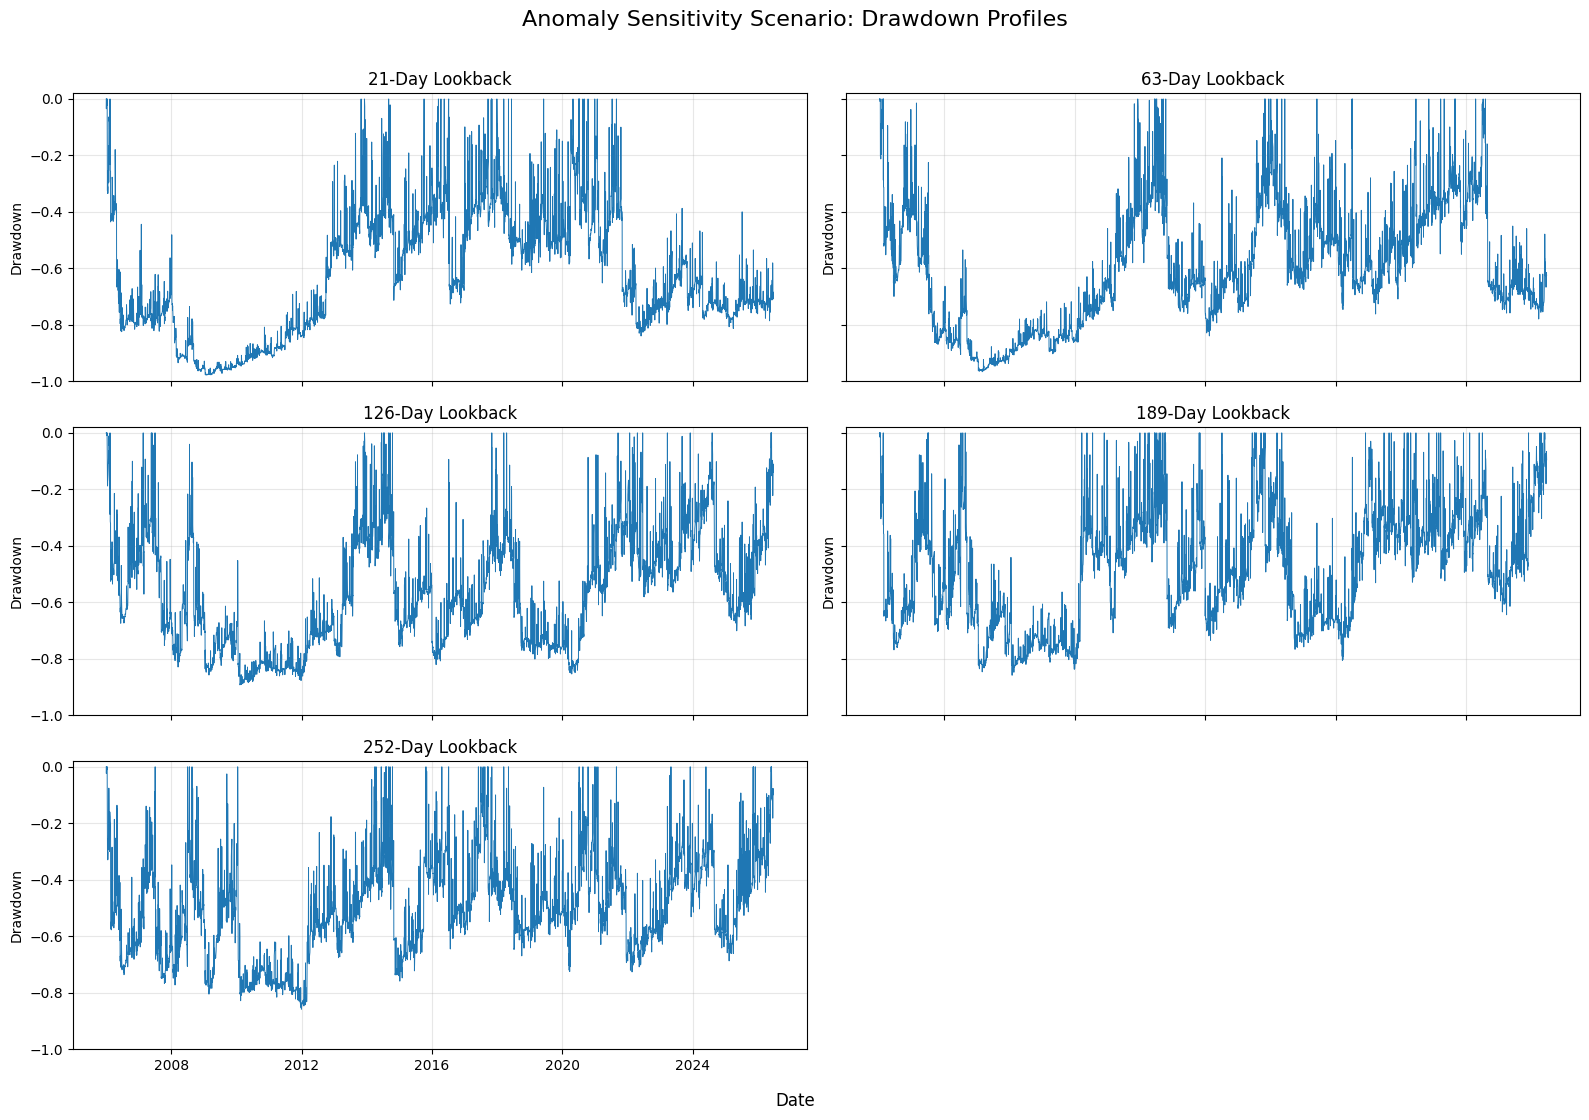

In [119]:
# Chart 4: Sensitivity scenario: individual drawdown panels

fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 11),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, lookback in enumerate(lookbacks):

    axes[i].plot(
        sensitivity_drawdowns[lookback],
        linewidth=0.7
    )

    axes[i].set_title(f"{lookback}-Day Lookback")
    axes[i].set_ylabel("Drawdown")
    axes[i].set_ylim(-1, 0.02)
    axes[i].grid(True, alpha=0.3)

# Remove unused sixth panel.
fig.delaxes(axes[5])

fig.suptitle(
    "Anomaly Sensitivity Scenario: Drawdown Profiles",
    fontsize=16,
    y=1.01
)

fig.supxlabel("Date", fontsize=12)

plt.tight_layout()
plt.show()

## **Final Findings and Limitations**

The **189-day lookback is the numerical winner** under the specified Sharpe-ratio objective. It produced the highest original annualised Sharpe ratio at **1.4532**, narrowly ahead of the 252-day lookback at **1.4523**. The difference is only 0.0009. The 189-day lookback also ranked first in the strict anomaly sensitivity scenario, with a Sharpe ratio of 1.2847 versus 1.2795 for the 252-day lookback, a similarly small difference of 0.0052.

These results do not establish that the 189-day strategy is a proven optimal or investable strategy. The supplied data contains recurring extreme stock-level returns and price-scale inconsistencies. Annualised volatility exceeded 260% across all five original configurations, and the resulting cumulative returns were exceptionally high.

The strict anomaly sensitivity analysis reduced the 189-day Sharpe ratio from 1.4532 to 1.2847 and its CAGR from 104.63% to 36.71%. This is a diagnostic scenario, not a corrected backtest: selected stock contributions were set to zero without reconstructing portfolio holdings or reallocating weights. Thousands of other extreme constituent observations also remained.

The backtest demonstrates that the required momentum-ranking, monthly portfolio-construction and return-calculation framework can be implemented and compared across the five prescribed lookbacks. However, the quality of the supplied price data does not support a reliable estimate of real-world investment performance. **The 189-day lookback should therefore be reported as the numerical winner in this dataset, not as a validated optimal investable strategy.** Independent verification and cleaning of the underlying market data would be required before drawing an investment conclusion.